# Group 10 - Exploratory Data Analysis (Deliverable 1)
## Amazing Creative Desk Coworking (ACDC) - customer segmentation

**Course**: Data Mining, NOVA IMS, Fall 2026-2027  |  **Group**: 10

**Members**
- Gustavo Carvalho `[student number]`
- Diogo Gaspar `[student number]`
- Mohamed Triki `[student number]`
- Vasco Vaz `[student number]`

### Business problem
ACDC wants to understand its members (value, behaviour, lifecycle) to design targeted offers and improve retention and revenue.
This notebook is **Deliverable 1 only**: it audits, cleans and explores `acdc_dataset.csv` (31 variables), engineers features and
states *hypotheses* about customer groups. **No clustering model is trained here** (that is Deliverable 2), so no accuracy or model-quality claim is made anywhere.

### Workflow (CRISP-DM: business understanding -> data understanding -> data preparation -> analysis)
1. Setup  2. Load and first look  3. Data-quality audit (including inter-field coherence)  4. Cleaning (evidence -> decision -> fix, with flags)
5. Univariate analysis (metric: histograms, boxplots and IQR fences; non-metric: countplots)  6. Bivariate analysis (metric x metric, category x category, within-group correlation)
7. Feature engineering  8. Engineered-feature exploration and feature redundancy  9. Multidimensional outliers and anomalies (bonus option 2)
10. Data-quality risks for clustering  11. Cluster hypotheses  12. Report figures  13. Results  14. Conclusions

### Conventions
Only techniques taught in the labs: `pandas`, `numpy`, `matplotlib` (object-oriented style), `seaborn`, and `scipy.spatial.distance.cdist` for Euclidean-distance reasoning.
Every cleaning action keeps a `flag_*` column so nothing is silently changed. Every figure is written by `save_show`/`save_slide` to `reports/figures/eda/` at dpi=200.
Every number quoted in the report pages and the docs is written to `data/processed/results.json` by this notebook; none of them is typed by hand.

### AI usage statement
AI usage statement: [TO BE COMPLETED BY THE GROUP: tools used, tasks, how outputs were verified]

All analysis, interpretations and recommendations in this deliverable must be the group's own. Every figure and number is produced by this notebook and recomputed independently by `src/verify.py` from `data/processed/acdc_cleaned.csv`.

# 1. Setup

In [1]:
"""Import libraries (all imports at the top, as in the labs) and set the plotting style.
"""
import os
import json
from math import ceil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist

# inline backend so that figures are stored inside the notebook outputs
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

sns.set_theme(style="whitegrid")
np.random.seed(42)

In [2]:
"""Define relative paths (os.path.join, run from notebooks/), colours, the documented plan-tier order, a results dictionary and a save-and-show helper.
"""
DATA_RAW = os.path.join("..", "data", "raw", "acdc_dataset.csv")
DATA_PROCESSED = os.path.join("..", "data", "processed", "acdc_cleaned.csv")
RESULTS_JSON = os.path.join("..", "data", "processed", "results.json")
FIGURES_DIR = os.path.join("..", "reports", "figures", "eda")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(os.path.dirname(DATA_PROCESSED), exist_ok=True)

BLUE, GRAY, LIGHT_BLUE = "#1F4E9C", "#8A8F98", "#9DB7E0"   # project palette: blue / gray / white
# plan_tier is ordinal, not nominal: the course dataset annex documents hot_desk < flex <
# dedicated_desk < full_time < private_office. The order and one sequential palette are defined
# here so every section displays the tier the same way (week 3: the scale decides what is
# admissible; week 4: one colour ramp, not a categorical rainbow, for an ordered variable).
tier_order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]     # documented order (annex)
TIER_COLORS = dict(zip(tier_order, sns.color_palette("Blues", 7)[2:]))
results = {}   # filled all along the notebook, saved at the very end


def save_show(fig, name):
    """Save a figure under reports/figures/eda (dpi=200) and display it inline.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure to write.
    name : str
        File name (PNG) inside FIGURES_DIR.
    """
    fig.savefig(os.path.join(FIGURES_DIR, name), dpi=200, bbox_inches="tight")
    plt.show()


def save_slide(fig, name):
    """Save a slide-sized figure (7.3 x 4.5 in) without font rescaling.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure already drawn at report-panel size.
    name : str
        File name (PNG) inside FIGURES_DIR.
    """
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURES_DIR, name), dpi=200)
    plt.show()


def label_missing(series, label="(missing)"):
    """Return a copy of a non-metric column in which absent values are their own level.

    Week 4 asks for missingness to be visible rather than silently shortening a bar
    chart, so every count plot shows "(missing)" as a category. The copy is written
    with a boolean mask instead of ``Series.fillna`` because pandas 2.x deprecates the
    silent downcasting of object-dtype arrays inside ``fillna``/``ffill``/``bfill``.

    Parameters
    ----------
    series : pd.Series
        Non-metric column (string, categorical, boolean or integer codes).
    label : str, default "(missing)"
        Level used for absent values.

    Returns
    -------
    pd.Series
        Object-dtype copy of ``series`` with no NaN left.
    """
    labelled = series.astype(object).copy()
    labelled[labelled.isna()] = label
    return labelled


print("raw data  :", DATA_RAW)
print("figures to:", FIGURES_DIR)

raw data  : ..\data\raw\acdc_dataset.csv
figures to: ..\reports\figures\eda


# 2. Loading the data and first look
Following lab03: shape, columns, `info()`, descriptive statistics. The file uses `;` as separator.

In [3]:
"""Read the raw CSV with pandas and show its shape and first rows.
"""
df = pd.read_csv(DATA_RAW, sep=";")
results["n_rows_original"] = int(df.shape[0])
results["n_columns"] = int(df.shape[1])
print(f"rows = {df.shape[0]:,} | columns = {df.shape[1]}")
df.head()

rows = 15,465 | columns = 31


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74


In [4]:
"""Inspect column names, non-null counts and dtypes with info().
"""
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  object 
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  object 
 3   industry                     15465 non-null  object 
 4   country                      15035 non-null  object 
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  object 
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  object 
 10  membership_end               15465 non-null  object 
 11  last_badge_swipe             15465 non-null  object 
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits    

In [5]:
"""Show the last rows and the dtype of every column, as lab03 does before any analysis.

`tail()` catches problems `head()` cannot: values that only appear at the end of the
export (sentinel codes, trailing blank records, a second date format). The dtype table is
printed on its own because `lifetime_value` arrives as text and `info()` alone makes that
easy to miss.
"""
display(df.tail())
df.dtypes.to_frame("dtype")

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
15460,CW009828,29.0,Female,Unknown,Spain,False,0,flex,3,2022-12-09,...,False,False,1,True,True,False,False,False,0,1422.36
15461,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,...,False,False,0,True,True,False,True,False,0,20683.24
15462,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,...,False,False,0,False,False,False,False,False,0,18.14
15463,CW013132,32.0,Female,Legal,Portugal,False,0,dedicated_desk,5,2021-08-28,...,True,False,1,False,True,True,True,False,4,11834.5
15464,CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,...,False,False,0,False,False,False,False,False,0,435.82


,dtype
member_id,object
age,float64
gender,object
industry,object
country,object
is_team_account,bool
n_colleagues_on_account,int64
plan_tier,object
plan_days_per_week,int64
membership_start,object


In [6]:
"""Descriptive statistics of the numeric columns (raw, before any cleaning).
"""
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.86,10.39,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.54,1.18,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.39,1.46,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.11,275.53,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.41,182.94,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.78,1.94,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.52,13.48,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.80,11.39,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.08,428.17,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.12,26.01,-13.5,0.00,0.00,0.00,602.80


In [7]:
"""Descriptive statistics of the text (object) columns.
"""
df.describe(include=["O"]).T

,count,unique,top,freq
member_id,15465,15450,CW005845,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


### Variable descriptions
Official descriptions come from the course dataset annex; the last column is what this notebook does with each variable.

| Theme | Variable | Description (course annex) | Treatment in this notebook |
|---|---|---|---|
| Identity and profile | `member_id` | Unique identifier of each member | unique after removing exact duplicates |
| Identity and profile | `age` | Age of the member at the extraction date | outside 18-100 -> NaN + flag |
| Identity and profile | `gender` | Gender of the member | spelling variants mapped to Female / Male / Other |
| Identity and profile | `country` | Country where the member (or their company) is based | variants mapped to 8 labels (incl. 'Other (Europe)') |
| Identity and profile | `industry` | Industry sector the member works in | variants mapped to 11 labels (incl. 'Unknown', 'Other') |
| Account and plan | `is_team_account` | Whether the membership is held by a team/company account | kept |
| Account and plan | `n_colleagues_on_account` | Number of colleagues sharing the account | -1 -> 0 (individual) / NaN (team) + flag |
| Account and plan | `plan_tier` | Current tier: hot_desk < flex < dedicated_desk < full_time < private_office | variants mapped to 5 tiers |
| Account and plan | `plan_days_per_week` | Days per week the plan entitles the member to use the space | 0 and 9 -> NaN + flag; 7 is valid (private_office) |
| Lifecycle and dates | `membership_start` | Date the membership first began | two formats parsed explicitly (day-first proven) |
| Lifecycle and dates | `membership_end` | Date the membership first ended | 1970-01-01 = sentinel for 'still active' |
| Lifecycle and dates | `last_badge_swipe` | Date of the most recent physical entry to the space | parsed like the other dates |
| Lifecycle and dates | `days_since_last_visit` | Days since the member's last recorded visit | 999 and negatives -> NaN + flag |
| Visit activity | `total_visits` | Total visits over the whole membership | negatives -> NaN + flag; extremes flagged |
| Visit activity | `avg_weekly_visits` | Average visits per week over the membership | kept |
| Visit activity | `entitled_visits_last_period` | Visits the plan entitled the member to in the last period | kept (denominator of utilization_rate) |
| Visit activity | `actual_visits_last_period` | Visits actually made in the last period | kept |
| Premium and add-on usage | `meeting_room_hours` | Hours of meeting-room usage | negatives -> NaN + flag; > 1000 flagged |
| Premium and add-on usage | `event_space_hours` | Hours of event-space usage | negatives -> NaN + flag |
| Premium and add-on usage | `guest_passes_issued` | Number of guest passes issued | negatives -> NaN + flag |
| Premium and add-on usage | `uses_meeting_rooms` | Ever used the meeting-room add-on | kept |
| Premium and add-on usage | `uses_event_space` | Ever used the event-space add-on | kept |
| Premium and add-on usage | `uses_guest_passes` | Ever used the guest-pass add-on | kept |
| Premium and add-on usage | `uses_print` | Used the print add-on | int -> bool |
| Premium and add-on usage | `uses_mail_handling` | Used the mail-handling add-on | kept |
| Premium and add-on usage | `uses_phone_booths` | Used the phone-booth add-on | kept |
| Premium and add-on usage | `uses_day_passes` | Used the day-pass add-on | kept |
| Premium and add-on usage | `uses_storage` | Used the storage add-on | kept |
| Premium and add-on usage | `uses_bike_locker` | Used the bike-locker add-on | kept |
| Loyalty and value | `n_renewals` | Number of times the membership was renewed | negatives -> NaN + flag |
| Loyalty and value | `lifetime_value` | Total revenue attributed to the member over the whole membership | '€' and ',' parsed; negatives and zeros -> NaN + flags |

### Variable typology (metric vs non-metric)
As in lab03/lab04 we separate the variables before analysing them. `lifetime_value` is text in the raw file and becomes metric after parsing.
Within the non-metric block the measurement scale still matters (week 3): `gender`, `industry` and `country` are **nominal** (no order is admissible),
while `plan_tier` is **ordinal** - the course dataset annex documents the order `hot_desk < flex < dedicated_desk < full_time < private_office`.
That is why `plan_tier` is always displayed in that documented order and coloured with a single sequential palette, never an unordered categorical one.

In [8]:
"""Define metric and non-metric feature lists and check they cover all 31 columns exactly once.

`non_metric_features` follows the lab03/lab04 idiom (the non-metric columns are listed and the
metric ones are what is left), and the two views are then cross-checked against each other, so a
column cannot silently fall into the wrong analysis track.
"""
metric_features = ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit", "total_visits",
                   "avg_weekly_visits", "entitled_visits_last_period", "actual_visits_last_period",
                   "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]
binary_features = ["is_team_account"] + [c for c in df.columns if c.startswith("uses_")]
categorical_features = ["gender", "industry", "country", "plan_tier"]
date_features = ["membership_start", "membership_end", "last_badge_swipe"]
id_feature = ["member_id"]

all_typed = metric_features + binary_features + categorical_features + date_features + id_feature
assert sorted(all_typed) == sorted(df.columns), "typology does not match the dataset columns"

# lab03/lab04 idiom: name the non-metric columns, and metric_features is what remains.
non_metric_features = binary_features + categorical_features + date_features + id_feature
derived_metric = [c for c in df.columns if c not in non_metric_features]
assert sorted(derived_metric) == sorted(metric_features), "metric/non-metric split does not partition the columns"

results["n_metric_features"] = len(metric_features)
results["n_non_metric_features"] = len(non_metric_features)
print({"metric": len(metric_features), "binary": len(binary_features), "categorical": len(categorical_features),
       "dates": len(date_features), "id": len(id_feature), "total": len(all_typed)})
print("metric == df.columns minus non-metric:", sorted(derived_metric) == sorted(metric_features))

{'metric': 13, 'binary': 10, 'categorical': 4, 'dates': 3, 'id': 1, 'total': 31}
metric == df.columns minus non-metric: True


# 3. Data-quality audit (raw data)
Checklist from lab03: duplicates, data types, missing values, strange values, descriptive statistics.
This section only *looks*; every decision and fix happens in Section 4, with a flag column.

## 3.1 Duplicates

In [9]:
"""Count exact duplicate rows and duplicated member_id values.
"""
n_dup_rows = int(df.duplicated().sum())
n_dup_ids = int(df["member_id"].duplicated().sum())
print(f"exact duplicate rows : {n_dup_rows} ({n_dup_rows / len(df):.2%})")
print(f"repeated member_id   : {n_dup_ids}")
assert df.drop_duplicates()["member_id"].is_unique, "member_id still repeated after dropping exact duplicates"
print("after dropping exact duplicates, member_id is unique: True")
results["n_duplicates_removed"] = n_dup_rows

exact duplicate rows : 15 (0.10%)


repeated member_id   : 15
after dropping exact duplicates, member_id is unique: True


## 3.2 Missing values and empty strings

In [10]:
"""Count NaN per column and look for empty strings that would hide missing values.
"""
missing = df.isna().sum()
missing_summary = pd.DataFrame({"missing": missing, "pct": (missing / len(df) * 100).round(2)})
print(missing_summary[missing_summary["missing"] > 0].sort_values("missing", ascending=False))

n_empty_strings = int((df.select_dtypes(include="object") == "").sum().sum())
print(f"\nempty strings in text columns: {n_empty_strings}")

                     missing   pct
meeting_room_hours      1298  8.39
guest_passes_issued     1271  8.22
lifetime_value          1040  6.72
age                      558  3.61
gender                   530  3.43
country                  430  2.78
plan_tier                105  0.68

empty strings in text columns: 0


## 3.3 Data types

In [11]:
"""Show the text formats hidden in lifetime_value and the dtypes of uses_* and date columns.
"""
has_euro = int(df["lifetime_value"].astype(str).str.contains("€", regex=False).sum())
has_comma = int(df["lifetime_value"].astype(str).str.contains(",", regex=False).sum())
print(f"lifetime_value with '€': {has_euro} | with ',' thousands separator: {has_comma}")
print(df["lifetime_value"].dropna().sample(8, random_state=42).tolist())
print()
print(df[[c for c in df.columns if c.startswith("uses_")]].dtypes)
print()
print(df[date_features].head(3))

lifetime_value with '€': 291 | with ',' thousands separator: 110
['2968.66', '0', '0', '8659.64', '13605.61', '2881.58', '420.9', '2259.18']

uses_meeting_rooms     bool
uses_event_space       bool
uses_guest_passes      bool
uses_print            int64
uses_mail_handling     bool
uses_phone_booths      bool
uses_day_passes        bool
uses_storage           bool
uses_bike_locker       bool
dtype: object

  membership_start membership_end last_badge_swipe
0       2021-08-01     2023-03-06       2023-03-23
1       2023-11-24     1970-01-01       2023-11-24
2       2021-12-03     1970-01-01       2023-07-22


## 3.4 Inter-field coherence
lab03 and lab05 ask for *incoherencies*, which are not visible column by column: two fields can each look valid and still
contradict each other. Each rule below compares two documented quantities, so a violation is a data problem and not a modelling choice.
`n_renewals` cannot exceed the number of months of membership, `actual_visits_last_period` cannot exceed `entitled_visits_last_period`,
and `days_since_last_visit` cannot disagree with `last_badge_swipe` about the same member.

In [12]:
"""Count contradictions between pairs of fields in the raw data.
"""
tenure_days_raw = (pd.to_datetime(df["membership_end"], format="%Y-%m-%d", errors="coerce")
                   - pd.to_datetime(df["membership_start"], format="%Y-%m-%d", errors="coerce")).dt.days
tenure_days_raw = (pd.to_datetime(df["membership_end"], format="%Y-%m-%d", errors="coerce")
                   - pd.to_datetime(df["membership_start"], format="%Y-%m-%d", errors="coerce")).dt.days
print(f"membership months usable for the renewal rule: {int(tenure_days_raw.notna().sum()):,} of {len(df):,} rows "
      f"(the rows in the second date format are unparseable here and are re-checked after Section 4.3)")
coherence_checks = pd.DataFrame({
    "rule": [
        "n_renewals > membership months (a renewal needs at least one month)",
        "actual_visits_last_period > entitled_visits_last_period",
        "entitled_visits_last_period == 0 while the member has visits",
        "days_since_last_visit is 999 (sentinel) ",
        "days_since_last_visit is negative (visit in the future)",
    ],
    "violations": [
        int((df["n_renewals"] > (tenure_days_raw / 30.44)).sum()),
        int((df["actual_visits_last_period"] > df["entitled_visits_last_period"]).sum()),
        int(((df["entitled_visits_last_period"] == 0) & (df["actual_visits_last_period"] > 0)).sum()),
        int((df["days_since_last_visit"] == 999).sum()),
        int((df["days_since_last_visit"] < 0).sum()),
    ],
})
coherence_checks["pct_of_rows"] = (coherence_checks["violations"] / len(df) * 100).round(2)
print(coherence_checks.to_string(index=False))

membership months usable for the renewal rule: 14,826 of 15,465 rows (the rows in the second date format are unparseable here and are re-checked after Section 4.3)
                                                               rule  violations  pct_of_rows
n_renewals > membership months (a renewal needs at least one month)        3938        25.46
            actual_visits_last_period > entitled_visits_last_period           8         0.05
       entitled_visits_last_period == 0 while the member has visits           8         0.05
                           days_since_last_visit is 999 (sentinel)         1298         8.39
            days_since_last_visit is negative (visit in the future)          56         0.36


### Audit summary (issues to treat in Section 4)
| Area | Issue seen in the raw data |
|---|---|
| Rows | exact duplicates |
| Text categories | spelling / case / language variants in `gender`, `country`, `industry`, `plan_tier` |
| Dates | stored as text, two formats mixed (`YYYY-MM-DD` and `DD/MM/YYYY`), sentinel `1970-01-01` in `membership_end` |
| Placeholders | `days_since_last_visit` = 999, `n_colleagues_on_account` = -1, `plan_days_per_week` in {0, 9}, `lifetime_value` = 0 (to be tested) |
| Impossible values | negative counts / hours / values, ages outside 18-100 |
| Types | `lifetime_value` text with `€` and `,`; `uses_print` int instead of bool |
| Tails | very large `lifetime_value`, `total_visits`, `meeting_room_hours` |
| Coherence | `n_renewals` above the membership length, visits above the plan entitlement, `entitled = 0` with visits recorded |

# 4. Data cleaning: evidence -> decision -> fix
Each step prints the evidence first, states the decision in words, then applies it on a copy (`df_clean`). The raw `df` is never modified.

## 4.1 Remove exact duplicates

In [13]:
"""Drop exact duplicate rows (keep first) into df_clean and assert member_id is unique.
"""
df_clean = df.drop_duplicates(keep="first").copy()
assert df_clean["member_id"].is_unique
results["n_rows_cleaned"] = int(len(df_clean))
print(f"rows before: {len(df):,} | after: {len(df_clean):,} | removed: {len(df) - len(df_clean)}")

rows before: 15,465 | after: 15,450 | removed: 15


## 4.2 Standardise text categories
Variants such as `FLEX`, `Flex ` or `Portucal` describe the same category. We normalise with an **explicit mapping** (strip + lower-case, then dictionary).
A helper asserts that **the number of NaN is the same before and after mapping**, so an unmapped variant can never silently turn into a missing value.
`Unknown` / `Other` (industry) and `Other (Europe)` (country) are genuine labels of the dataset and are kept as categories, not NaN.

In [14]:
"""Define a mapping helper that refuses to lose information (NaN count must not change).
"""
def standardise(series, mapping, name, replace_spaces=False):
    """Map spelling variants to canonical labels without changing the NaN count.

    Parameters
    ----------
    series : pandas.Series
        Raw category column.
    mapping : dict
        Lower-cased keys to canonical labels.
    name : str
        Column name, used in messages and asserts.
    replace_spaces : bool, default False
        If True, spaces in the key become underscores before mapping.

    Returns
    -------
    pandas.Series
        Mapped labels; original missing values stay missing.
    """
    key = series.str.strip().str.lower()
    if replace_spaces:
        key = key.str.replace(" ", "_", regex=False)
    mapped = key.map(mapping)
    nan_before, nan_after = int(series.isna().sum()), int(mapped.isna().sum())
    unmapped = sorted(key[mapped.isna() & key.notna()].unique())
    assert nan_before == nan_after, f"{name}: NaN {nan_before} -> {nan_after}; unmapped variants: {unmapped}"
    print(f"{name:10s} NaN before = {nan_before:4d} | after = {nan_after:4d} | distinct labels {series.nunique()} -> {mapped.nunique()}")
    return mapped


cat_cols = ["gender", "country", "industry", "plan_tier"]
raw_categories = df_clean[cat_cols].copy()      # kept to count how many rows were changed

In [15]:
"""Standardise gender.
"""
gender_mapping = {"female": "Female", "f": "Female", "male": "Male", "m": "Male", "other": "Other", "o": "Other"}
df_clean["gender"] = standardise(df_clean["gender"], gender_mapping, "gender")

gender     NaN before =  530 | after =  530 | distinct labels 12 -> 3


In [16]:
"""Standardise country, including the misspellings Portucal, Deutschland, U.K., Espana.
"""
country_mapping = {
    "portugal": "Portugal", "pt": "Portugal", "portucal": "Portugal",
    "germany": "Germany", "de": "Germany", "deutschland": "Germany",
    "united kingdom": "United Kingdom", "uk": "United Kingdom", "gb": "United Kingdom", "u.k.": "United Kingdom",
    "spain": "Spain", "es": "Spain", "españa": "Spain", "espana": "Spain",
    "france": "France", "fr": "France",
    "netherlands": "Netherlands", "the netherlands": "Netherlands", "nl": "Netherlands", "holland": "Netherlands",
    "ireland": "Ireland", "ie": "Ireland",
    "other (europe)": "Other (Europe)",
}
df_clean["country"] = standardise(df_clean["country"], country_mapping, "country")

country    NaN before =  429 | after =  429 | distinct labels 33 -> 8


In [17]:
"""Standardise industry, including Tech, Design/Creative, Marketing/PR, RealEstate and Real-Estate.
"""
industry_mapping = {
    "information technology": "Information Technology", "it": "Information Technology", "tech": "Information Technology",
    "consulting": "Consulting",
    "design & creative": "Design & Creative", "design/creative": "Design & Creative", "design and creative": "Design & Creative",
    "marketing & pr": "Marketing & PR", "marketing/pr": "Marketing & PR", "marketing and pr": "Marketing & PR",
    "finance": "Finance", "legal": "Legal", "education": "Education", "health": "Health",
    "real estate": "Real Estate", "realestate": "Real Estate", "real-estate": "Real Estate",
    "unknown": "Unknown", "other": "Other",
}
df_clean["industry"] = standardise(df_clean["industry"], industry_mapping, "industry")

industry   NaN before =    0 | after =    0 | distinct labels 43 -> 11


In [18]:
"""Standardise plan_tier (spaces become underscores first: 'Hot Desk' -> 'hot_desk').
"""
plan_mapping = {
    "flex": "flex",
    "hot_desk": "hot_desk", "hotdesk": "hot_desk",
    "dedicated_desk": "dedicated_desk", "dedicateddesk": "dedicated_desk",
    "full_time": "full_time", "fulltime": "full_time",
    "private_office": "private_office", "privateoffice": "private_office",
}
df_clean["plan_tier"] = standardise(df_clean["plan_tier"], plan_mapping, "plan_tier", replace_spaces=True)

plan_tier  NaN before =  105 | after =  105 | distinct labels 19 -> 5


In [19]:
"""Print value_counts(dropna=False) of every standardised category and count how many rows were changed.
"""
for c in cat_cols:
    print(f"--- {c}")
    print(df_clean[c].value_counts(dropna=False).to_string())
    print()

rows_with_variant = pd.Series(False, index=df_clean.index)
variants_fixed = {}
for c in cat_cols:
    changed = raw_categories[c].notna() & (raw_categories[c] != df_clean[c])
    variants_fixed[c] = int(changed.sum())
    rows_with_variant |= changed
results["category_variants_fixed"] = variants_fixed
results["rows_with_category_variant"] = int(rows_with_variant.sum())
results["rows_with_category_variant_pct"] = float(rows_with_variant.mean() * 100)
n_portugal = int((df_clean["country"] == "Portugal").sum())
results["n_portugal"] = n_portugal
results["top_country"] = df_clean["country"].value_counts().index[0]
results["top_country_pct"] = float(n_portugal / len(df_clean) * 100)                       # share of ALL rows
results["top_country_pct_of_known"] = float(n_portugal / df_clean["country"].notna().sum() * 100)   # share of rows with a country
results["top_industry"] = df_clean["industry"].value_counts().index[0]
results["top_plan_tier"] = df_clean["plan_tier"].value_counts().index[0]
print("rows changed per column:", variants_fixed)
print(f"Portugal: {n_portugal:,} of {len(df_clean):,} = {results['top_country_pct']:.1f}% of all rows ({results['top_country_pct_of_known']:.1f}% of the rows with a known country)")

--- gender
gender
Female    7858
Male      6565
NaN        530
Other      497

--- country
country
Portugal          10499
United Kingdom     1165
Germany             901
Spain               741
France              533
Netherlands         487
Other (Europe)      451
NaN                 429
Ireland             244

--- industry
industry
Information Technology    3557
Consulting                2055
Design & Creative         1974
Marketing & PR            1962
Finance                   1219
Other                     1175
Legal                      878
Education                  775
Unknown                    693
Health                     601
Real Estate                561

--- plan_tier
plan_tier
flex              5449
hot_desk          5212
full_time         2471
dedicated_desk    1549
private_office     664
NaN                105



rows changed per column: {'gender': 884, 'country': 776, 'industry': 1079, 'plan_tier': 768}
Portugal: 10,499 of 15,450 = 68.0% of all rows (69.9% of the rows with a known country)


In [20]:
"""Assert the final category sets (and that NaN counts equal the raw NaN counts).
"""
assert set(df_clean["gender"].dropna().unique()) == {"Female", "Male", "Other"}
assert set(df_clean["plan_tier"].dropna().unique()) == {"flex", "hot_desk", "dedicated_desk", "full_time", "private_office"}
assert set(df_clean["country"].dropna().unique()) == {"Portugal", "United Kingdom", "Germany", "Spain", "France",
                                                      "Netherlands", "Ireland", "Other (Europe)"}
assert df_clean["industry"].nunique() == 11
for c in cat_cols:
    assert df_clean[c].isna().sum() == raw_categories[c].isna().sum(), c
print("NaN after mapping equals NaN before mapping for gender, country, industry, plan_tier:",
      {c: int(df_clean[c].isna().sum()) for c in cat_cols})

NaN after mapping equals NaN before mapping for gender, country, industry, plan_tier: {'gender': 530, 'country': 429, 'industry': 0, 'plan_tier': 105}


## 4.3 Dates: two formats are mixed
About 4% of the dates are written `DD/MM/YYYY`, the rest `YYYY-MM-DD`. Before parsing we must prove from the **raw strings** that the slash format is day-first:
if some slash dates were `MM/DD/YYYY`, we would see values above 12 in the *second* position. We count both positions for the three date columns.

In [21]:
"""Count the date formats in the raw strings of each date column (still text at this point).
"""
df_clean["flag_date_format_dmy"] = False      # True if any of the three date strings uses DD/MM/YYYY
for col in date_features:
    s = df_clean[col].str.strip()
    n_slash = int(s.str.contains("/", regex=False).sum())
    n_iso = int(s.str.fullmatch(r"\d{4}-\d{2}-\d{2}").sum())
    print(f"{col:17s} DD/MM/YYYY = {n_slash:4d} ({n_slash / len(s):.1%}) | YYYY-MM-DD = {n_iso:5d} | other = {len(s) - n_slash - n_iso}")
    assert len(s) - n_slash - n_iso == 0, "unexpected date format"
    results[f"date_dmy_rows_{col}"] = n_slash
    df_clean["flag_date_format_dmy"] |= s.str.contains("/", regex=False)
results["rows_with_dmy_date"] = int(df_clean["flag_date_format_dmy"].sum())
print(f"rows with at least one DD/MM/YYYY date: {results['rows_with_dmy_date']:,} ({results['rows_with_dmy_date'] / len(df_clean):.1%})")

membership_start  DD/MM/YYYY =  637 (4.1%) | YYYY-MM-DD = 14813 | other = 0


membership_end    DD/MM/YYYY =  461 (3.0%) | YYYY-MM-DD = 14989 | other = 0
last_badge_swipe  DD/MM/YYYY =  637 (4.1%) | YYYY-MM-DD = 14813 | other = 0
rows with at least one DD/MM/YYYY date: 637 (4.1%)


In [22]:
"""Prove the day-first reading on the RAW slash strings: count first number > 12 and assert second number > 12 is zero.
"""
proof_rows = []
for col in date_features:
    s = df_clean[col].str.strip()
    parts = s[s.str.contains("/", regex=False)].str.split("/", expand=True).astype(int)
    first_gt12 = int((parts[0] > 12).sum())
    second_gt12 = int((parts[1] > 12).sum())
    proof_rows.append({"column": col, "slash_dates": len(parts), "first_number_gt_12": first_gt12,
                       "second_number_gt_12": second_gt12})
    assert second_gt12 == 0, f"{col}: found a second number > 12, day-first would be wrong"
    assert first_gt12 > 0
day_first_proof = pd.DataFrame(proof_rows)
print(day_first_proof.to_string(index=False))
print("\nsecond number > 12 never happens while first number > 12 happens often -> DD/MM/YYYY (day-first). Proof passed.")
results["day_first_proof"] = proof_rows

          column  slash_dates  first_number_gt_12  second_number_gt_12
membership_start          637                 366                    0
  membership_end          461                 276                    0
last_badge_swipe          637                 440                    0

second number > 12 never happens while first number > 12 happens often -> DD/MM/YYYY (day-first). Proof passed.


In [23]:
"""Parse each format explicitly (no guessing) and check that no date becomes NaT.
"""
def parse_mixed_dates(series):
    """Parse ISO (YYYY-MM-DD) and proven day-first slash dates in one column.

    Parameters
    ----------
    series : pandas.Series
        Date strings in mixed formats.

    Returns
    -------
    pandas.Series
        datetime64 values; callers assert there is no NaT.
    """
    s = series.str.strip()
    is_dmy = s.str.contains("/", regex=False)
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    out.loc[~is_dmy] = pd.to_datetime(s[~is_dmy], format="%Y-%m-%d")
    out.loc[is_dmy] = pd.to_datetime(s[is_dmy], format="%d/%m/%Y")
    return out


for col in date_features:
    df_clean[col] = parse_mixed_dates(df_clean[col])
print("NaT after parsing:", df_clean[date_features].isna().sum().to_dict())
print(df_clean[date_features].agg(["min", "max"]).T)
assert df_clean[date_features].isna().sum().sum() == 0

NaT after parsing: {'membership_start': 0, 'membership_end': 0, 'last_badge_swipe': 0}
                        min        max
membership_start 2021-01-01 2023-12-30
membership_end   1970-01-01 2024-01-01
last_badge_swipe 2020-09-06 2024-04-28


## 4.4 Placeholders and impossible numeric values
Rule: **never `abs()`**. A negative count is an error of unknown size, so it becomes NaN and gets a flag. Placeholders (999, -1) are handled by meaning.

In [24]:
"""Audit placeholders and impossible values before touching them (counts on the deduplicated data).
"""
neg_cols = ["total_visits", "n_renewals", "meeting_room_hours", "event_space_hours", "guest_passes_issued"]
audit_rows = [
    ("age < 18 or > 100", int(((df_clean["age"] < 18) | (df_clean["age"] > 100)).sum())),
    ("  of which age 1-14", int((df_clean["age"] < 15).sum())),
    ("  of which age 131-149", int((df_clean["age"] > 130).sum())),
    ("age between 15 and 17 or 101-130", int(((df_clean["age"].between(15, 17)) | (df_clean["age"].between(101, 130))).sum())),
    ("n_colleagues_on_account == -1", int((df_clean["n_colleagues_on_account"] == -1).sum())),
    ("days_since_last_visit == 999", int((df_clean["days_since_last_visit"] == 999).sum())),
    ("days_since_last_visit < 0", int((df_clean["days_since_last_visit"] < 0).sum())),
] + [(f"{c} < 0", int((df_clean[c] < 0).sum())) for c in neg_cols]
print(pd.DataFrame(audit_rows, columns=["check", "rows"]).to_string(index=False))

                           check  rows
               age < 18 or > 100   143
               of which age 1-14    98
            of which age 131-149    45
age between 15 and 17 or 101-130     0
   n_colleagues_on_account == -1   565
    days_since_last_visit == 999  1298
       days_since_last_visit < 0    56
                total_visits < 0    42
                  n_renewals < 0    66
          meeting_room_hours < 0    16
           event_space_hours < 0     8
         guest_passes_issued < 0     7


In [25]:
"""Apply the fixes with one flag column per rule: age outside 18-100 -> NaN; uses_print int -> bool.
"""
df_clean["flag_age_invalid"] = (df_clean["age"] < 18) | (df_clean["age"] > 100)
# The shape of the invalid values is the evidence for the 18-100 rule, so it is recorded rather than
# described from memory: how far out they go, and whether anything sits near a boundary.
invalid_age = df_clean.loc[df_clean["flag_age_invalid"], "age"]
results["age_invalid_n"] = int(len(invalid_age))
results["age_invalid_min"] = float(invalid_age.min())
results["age_invalid_max"] = float(invalid_age.max())
results["age_invalid_low_max"] = float(invalid_age[invalid_age < 18].max())
results["age_invalid_high_min"] = float(invalid_age[invalid_age > 100].min())
results["age_borderline_n"] = int(((df_clean["age"] >= 15) & (df_clean["age"] <= 17)).sum()
                                  + ((df_clean["age"] >= 101) & (df_clean["age"] <= 130)).sum())
assert results["age_borderline_n"] == 0, "the 18-100 rule has borderline cases; revisit the bound"
df_clean.loc[df_clean["flag_age_invalid"], "age"] = np.nan
print(f"age set to NaN: {results['age_invalid_n']} | impossible values run {results['age_invalid_min']:.0f}-"
      f"{results['age_invalid_low_max']:.0f} and {results['age_invalid_high_min']:.0f}-"
      f"{results['age_invalid_max']:.0f} | nothing between 15-17 or 101-130")
print(f"valid age range now: {df_clean['age'].min():.0f}-{df_clean['age'].max():.0f}")

assert set(df_clean["uses_print"].unique()) <= {0, 1}
df_clean["uses_print"] = df_clean["uses_print"].astype(bool)
print("uses_print dtype:", df_clean["uses_print"].dtype)

age set to NaN: 143 | impossible values run 1-14 and 131-149 | nothing between 15-17 or 101-130
valid age range now: 18-93
uses_print dtype: bool


In [26]:
"""Treat n_colleagues_on_account == -1 according to the account type.
"""
print(pd.crosstab(df_clean["is_team_account"], df_clean["n_colleagues_on_account"].clip(upper=6)))
df_clean["flag_n_colleagues_placeholder"] = df_clean["n_colleagues_on_account"] == -1
is_ind = ~df_clean["is_team_account"]
df_clean.loc[df_clean["flag_n_colleagues_placeholder"] & is_ind, "n_colleagues_on_account"] = 0
df_clean.loc[df_clean["flag_n_colleagues_placeholder"] & ~is_ind, "n_colleagues_on_account"] = np.nan
print(f"\n-1 handled: {int(df_clean['flag_n_colleagues_placeholder'].sum())} "
      f"(-> 0 for individuals: {int((df_clean['flag_n_colleagues_placeholder'] & is_ind).sum())}, "
      f"-> NaN for teams: {int((df_clean['flag_n_colleagues_placeholder'] & ~is_ind).sum())})")

n_colleagues_on_account   -1      0     1     2    3    4    5   6
is_team_account                                                   
False                    412  10688     0     0    0    0    0   0
True                     153      0  1758  1116  727  381  142  73

-1 handled: 565 (-> 0 for individuals: 412, -> NaN for teams: 153)


In [27]:
"""Set 999 and negative days_since_last_visit to NaN with a flag; set negative counts/hours to NaN with one flag each.
"""
n999 = int((df_clean["days_since_last_visit"] == 999).sum())
nneg = int((df_clean["days_since_last_visit"] < 0).sum())
df_clean["flag_days_since_last_visit_invalid"] = (df_clean["days_since_last_visit"] == 999) | (df_clean["days_since_last_visit"] < 0)
df_clean.loc[df_clean["flag_days_since_last_visit_invalid"], "days_since_last_visit"] = np.nan
print(f"days_since_last_visit: 999 -> {n999} rows, negative -> {nneg} rows, set to NaN: {int(df_clean['flag_days_since_last_visit_invalid'].sum())}")

for c in neg_cols:
    df_clean[f"flag_{c}_negative"] = df_clean[c] < 0
    df_clean.loc[df_clean[f"flag_{c}_negative"], c] = np.nan
    print(f"{c:22s} negative -> NaN: {int(df_clean[f'flag_{c}_negative'].sum())}")

days_since_last_visit: 999 -> 1298 rows, negative -> 56 rows, set to NaN: 1354
total_visits           negative -> NaN: 42
n_renewals             negative -> NaN: 66
meeting_room_hours     negative -> NaN: 16
event_space_hours      negative -> NaN: 8
guest_passes_issued    negative -> NaN: 7


## 4.5 Membership status and the reference (extraction) date
`membership_end = 1970-01-01` is a sentinel (Unix epoch) meaning *no end date*: the member is **active**. All other members have ended their membership.
The dataset has no extraction date, so we **derive** it: for active members `last_badge_swipe + days_since_last_visit` should land on the day the data was extracted.

> 74% ended is a share of members whose membership ended *within the three-year window*. It is **not** an annual churn rate and we never call it that.

In [28]:
"""Create is_active / status from the 1970-01-01 sentinel.
"""
df_clean["is_active"] = df_clean["membership_end"] == pd.Timestamp("1970-01-01")
df_clean["status"] = np.where(df_clean["is_active"], "active", "ended")
n_active, n_ended = int(df_clean["is_active"].sum()), int((~df_clean["is_active"]).sum())
results.update({"n_active": n_active, "n_churned": n_ended,
                "pct_active": float(n_active / len(df_clean) * 100), "pct_churned": float(n_ended / len(df_clean) * 100)})
# The window the file covers, stored here so the report pages and the playbook quote it as data
# instead of retyping a date range from memory.
by_start_year = df_clean["membership_start"].dt.year.value_counts().sort_index()
results.update({
    "window_first_membership_start": str(df_clean["membership_start"].min().date()),
    "window_last_membership_start": str(df_clean["membership_start"].max().date()),
    "members_by_start_year": {str(int(year)): int(n) for year, n in by_start_year.items()},
})
print(f"active = {n_active:,} ({results['pct_active']:.1f}%) | ended = {n_ended:,} ({results['pct_churned']:.1f}%)")
print(f"membership_start range: {results['window_first_membership_start']} -> {results['window_last_membership_start']}")
print("members by year of joining:", results["members_by_start_year"])

active = 3,954 (25.6%) | ended = 11,496 (74.4%)
membership_start range: 2021-01-01 -> 2023-12-30
members by year of joining: {'2021': 7626, '2022': 4449, '2023': 3375}


In [29]:
"""Derive the reference date as the mode of last_badge_swipe + days_since_last_visit among active members, and cross-check it.
"""
implied_date = df_clean["last_badge_swipe"] + pd.to_timedelta(df_clean["days_since_last_visit"], unit="D")
active_usable = df_clean["is_active"] & ~df_clean["flag_days_since_last_visit_invalid"]
print("most frequent implied dates (active members with a usable days_since_last_visit):")
print(implied_date[active_usable].value_counts().head(4).to_string())

reference_date = implied_date[active_usable].mode()[0]
max_real_end = df_clean.loc[~df_clean["is_active"], "membership_end"].max()
assert reference_date == max_real_end, (reference_date, max_real_end)
print(f"\nreference date = {reference_date.date()} (mode) = max(membership_end) among non-sentinel rows = {max_real_end.date()}")
results["reference_date"] = str(reference_date.date())
# Badge swipes continue past the reference date, which is why the last swipe in the file cannot be
# read as the extraction date. Stored as data so the decision table can quote the size of the gap.
last_swipe = df_clean["last_badge_swipe"].max()
results["window_last_badge_swipe"] = str(last_swipe.date())
results["swipe_days_past_reference"] = int((last_swipe - reference_date).days)
print(f"last badge swipe in the file: {results['window_last_badge_swipe']}, "
      f"{results['swipe_days_past_reference']} days past the reference date")

most frequent implied dates (active members with a usable days_since_last_visit):
2024-01-01    3288
2023-12-31     231
2023-12-28       4
2023-12-29       3

reference date = 2024-01-01 (mode) = max(membership_end) among non-sentinel rows = 2024-01-01
last badge swipe in the file: 2024-04-28, 118 days past the reference date


In [30]:
"""Compute the match rates between implied dates and the reference date (actives) / membership_end (ended), with denominators.
"""
n_act_usable = int(active_usable.sum())
n_exact = int((implied_date[active_usable] == reference_date).sum())
n_within1 = int(implied_date[active_usable].isin([reference_date, reference_date - pd.Timedelta(days=1)]).sum())

ended_usable = ~df_clean["is_active"] & ~df_clean["flag_days_since_last_visit_invalid"]
n_end_usable = int(ended_usable.sum())
n_end_match = int((implied_date[ended_usable] == df_clean.loc[ended_usable, "membership_end"]).sum())

results.update({
    "active_usable_n": n_act_usable, "active_exact_ref_n": n_exact, "active_within1_n": n_within1,
    "active_exact_ref_rate": float(n_exact / n_act_usable * 100), "active_within1_rate": float(n_within1 / n_act_usable * 100),
    "churned_usable_n": n_end_usable, "churned_match_n": n_end_match,
    "churned_match_rate": float(n_end_match / n_end_usable * 100),
})
print(f"active  : {n_exact:,} / {n_act_usable:,} = {results['active_exact_ref_rate']:.1f}% exactly on {reference_date.date()}")
print(f"active  : {n_within1:,} / {n_act_usable:,} = {results['active_within1_rate']:.1f}% on {reference_date.date()} or the day before it")
print(f"ended   : {n_end_match:,} / {n_end_usable:,} = {results['churned_match_rate']:.1f}% with last_badge_swipe + days_since_last_visit == membership_end")
print("\ndistribution of (implied - membership_end) in days for ended members:")
print((implied_date[ended_usable] - df_clean.loc[ended_usable, "membership_end"]).dt.days.value_counts().head(5).to_string())

active  : 3,288 / 3,573 = 92.0% exactly on 2024-01-01
active  : 3,519 / 3,573 = 98.5% on 2024-01-01 or the day before it
ended   : 9,855 / 10,523 = 93.7% with last_badge_swipe + days_since_last_visit == membership_end

distribution of (implied - membership_end) in days for ended members:
 0    9855
-1     221
 1     213
 5      11
-2       7


### What `days_since_last_visit` means (two different meanings)
* **Ended members**: the gap between the last visit and the day they left (their `membership_end`).
* **Active members**: the gap between the last visit and the reference date.

The two are different quantities, so we keep **two engineered recency variables** (`recency_days_active`, `recency_days_churned`) and never pool them silently.

## 4.6 Tenure (membership length)
`tenure_months = (end - start) / 30.44 days`, where *end* is `membership_end` for ended members and the reference date for active members. Values <= 0 are impossible and become NaN (flagged).

In [31]:
"""Compute tenure_months (guarded) and flag non-positive durations.
"""
end_for_tenure = df_clean["membership_end"].where(~df_clean["is_active"], reference_date)
tenure_raw = (end_for_tenure - df_clean["membership_start"]).dt.days / 30.44
df_clean["flag_tenure_nonpositive"] = tenure_raw <= 0
df_clean["tenure_months"] = tenure_raw.where(~df_clean["flag_tenure_nonpositive"])
print(f"end before start: {int((tenure_raw < 0).sum())} | end == start: {int((tenure_raw == 0).sum())} | set to NaN: {int(df_clean['flag_tenure_nonpositive'].sum())}")
print(df_clean["tenure_months"].describe().round(2).to_string())

end before start: 152 | end == start: 0 | set to NaN: 152
count    15298.00
mean        12.31
std         11.13
min          0.07
25%          2.14
50%          9.28
75%         20.93
max         35.97


## 4.7 `plan_days_per_week`: values 0 and 9 (and are 7 days valid?)

In [32]:
"""Test plan_days_per_week with evidence: entitled visits by plan days, and the crosstab with the standardised plan_tier.
"""
days_tbl = df_clean.groupby("plan_days_per_week")["entitled_visits_last_period"].agg(["count", "median", "min", "max"]).round(2)
days_tbl["median_per_plan_day"] = (days_tbl["median"] / days_tbl.index.to_series().replace(0, np.nan)).round(2)
print("entitled_visits_last_period by plan_days_per_week:")
print(days_tbl.to_string())
print("\nplan_tier x plan_days_per_week:")
print(pd.crosstab(label_missing(df_clean["plan_tier"]), df_clean["plan_days_per_week"]).to_string())

entitled_visits_last_period by plan_days_per_week:
                    count  median   min    max  median_per_plan_day
plan_days_per_week                                                 
0                      43   17.39  0.00  43.48                  NaN
2                    5183   17.39  0.87  17.39                 8.70
3                    5407   26.09  1.30  26.09                 8.70
5                    4045   43.48  2.17  43.48                 8.70
7                     718   60.87  3.04  60.87                 8.70
9                      54   75.26  2.73  78.27                 8.36

plan_tier x plan_days_per_week:
plan_days_per_week   0     2     3     5    7   9
plan_tier                                        
(missing)            0     0     0    49   56   0
dedicated_desk       3     0     0  1540    0   6
flex                20     0  5407     0    0  22
full_time            5     0     0  2456    0  10
hot_desk            14  5183     0     0    0  15
private_office       1

**Decision (plan days).**
* `plan_days_per_week == 0` is incoherent: those rows have positive entitled visits (their median equals a 2-day plan, their maximum a 5-day plan) and are spread over **all** tiers, so 0 is not a real "no-day" plan -> **NaN + flag**.
* `plan_days_per_week == 9` is impossible (a week has 7 days) -> **NaN + flag**.
* `plan_days_per_week == 7` is **valid**: in the crosstab it belongs only to `private_office` (and to rows whose tier is missing), which is the top, seven-day plan, and its entitlements are consistent with 7 days. Kept as is.

In [33]:
"""Apply the plan_days decision (0 and 9 -> NaN + flag, 7 kept).
"""
df_clean["flag_plan_days_invalid"] = df_clean["plan_days_per_week"].isin([0, 9])
n0, n9, n7 = (int((df_clean["plan_days_per_week"] == v).sum()) for v in (0, 9, 7))
df_clean.loc[df_clean["flag_plan_days_invalid"], "plan_days_per_week"] = np.nan
results.update({"plan_days_zero_n": n0, "plan_days_nine_n": n9, "plan_days_seven_n": n7})
print(f"plan_days 0: {n0} rows, 9: {n9} rows -> NaN; 7 kept: {n7} rows")
print(df_clean["plan_days_per_week"].value_counts(dropna=False).sort_index().to_string())

plan_days 0: 43 rows, 9: 54 rows -> NaN; 7 kept: 718 rows
plan_days_per_week
2.0    5183
3.0    5407
5.0    4045
7.0     718
NaN      97


## 4.8 `lifetime_value`: text parsing, negatives and zeros

In [34]:
"""Parse lifetime_value (strip '€', spaces and thousands commas), check that no value is lost, then flag negatives.
"""
ltv_text = df_clean["lifetime_value"].astype("string").str.replace("€", "", regex=False).str.replace(" ", "", regex=False).str.replace(",", "", regex=False).str.strip()
ltv_num = pd.to_numeric(ltv_text, errors="raise")
assert int(ltv_num.isna().sum()) == int(df_clean["lifetime_value"].isna().sum()), "parsing changed the number of NaN"
df_clean["lifetime_value"] = ltv_num.astype(float)
df_clean["flag_ltv_negative"] = df_clean["lifetime_value"] < 0
df_clean.loc[df_clean["flag_ltv_negative"], "lifetime_value"] = np.nan
print(f"parsed OK | negative -> NaN: {int(df_clean['flag_ltv_negative'].sum())} | NaN now: {int(df_clean['lifetime_value'].isna().sum())}")
print(df_clean["lifetime_value"].describe().round(2).to_string())

parsed OK | negative -> NaN: 82 | NaN now: 1122


count      14328.00
mean        6447.52
std        62965.32
min            0.00
25%          256.72
50%          859.22
75%         5100.66
max      3371260.00


### Zero lifetime value: real zero revenue or "unknown" placeholder?
If zeros were real (e.g. free trials, brand-new members) they would concentrate in short-tenure, few-renewal, low-tier rows. If zeros are a **placeholder for unknown revenue**, they would be spread like the whole population.
Three evidence tables follow.

In [35]:
"""Evidence 1 - share of zero-LTV rows per plan_tier versus share of all rows per plan_tier.
"""
is_zero = df_clean["lifetime_value"] == 0
n_zero = int(is_zero.sum())
tier_all = label_missing(df_clean["plan_tier"])
tier_cmp = pd.DataFrame({
    "pct_of_zero_rows": (tier_all[is_zero].value_counts(normalize=True) * 100).round(1),
    "pct_of_all_rows": (tier_all.value_counts(normalize=True) * 100).round(1),
})
tier_cmp["gap_pp"] = (tier_cmp["pct_of_zero_rows"] - tier_cmp["pct_of_all_rows"]).round(1)
print(f"rows with lifetime_value == 0: {n_zero:,} ({n_zero / len(df_clean):.1%})")
print(tier_cmp.to_string())

rows with lifetime_value == 0: 1,742 (11.3%)
                pct_of_zero_rows  pct_of_all_rows  gap_pp
plan_tier                                                
flex                        35.2             35.3    -0.1
hot_desk                    30.3             33.7    -3.4
full_time                   18.1             16.0     2.1
dedicated_desk              10.3             10.0     0.3
private_office               4.8              4.3     0.5
(missing)                    1.4              0.7     0.7


In [36]:
"""Evidence 2 - compare renewals, tenure, visits and status for zero versus non-zero lifetime value.
"""
nonzero = df_clean["lifetime_value"] > 0
cmp_cols = ["n_renewals", "tenure_months", "total_visits"]
zero_vs_non = pd.DataFrame({"zero_LTV": df_clean.loc[is_zero, cmp_cols].mean(), "non_zero_LTV": df_clean.loc[nonzero, cmp_cols].mean()}).round(2)
zero_vs_non.loc["pct_active"] = [round(df_clean.loc[is_zero, "is_active"].mean() * 100, 1), round(df_clean.loc[nonzero, "is_active"].mean() * 100, 1)]
print("means (pct_active in %):")
print(zero_vs_non.to_string())

means (pct_active in %):
               zero_LTV  non_zero_LTV
n_renewals         1.03          0.99
tenure_months     12.64         11.93
total_visits      96.78        108.95
pct_active        27.70         25.30


In [37]:
"""Evidence 3 - median non-zero LTV per tier next to the number of zero rows (private_office and dedicated_desk especially).
"""
tier_ev = pd.DataFrame({
    "rows": df_clean.groupby("plan_tier").size(),
    "zero_rows": is_zero.groupby(df_clean["plan_tier"]).sum().astype(int),
    "median_nonzero_LTV": df_clean.loc[nonzero].groupby("plan_tier")["lifetime_value"].median().round(0),
})
tier_ev["zero_pct_of_tier"] = (tier_ev["zero_rows"] / tier_ev["rows"] * 100).round(1)
print(tier_ev.to_string())

overall_zero_rate = n_zero / len(df_clean) * 100
max_rate_dev_pp = float((tier_ev["zero_pct_of_tier"] - overall_zero_rate).abs().max())
renewal_gap = float(abs(zero_vs_non.loc["n_renewals", "zero_LTV"] - zero_vs_non.loc["n_renewals", "non_zero_LTV"]))
not_newer = zero_vs_non.loc["tenure_months", "zero_LTV"] >= zero_vs_non.loc["tenure_months", "non_zero_LTV"]
zero_is_placeholder = (max_rate_dev_pp < 2.0) and (renewal_gap < 0.1) and bool(not_newer)
print(f"\noverall zero rate = {overall_zero_rate:.1f}% | zero rate per tier ranges {tier_ev['zero_pct_of_tier'].min():.1f}% - {tier_ev['zero_pct_of_tier'].max():.1f}%")
print(f"largest deviation of a tier from the overall rate = {max_rate_dev_pp:.1f} pp (threshold 2.0) | renewal gap = {renewal_gap:.2f} (threshold 0.10) | zero rows not newer than others: {bool(not_newer)}")
print("zero lifetime_value behaves like a placeholder for unknown revenue:", zero_is_placeholder)
results.update({"ltv_zero_rate_overall_pct": float(overall_zero_rate), "ltv_zero_rate_tier_min_pct": float(tier_ev["zero_pct_of_tier"].min()),
                "ltv_zero_rate_tier_max_pct": float(tier_ev["zero_pct_of_tier"].max()),
                "ltv_zero_renewals_mean": float(zero_vs_non.loc["n_renewals", "zero_LTV"]),
                "ltv_nonzero_renewals_mean": float(zero_vs_non.loc["n_renewals", "non_zero_LTV"]),
                "ltv_zero_private_office_n": int(tier_ev.loc["private_office", "zero_rows"]),
                "ltv_zero_dedicated_desk_n": int(tier_ev.loc["dedicated_desk", "zero_rows"]),
                "ltv_placeholder_evidence_supported": bool(zero_is_placeholder)})
# The three tests above are evidence, not an invariant: if the data ever stopped supporting the reading, the
# notebook reports it loudly instead of stopping, because the decision text below is what has to change.
if not zero_is_placeholder:
    print("WARNING: the evidence no longer supports the placeholder reading - revisit the decision text before using this run.")

                rows  zero_rows  median_nonzero_LTV  zero_pct_of_tier
plan_tier                                                            
dedicated_desk  1549        180             11026.0              11.6
flex            5449        613              1855.0              11.2
full_time       2471        315              5840.0              12.7
hot_desk        5212        527               356.0              10.1
private_office   664         83             21464.0              12.5

overall zero rate = 11.3% | zero rate per tier ranges 10.1% - 12.7%
largest deviation of a tier from the overall rate = 1.4 pp (threshold 2.0) | renewal gap = 0.04 (threshold 0.10) | zero rows not newer than others: True
zero lifetime_value behaves like a placeholder for unknown revenue: True


**Decision (zero lifetime value).** Every tier has a similar zero rate (the per-tier rates are printed above and stay close to the overall rate; hot_desk is slightly under-represented among the zeros, which we report rather than hide), zero and non-zero rows have the same mean renewals, zero rows are *not* newer members (their tenure is not shorter), and members of expensive tiers (private office, dedicated desk) show zero revenue although their typical revenue is in the thousands.
This pattern is what a **placeholder for unknown revenue** would produce, and it is the opposite of what free trials or brand-new members would produce. It is circumstantial evidence, not proof, so the rule is conservative and reversible: `lifetime_value == 0` becomes **NaN** with `flag_ltv_zero_as_missing`.
Consequence: the share of missing `lifetime_value` rises (see the next cell), and `ltv_per_month` and `value_per_visit` use **non-missing LTV only**.

In [38]:
"""Apply the zero-LTV decision and report how much lifetime_value is now missing.
"""
ltv_zeros_kept = df_clean["lifetime_value"].copy()           # sensitivity: headline statistics if the zeros were kept
results.update({
    "with_zeros_ltv_median": float(ltv_zeros_kept.median()), "with_zeros_ltv_mean": float(ltv_zeros_kept.mean()),
    "with_zeros_ltv_p99": float(ltv_zeros_kept.quantile(0.99)),
    "with_zeros_spearman": float(pd.DataFrame({"l": ltv_zeros_kept, "v": df_clean["total_visits"]}).corr(method="spearman").iloc[0, 1]),
})
df_clean["flag_ltv_zero_as_missing"] = df_clean["lifetime_value"] == 0
df_clean.loc[df_clean["flag_ltv_zero_as_missing"], "lifetime_value"] = np.nan
ltv_missing_n = int(df_clean["lifetime_value"].isna().sum())
results.update({"ltv_zero_n": n_zero, "ltv_negative_n": int(df_clean["flag_ltv_negative"].sum()),
                "ltv_raw_missing_n": int(df["lifetime_value"].isna().sum()),
                "ltv_missing_n": ltv_missing_n, "ltv_missing_pct": float(ltv_missing_n / len(df_clean) * 100)})
print(f"zero LTV -> NaN: {n_zero:,} | raw NaN: {results['ltv_raw_missing_n']:,} | negatives -> NaN: {results['ltv_negative_n']}")
print(f"lifetime_value missing now: {ltv_missing_n:,} = {results['ltv_missing_pct']:.1f}% of {len(df_clean):,} rows")
print(f"sensitivity - median / mean / P99 with the zeros KEPT: {results['with_zeros_ltv_median']:,.0f} / {results['with_zeros_ltv_mean']:,.0f} / {results['with_zeros_ltv_p99']:,.0f}; "
      f"with zeros as missing (final): {df_clean['lifetime_value'].median():,.0f} / {df_clean['lifetime_value'].mean():,.0f} / {df_clean['lifetime_value'].quantile(0.99):,.0f}")

zero LTV -> NaN: 1,742 | raw NaN: 1,040 | negatives -> NaN: 82
lifetime_value missing now: 2,864 = 18.5% of 15,450 rows
sensitivity - median / mean / P99 with the zeros KEPT: 859 / 6,448 / 25,680; with zeros as missing (final): 1,668 / 7,340 / 26,125


## 4.9 Logical-consistency flags (flag only, rows are kept)

In [39]:
"""Create consistency flags between dates, status, account type and numeric fields; no row is deleted.

The numeric rules repeat Section 3.4 on the cleaned, parsed columns, where the tenure is trustworthy.
A violation here is not an outlier: it is two fields describing the same member that cannot both be
true, so it is flagged and reported rather than silently corrected.
"""
df_clean["flag_end_before_start"] = ~df_clean["is_active"] & (df_clean["membership_end"] < df_clean["membership_start"])
df_clean["flag_swipe_before_start"] = df_clean["last_badge_swipe"] < df_clean["membership_start"]
df_clean["flag_swipe_after_end"] = ~df_clean["is_active"] & (df_clean["last_badge_swipe"] > df_clean["membership_end"])
df_clean["flag_swipe_after_reference"] = df_clean["is_active"] & (df_clean["last_badge_swipe"] > reference_date)
df_clean["flag_team_account_colleagues"] = ~df_clean["is_team_account"] & (df_clean["n_colleagues_on_account"] > 0)
df_clean["flag_renewals_exceed_tenure"] = df_clean["n_renewals"] > np.floor(df_clean["tenure_months"])
df_clean["flag_visits_exceed_entitlement"] = df_clean["actual_visits_last_period"] > df_clean["entitled_visits_last_period"]
df_clean["flag_no_entitlement_with_visits"] = (df_clean["entitled_visits_last_period"] == 0) & (df_clean["actual_visits_last_period"] > 0)
consistency_flags = [c for c in df_clean.columns if c.startswith("flag_") and c in
                     ["flag_end_before_start", "flag_swipe_before_start", "flag_swipe_after_end",
                      "flag_swipe_after_reference", "flag_team_account_colleagues",
                      "flag_renewals_exceed_tenure", "flag_visits_exceed_entitlement", "flag_no_entitlement_with_visits"]]
print(df_clean[consistency_flags].sum().to_string())
results.update({
    "flag_end_before_start_n": int(df_clean["flag_end_before_start"].sum()),
    "flag_swipe_before_start_n": int(df_clean["flag_swipe_before_start"].sum()),
    "flag_swipe_after_end_n": int(df_clean["flag_swipe_after_end"].sum()),
    "flag_swipe_after_reference_n": int(df_clean["flag_swipe_after_reference"].sum()),
    "flag_team_account_colleagues_n": int(df_clean["flag_team_account_colleagues"].sum()),
    "renewals_exceed_tenure_n": int(df_clean["flag_renewals_exceed_tenure"].sum()),
    "visits_exceed_entitlement_n": int(df_clean["flag_visits_exceed_entitlement"].sum()),
    "no_entitlement_with_visits_n": int(df_clean["flag_no_entitlement_with_visits"].sum()),
})

flag_end_before_start              152
flag_swipe_before_start             94
flag_swipe_after_end               213
flag_swipe_after_reference          27
flag_team_account_colleagues         0
flag_renewals_exceed_tenure        400
flag_visits_exceed_entitlement       8
flag_no_entitlement_with_visits      8


In [40]:
"""Explain what the two numeric contradictions do to the derived ratios, and record the decision.
"""
bad_renewal = df_clean["flag_renewals_exceed_tenure"]
print(f"rows with n_renewals above membership months : {int(bad_renewal.sum()):,}")
print("worst five of them (renewals and tenure in months):")
print(df_clean.loc[bad_renewal, ["member_id", "n_renewals", "tenure_months"]].sort_values("n_renewals", ascending=False).head(5).to_string(index=False))
print()
print(f"rows where visits exceed the plan entitlement : {results['visits_exceed_entitlement_n']:,} "
      f"of which entitled_visits_last_period == 0 : {results['no_entitlement_with_visits_n']:,}")
print("Decision: keep the rows, keep the flags, and never let a ratio silently hide the contradiction. utilization_rate is")
print("only defined when the plan entitled at least one visit, so the 0-entitlement rows are reported here instead of becoming infinite ratios.")
print("Consequence for clustering: any feature built on renewals or on the entitlement ratio must be computed on the")
print("unflagged subset or carried with its flag, otherwise these rows would define part of a cluster boundary.")

rows with n_renewals above membership months : 400
worst five of them (renewals and tenure in months):
member_id  n_renewals  tenure_months
 CW007181         6.0       2.562418
 CW009290         6.0       0.427070
 CW004947         6.0       0.755585
 CW012735         6.0       1.511170
 CW014776         5.0       2.168200

rows where visits exceed the plan entitlement : 8 of which entitled_visits_last_period == 0 : 8
Decision: keep the rows, keep the flags, and never let a ratio silently hide the contradiction. utilization_rate is
only defined when the plan entitled at least one visit, so the 0-entitlement rows are reported here instead of becoming infinite ratios.
Consequence for clustering: any feature built on renewals or on the entitlement ratio must be computed on the
unflagged subset or carried with its flag, otherwise these rows would define part of a cluster boundary.


## 4.10 Extreme values: kept, flagged, and their effect on distances
Extreme `lifetime_value` and `total_visits` are real-looking but huge. We keep them (deleting would be arbitrary), flag them, and measure how much they distort the statistics and Euclidean distance.

In [41]:
"""Flag extreme values and measure their effect on the mean and the Pearson correlation.
"""
df_clean["flag_ltv_extreme"] = df_clean["lifetime_value"] > 1_000_000
df_clean["flag_visits_extreme"] = df_clean["total_visits"] > 1000
df_clean["flag_meeting_hours_extreme"] = df_clean["meeting_room_hours"] > 1000
pair = ["lifetime_value", "total_visits"]
no_ext = ~(df_clean["flag_ltv_extreme"] | df_clean["flag_visits_extreme"])
results.update({
    "ltv_extreme_count": int(df_clean["flag_ltv_extreme"].sum()),
    "visits_extreme_count": int(df_clean["flag_visits_extreme"].sum()),
    "meeting_hours_extreme_count": int(df_clean["flag_meeting_hours_extreme"].sum()),
    "ltv_mean_without_extremes": float(df_clean.loc[~df_clean["flag_ltv_extreme"], "lifetime_value"].mean()),
    "pearson_without_extremes": float(df_clean.loc[no_ext, pair].corr().iloc[0, 1]),
})
print(f"LTV > 1M: {results['ltv_extreme_count']} rows | total_visits > 1000: {results['visits_extreme_count']} rows | meeting_room_hours > 1000: {results['meeting_hours_extreme_count']} rows")
print(f"LTV mean with extremes: {df_clean['lifetime_value'].mean():,.0f} | without: {results['ltv_mean_without_extremes']:,.0f}")
print(f"Pearson(LTV, visits) with extremes: {df_clean[pair].corr().iloc[0, 1]:.2f} | without: {results['pearson_without_extremes']:.2f}")

LTV > 1M: 17 rows | total_visits > 1000: 7 rows | meeting_room_hours > 1000: 19 rows
LTV mean with extremes: 7,340 | without: 5,178
Pearson(LTV, visits) with extremes: 0.15 | without: 0.17


In [42]:
"""Confirm the headline statistics on the cleaned data: quantiles and the three correlations (Pearson, Spearman, log-log).
"""
ltv, vis = df_clean["lifetime_value"], df_clean["total_visits"]
q = [0.5, 0.9, 0.99, 0.999, 1.0]
print("lifetime_value quantiles (50/90/99/99.9/100%):", ltv.quantile(q).round(0).tolist())
print("total_visits   quantiles (50/90/99/99.9/100%):", vis.quantile(q).round(0).tolist())
loglog = pd.DataFrame({"l": np.log1p(ltv), "v": np.log1p(vis)}).corr().iloc[0, 1]
results.update({
    "ltv_median": float(ltv.median()), "ltv_mean": float(ltv.mean()), "ltv_p90": float(ltv.quantile(0.9)),
    "ltv_p99": float(ltv.quantile(0.99)), "ltv_max": float(ltv.max()),
    "visits_median": float(vis.median()), "visits_mean": float(vis.mean()), "visits_p99": float(vis.quantile(0.99)), "visits_max": float(vis.max()),
    "correlation_pearson": float(df_clean[pair].corr().iloc[0, 1]),
    "correlation_spearman": float(df_clean[pair].corr(method="spearman").iloc[0, 1]),
    "correlation_loglog": float(loglog),
})
top1_share = ltv[ltv >= ltv.quantile(0.99)].sum() / ltv.sum() * 100
results["ltv_top1pct_revenue_share"] = float(top1_share)
print(f"median LTV = {results['ltv_median']:,.0f} | mean = {results['ltv_mean']:,.0f} | P99 = {results['ltv_p99']:,.0f} | max = {results['ltv_max']:,.0f}")
print(f"visits median = {results['visits_median']:.0f} | mean = {results['visits_mean']:.0f} | max = {results['visits_max']:,.0f}")
print(f"Pearson = {results['correlation_pearson']:.2f} | Spearman = {results['correlation_spearman']:.2f} | log-log = {results['correlation_loglog']:.2f}")
print(f"the top 1% of members (by LTV) hold {top1_share:.0f}% of the total known lifetime value")

lifetime_value quantiles (50/90/99/99.9/100%): [1668.0, 11989.0, 26125.0, 1207341.0, 3371260.0]
total_visits   quantiles (50/90/99/99.9/100%): [35.0, 374.0, 694.0, 884.0, 6530.0]
median LTV = 1,668 | mean = 7,340 | P99 = 26,125 | max = 3,371,260
visits median = 35 | mean = 111 | max = 6,530
Pearson = 0.15 | Spearman = 0.77 | log-log = 0.76
the top 1% of members (by LTV) hold 46% of the total known lifetime value


In [43]:
"""Compare each extreme lifetime_value with the monthly revenue normally seen in the same plan tier.
"""
tier_typical_ltv_pm = (df_clean["lifetime_value"] / df_clean["tenure_months"]).groupby(df_clean["plan_tier"]).transform("median")
ratio_to_tier = (df_clean["lifetime_value"] / df_clean["tenure_months"]) / tier_typical_ltv_pm
ext_ratio = ratio_to_tier[df_clean["flag_ltv_extreme"]].dropna()
rest_ratio = ratio_to_tier[~df_clean["flag_ltv_extreme"]].dropna()
ext_share = df_clean.loc[df_clean["flag_ltv_extreme"], "lifetime_value"].sum() / df_clean["lifetime_value"].sum() * 100
results.update({
    "ltv_extreme_ratio_median": float(ext_ratio.median()), "ltv_extreme_ratio_min": float(ext_ratio.min()), "ltv_extreme_ratio_max": float(ext_ratio.max()),
    "ltv_extreme_ratio_n": int(len(ext_ratio)),
    "ltv_normal_ratio_p99": float(rest_ratio.quantile(0.99)),
    "ltv_extreme_revenue_share_pct": float(ext_share),
})
print(f"extreme rows with a plan tier: {len(ext_ratio)} of {int(df_clean['flag_ltv_extreme'].sum())} | monthly revenue / tier median: median {ext_ratio.median():.0f}x, range {ext_ratio.min():.0f}x - {ext_ratio.max():.0f}x")
print(f"for all other members the 99th percentile of that ratio is {rest_ratio.quantile(0.99):.1f}x")
print(f"the {int(df_clean['flag_ltv_extreme'].sum())} extreme members hold {ext_share:.0f}% of all known lifetime value")

extreme rows with a plan tier: 15 of 17 | monthly revenue / tier median: median 110x, range 96x - 595x
for all other members the 99th percentile of that ratio is 5.4x
the 17 extreme members hold 30% of all known lifetime value


In [44]:
"""Euclidean-distance reasoning with scipy cdist: how much of a distance comes from each raw variable.
"""
dist_cols = ["lifetime_value", "total_visits", "tenure_months"]
base = df_clean[dist_cols].dropna()
typical = base.median().to_frame().T                              # a median member
high = base.quantile(0.90).to_frame().T                           # a high but ordinary member (P90 on each variable)
extreme = base.loc[[base["lifetime_value"].idxmax()]]             # the member with the largest lifetime value
d_typ_high = float(cdist(typical, high)[0, 0])
d_typ_ext = float(cdist(typical, extreme)[0, 0])
contrib = pd.DataFrame({
    "typical->high (P90)": ((typical.values - high.values) ** 2 / ((typical.values - high.values) ** 2).sum() * 100).ravel(),
    "typical->most extreme": ((typical.values - extreme.values) ** 2 / ((typical.values - extreme.values) ** 2).sum() * 100).ravel(),
}, index=dist_cols).round(2)
results.update({"dist_typical_to_p90": d_typ_high, "dist_typical_to_extreme": d_typ_ext,
                "dist_ltv_share_typ_p90_pct": float(contrib.loc["lifetime_value", "typical->high (P90)"]),
                "dist_ltv_share_typ_ext_pct": float(contrib.loc["lifetime_value", "typical->most extreme"])})
print(f"Euclidean distance typical -> P90 member : {d_typ_high:,.0f}")
print(f"Euclidean distance typical -> most extreme: {d_typ_ext:,.0f}")
print("\nshare of the squared distance contributed by each variable (%):")
print(contrib.to_string())

Euclidean distance typical -> P90 member : 10,327
Euclidean distance typical -> most extreme: 3,369,597

share of the squared distance contributed by each variable (%):
                typical->high (P90)  typical->most extreme
lifetime_value                 99.9                  100.0
total_visits                    0.1                    0.0
tenure_months                   0.0                    0.0


**Mitigation to carry into Deliverable 2** (not applied here, because D1 trains nothing): put variables on comparable scales and tame the tails (log transform of the heavy-tailed variables, or work with percentile ranks) before any distance-based method; keep flags to decide how to treat missing values.

## 4.11 Cleaning log and missingness after cleaning

In [45]:
"""Build the cleaning log from the flag columns (every count is computed, none typed by hand).
"""
n = len(df_clean)
log_rows = [
    ("Exact duplicate rows", "all", results["n_duplicates_removed"], "dropped (keep first)"),
    ("Category spelling variants", "gender/country/industry/plan_tier", results["rows_with_category_variant"], "explicit mapping + NaN-preservation assert"),
    ("DD/MM/YYYY date strings (any date column)", "dates", results["rows_with_dmy_date"], "parsed day-first (proof above)"),
    ("Sentinel membership_end 1970-01-01", "membership_end", int(df_clean["is_active"].sum()), "is_active = True"),
    ("Age outside 18-100", "age", int(df_clean["flag_age_invalid"].sum()), "NaN + flag"),
    ("n_colleagues_on_account = -1", "n_colleagues_on_account", int(df_clean["flag_n_colleagues_placeholder"].sum()), "0 (individual) / NaN (team) + flag"),
    ("days_since_last_visit 999 or negative", "days_since_last_visit", int(df_clean["flag_days_since_last_visit_invalid"].sum()), "NaN + flag"),
    ("Negative total_visits", "total_visits", int(df_clean["flag_total_visits_negative"].sum()), "NaN + flag"),
    ("Negative n_renewals", "n_renewals", int(df_clean["flag_n_renewals_negative"].sum()), "NaN + flag"),
    ("Negative meeting_room_hours", "meeting_room_hours", int(df_clean["flag_meeting_room_hours_negative"].sum()), "NaN + flag"),
    ("Negative event_space_hours", "event_space_hours", int(df_clean["flag_event_space_hours_negative"].sum()), "NaN + flag"),
    ("Negative guest_passes_issued", "guest_passes_issued", int(df_clean["flag_guest_passes_issued_negative"].sum()), "NaN + flag"),
    ("plan_days_per_week 0 or 9", "plan_days_per_week", int(df_clean["flag_plan_days_invalid"].sum()), "NaN + flag (7 kept)"),
    ("Negative lifetime_value", "lifetime_value", int(df_clean["flag_ltv_negative"].sum()), "NaN + flag"),
    ("Zero lifetime_value (placeholder)", "lifetime_value", int(df_clean["flag_ltv_zero_as_missing"].sum()), "NaN + flag_ltv_zero_as_missing"),
    ("Non-positive tenure", "tenure_months", int(df_clean["flag_tenure_nonpositive"].sum()), "NaN + flag"),
    ("Membership end before start", "dates", int(df_clean["flag_end_before_start"].sum()), "flag only"),
    ("Last swipe before start", "dates", int(df_clean["flag_swipe_before_start"].sum()), "flag only"),
    ("Last swipe after end (ended)", "dates", int(df_clean["flag_swipe_after_end"].sum()), "flag only"),
    ("Last swipe after reference (active)", "dates", int(df_clean["flag_swipe_after_reference"].sum()), "flag only"),
    ("Extreme lifetime_value > 1M", "lifetime_value", int(df_clean["flag_ltv_extreme"].sum()), "kept + flag"),
    ("Extreme total_visits > 1000", "total_visits", int(df_clean["flag_visits_extreme"].sum()), "kept + flag"),
    ("Extreme meeting_room_hours > 1000", "meeting_room_hours", int(df_clean["flag_meeting_hours_extreme"].sum()), "kept + flag"),
]
cleaning_log = pd.DataFrame(log_rows, columns=["issue", "column", "rows", "action"])
cleaning_log["pct_of_rows"] = (cleaning_log["rows"] / n * 100).round(2)
cleaning_log.loc[0, "pct_of_rows"] = round(results["n_duplicates_removed"] / results["n_rows_original"] * 100, 2)
results["cleaning_log_rows"] = {row.issue: int(row.rows) for row in cleaning_log.itertuples()}
results["n_days_999"], results["n_days_negative"] = n999, nneg
cleaning_log

,issue,column,rows,action,pct_of_rows
0,Exact duplicate rows,all,15,dropped (keep first),0.10
1,Category spelling variants,gender/country/industry/plan_tier,3238,explicit mapping + NaN-preservation assert,20.96
2,DD/MM/YYYY date strings (any date column),dates,637,parsed day-first (proof above),4.12
3,Sentinel membership_end 1970-01-01,membership_end,3954,is_active = True,25.59
4,Age outside 18-100,age,143,NaN + flag,0.93
5,n_colleagues_on_account = -1,n_colleagues_on_account,565,0 (individual) / NaN (team) + flag,3.66
6,days_since_last_visit 999 or negative,days_since_last_visit,1354,NaN + flag,8.76
7,Negative total_visits,total_visits,42,NaN + flag,0.27
8,Negative n_renewals,n_renewals,66,NaN + flag,0.43
9,Negative meeting_room_hours,meeting_room_hours,16,NaN + flag,0.10


In [46]:
"""Report missing values in the original 31 columns after cleaning.
"""
orig_cols = list(df.columns)
missing_after = (df_clean[orig_cols].isna().mean() * 100).round(2)
missing_after = missing_after[missing_after > 0].sort_values(ascending=False)
print(missing_after.to_string())
results["missing_pct_after_cleaning"] = {k: float(v) for k, v in missing_after.items()}

lifetime_value             18.54
days_since_last_visit       8.76
meeting_room_hours          8.49
guest_passes_issued         8.26
age                         4.53
gender                      3.43
country                     2.78
n_colleagues_on_account     0.99
plan_tier                   0.68
plan_days_per_week          0.63
n_renewals                  0.43
total_visits                0.27
event_space_hours           0.05


# 5. Univariate analysis
Lab04 tools: histograms and boxplots for the metric variables, bar charts for the categories. Heavy tails are expected, so we also use log scales.

In [47]:
"""Descriptive statistics (with P1/P99) of the cleaned metric variables.
"""
metric_clean = [c for c in metric_features]
df_clean[metric_clean].describe(percentiles=[0.01, 0.5, 0.99]).round(2).T

,count,mean,std,min,1%,50%,99%,max
age,14750.0,34.75,8.39,18.0,19.00,34.00,55.00,93.00
n_colleagues_on_account,15297.0,0.58,1.15,0.0,0.00,0.00,5.00,9.00
plan_days_per_week,15353.0,3.38,1.41,2.0,2.00,3.00,7.00,7.00
days_since_last_visit,14096.0,37.30,67.61,0.0,1.00,10.00,294.00,1212.00
total_visits,15408.0,110.78,183.03,0.0,1.00,35.00,693.93,6530.00
avg_weekly_visits,15450.0,1.78,1.94,0.0,0.04,1.42,5.32,47.40
entitled_visits_last_period,15450.0,27.51,13.48,0.0,2.65,26.09,60.87,78.27
actual_visits_last_period,15450.0,13.80,11.39,0.0,0.00,10.00,43.51,60.00
meeting_room_hours,14139.0,33.14,428.59,0.0,0.00,0.00,326.80,41220.00
event_space_hours,15442.0,5.12,26.03,0.0,0.00,0.00,127.44,602.80


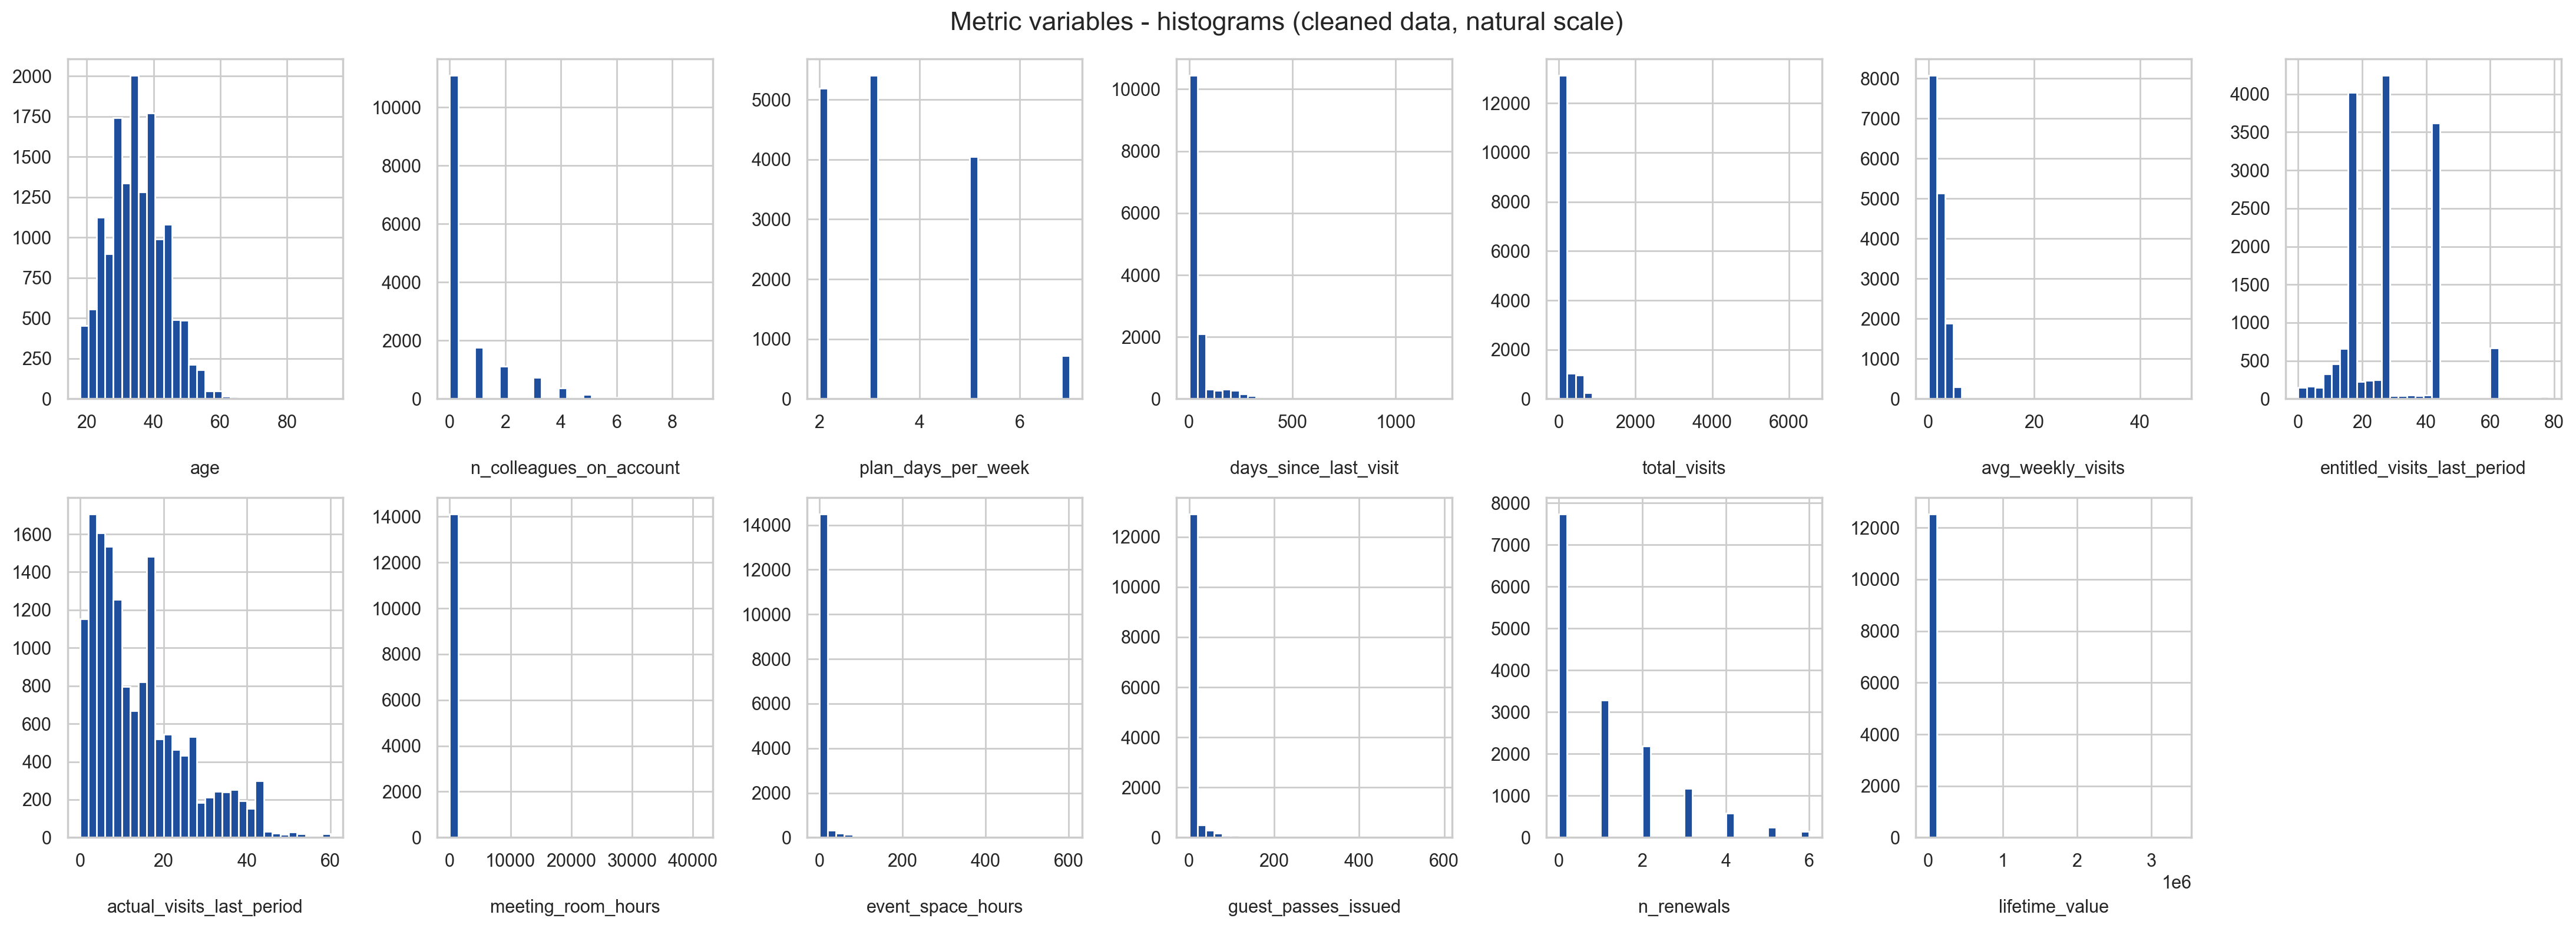

In [48]:
"""Histogram grid of all metric variables on their natural scale (lab04 style, object-oriented matplotlib).
"""
fig, axes = plt.subplots(2, ceil(len(metric_clean) / 2), figsize=(22, 8))
for ax, feat in zip(axes.flatten(), metric_clean):
    ax.hist(df_clean[feat].dropna(), bins=30, color=BLUE)
    ax.set_title(feat, y=-0.25, fontsize=11)
for ax in axes.flatten()[len(metric_clean):]:
    ax.set_visible(False)
fig.suptitle("Metric variables - histograms (cleaned data, natural scale)", fontsize=16)
fig.tight_layout()
save_show(fig, "numeric_histograms.png")

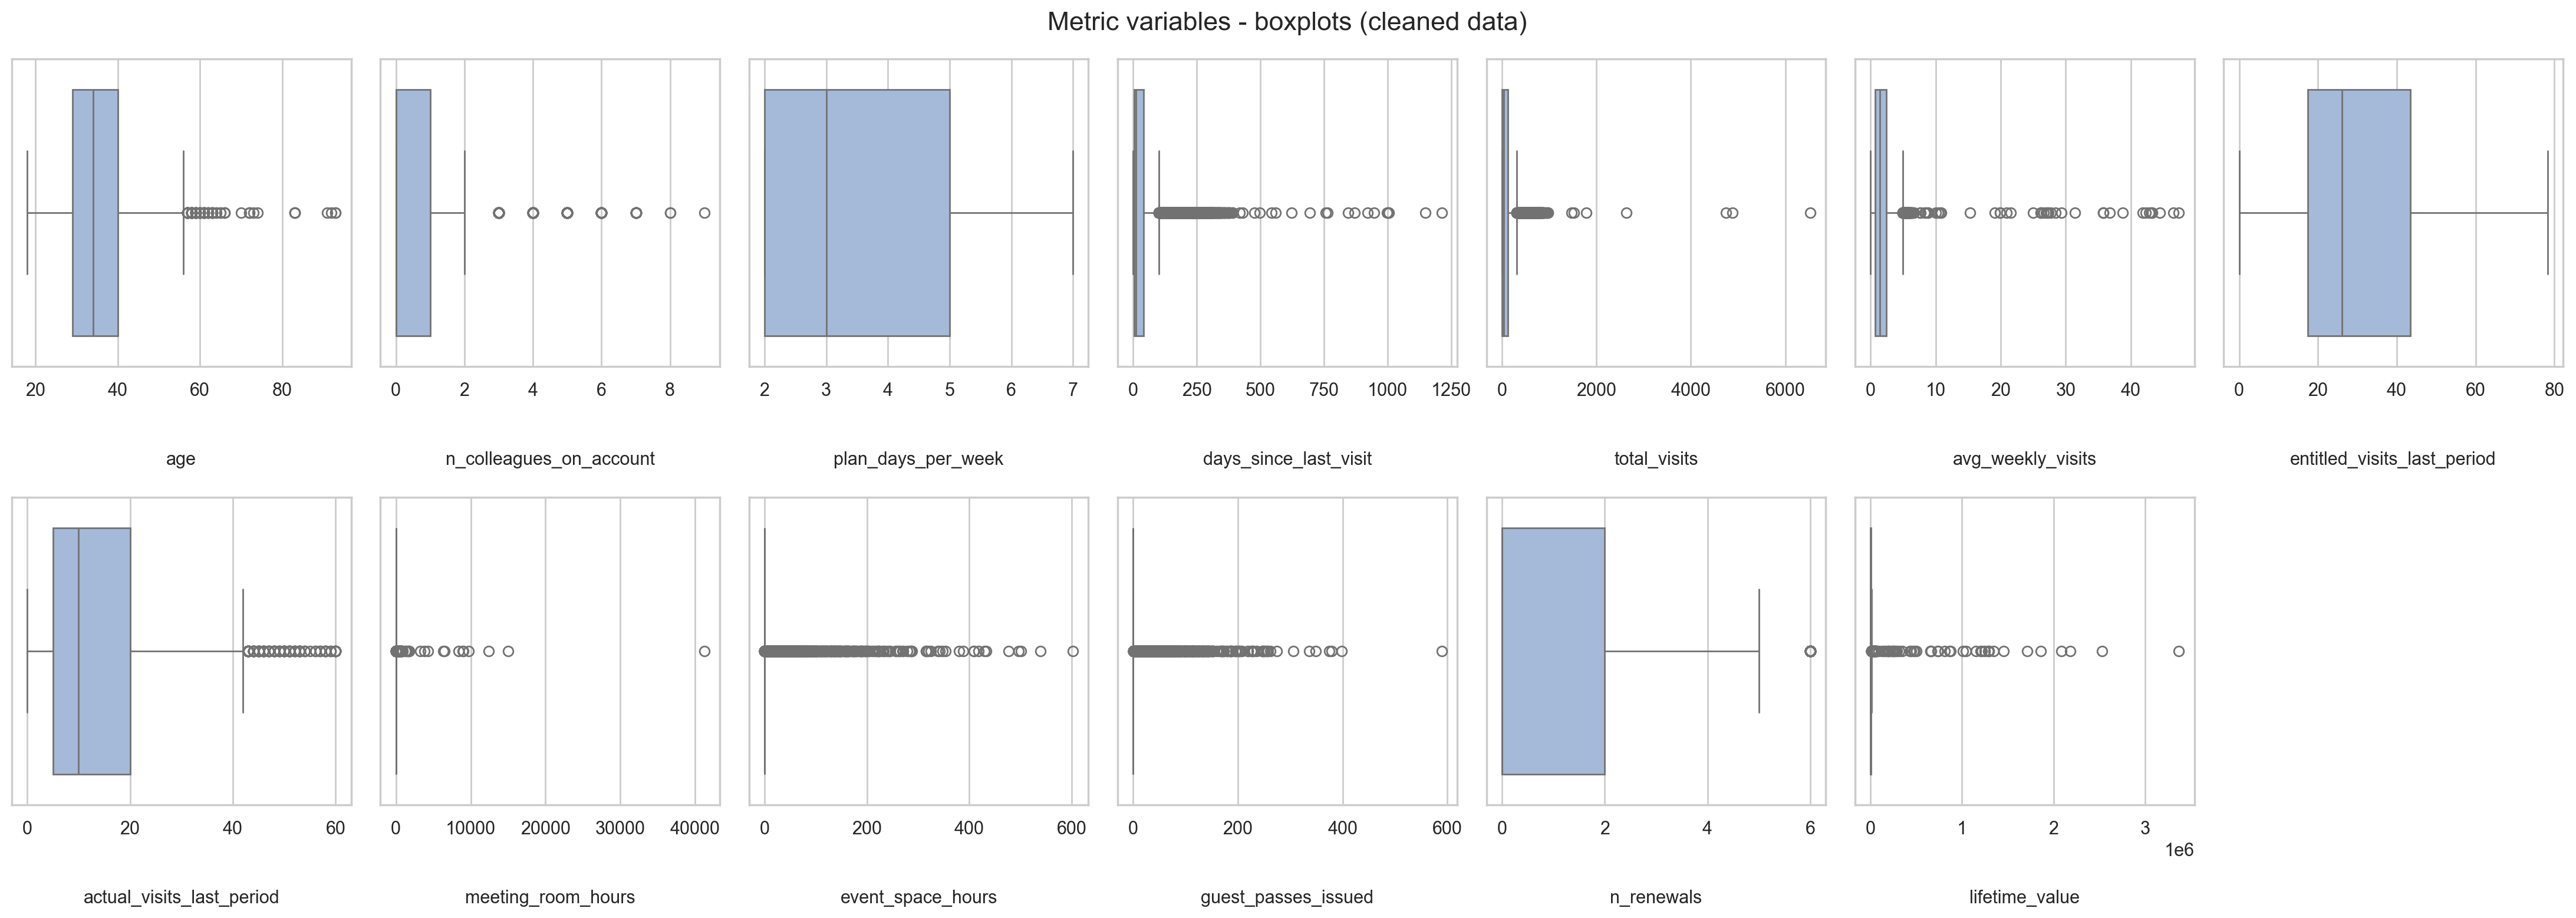

In [49]:
"""Boxplot grid of the metric variables.
"""
fig, axes = plt.subplots(2, ceil(len(metric_clean) / 2), figsize=(22, 8))
for ax, feat in zip(axes.flatten(), metric_clean):
    sns.boxplot(x=df_clean[feat], ax=ax, color=LIGHT_BLUE)
    ax.set_title(feat, y=-0.35, fontsize=11)
    ax.set_xlabel("")
for ax in axes.flatten()[len(metric_clean):]:
    ax.set_visible(False)
fig.suptitle("Metric variables - boxplots (cleaned data)", fontsize=16)
fig.tight_layout()
save_show(fig, "numeric_boxplots.png")

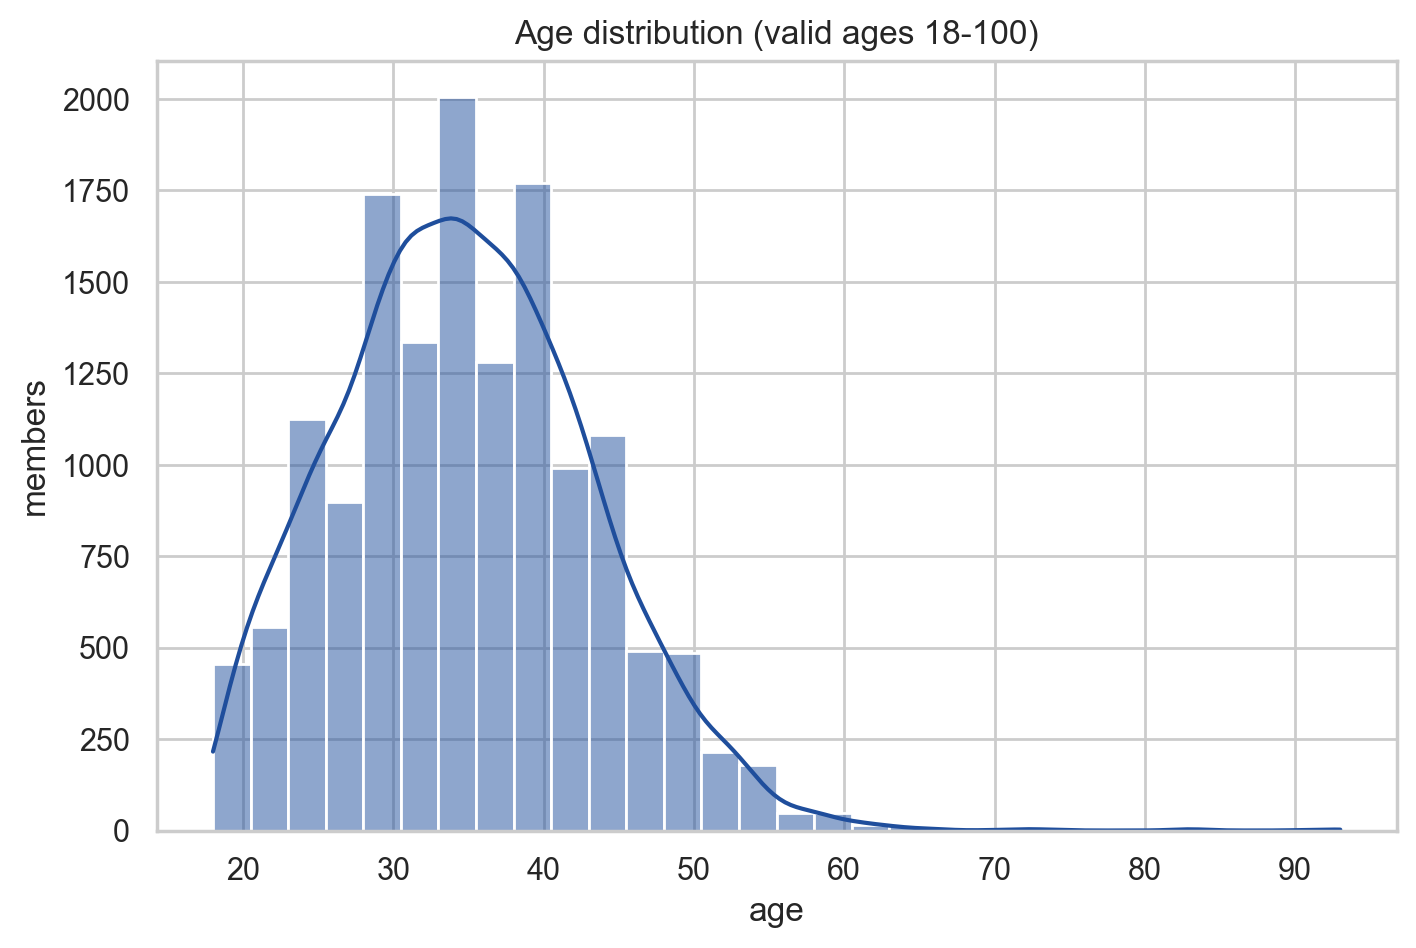

median age = 34 | valid ages: 14,750


In [50]:
"""Age histogram with density curve.
"""
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df_clean["age"], bins=30, kde=True, color=BLUE, ax=ax)
ax.set(title="Age distribution (valid ages 18-100)", xlabel="age", ylabel="members")
save_show(fig, "age_distribution.png")
results["age_median"] = float(df_clean["age"].median())
print(f"median age = {results['age_median']:.0f} | valid ages: {int(df_clean['age'].notna().sum()):,}")

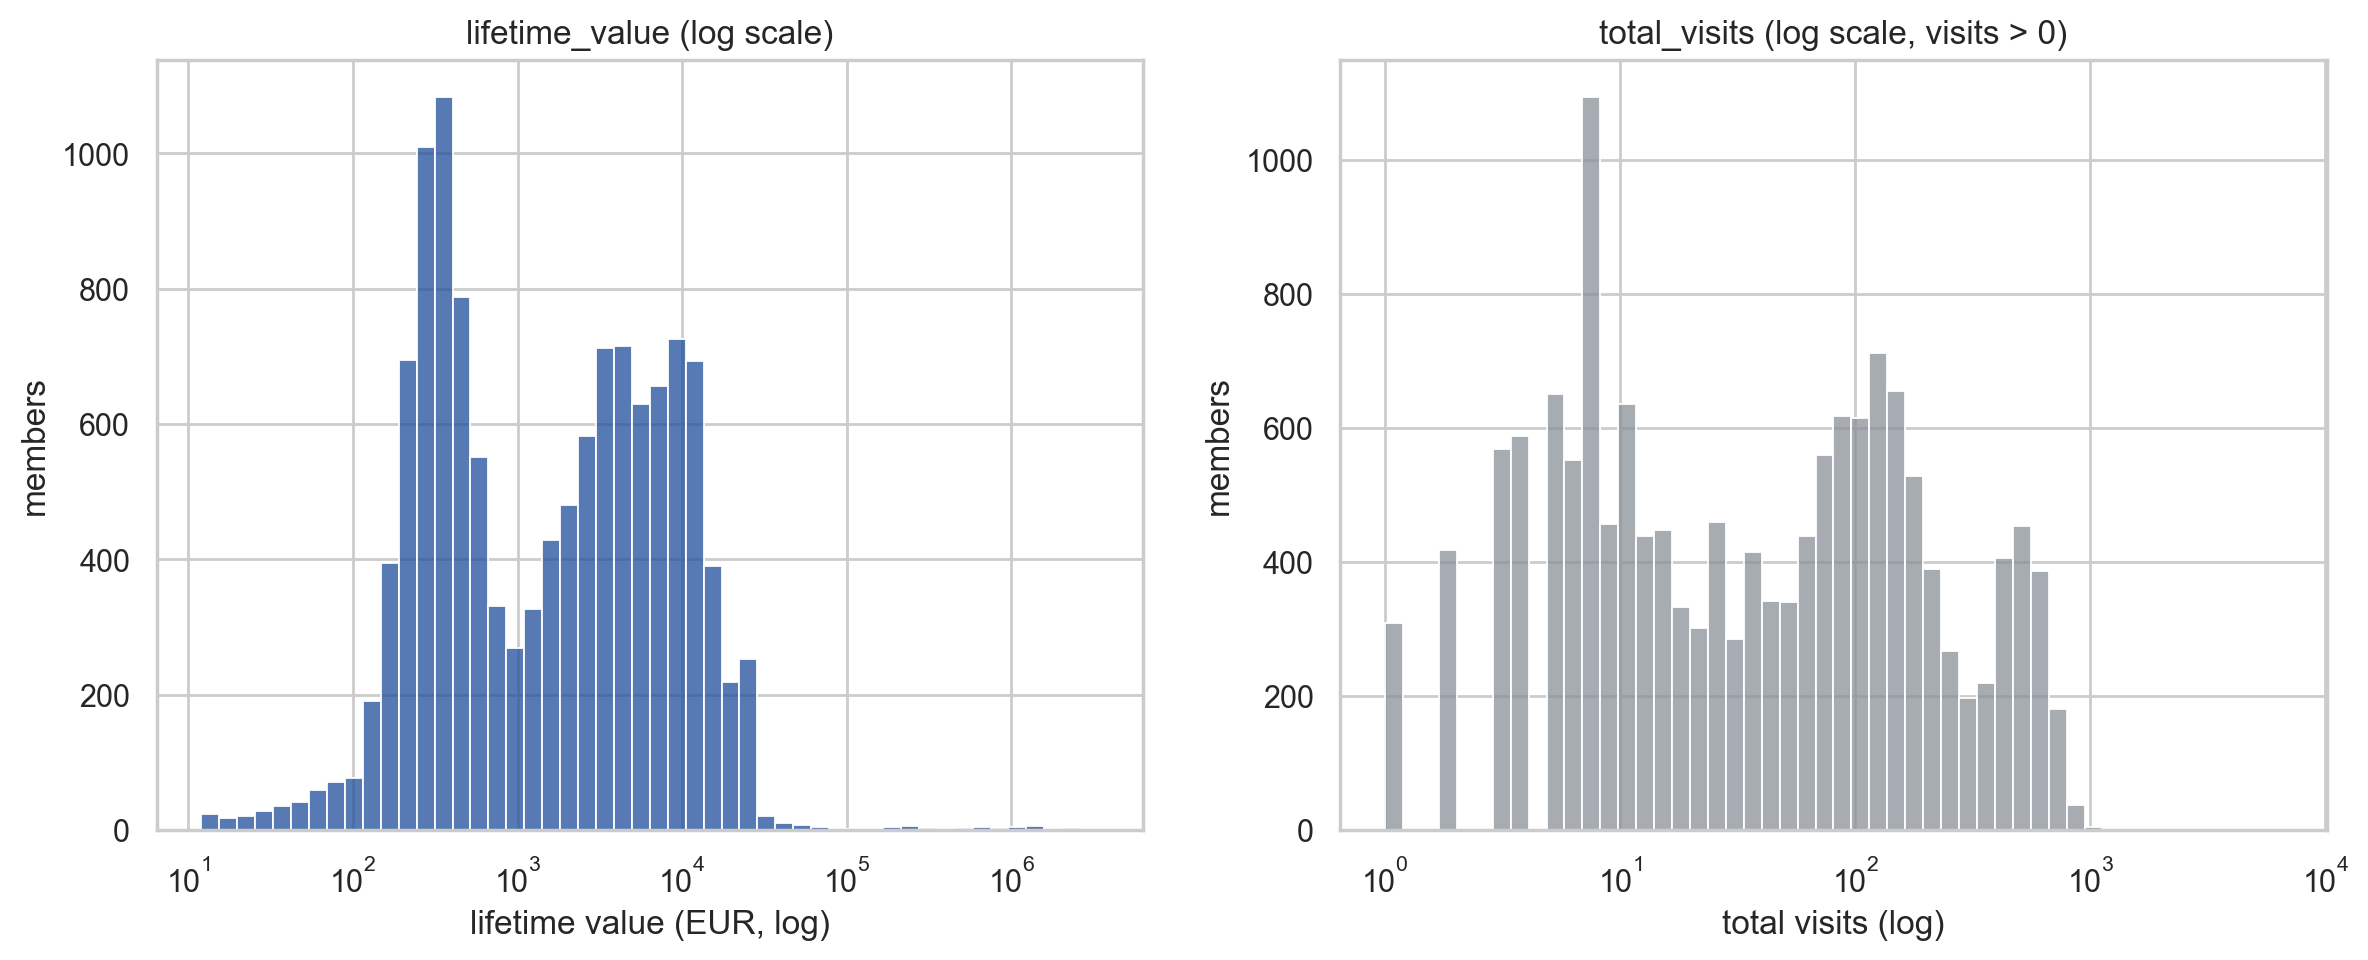

In [51]:
"""Histograms of lifetime_value and total_visits on log scales.
"""
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean["lifetime_value"].dropna(), bins=50, log_scale=True, color=BLUE, ax=axes[0])
axes[0].set(title="lifetime_value (log scale)", xlabel="lifetime value (EUR, log)", ylabel="members")
sns.histplot(df_clean.loc[df_clean["total_visits"] > 0, "total_visits"], bins=50, log_scale=True, color=GRAY, ax=axes[1])
axes[1].set(title="total_visits (log scale, visits > 0)", xlabel="total visits (log)", ylabel="members")
save_show(fig, "ltv_visits_distributions.png")

### Outliers by the taught rule (IQR fences)
lab03 and lab04 define an outlier with the box-plot rule, and week 4 repeats it: a value is outside the fences when it falls below
`Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`, with `IQR = Q3 - Q1`. The same rule is applied to every metric variable here, so "outlier"
has one documented meaning in this notebook instead of a different ad-hoc threshold per variable. Per week 4 an outlier is **not** an
error: the rows are kept, flagged, and carried into the extreme-value analysis in Section 4.10 and Section 9.

In [52]:
"""Apply the IQR box-plot fence rule of lab03/lab04 to every metric variable.

Rule exactly as taught: IQR = Q_3 - Q_1, minimum = Q_1 - 1.5*IQR, maximum = Q_3 + 1.5*IQR.
One flag column per variable records the verdict without touching the value, and `n_iqr_fences`
counts how many fences a member violates at once, which Section 9 turns into the
multidimensional anomaly score.
"""
fence_rows = []
for feat in metric_clean:
    series = df_clean[feat].dropna()
    Q_1 = series.quantile(0.25)
    Q_3 = series.quantile(0.75)
    IQR = Q_3 - Q_1
    minimum = Q_1 - 1.5 * IQR
    maximum = Q_3 + 1.5 * IQR
    below = df_clean[feat] < minimum
    above = df_clean[feat] > maximum
    df_clean[f"flag_iqr_low_{feat}"] = below.fillna(False)
    df_clean[f"flag_iqr_high_{feat}"] = above.fillna(False)
    fence_rows.append({"feature": feat, "Q1": round(Q_1, 2), "median": round(series.median(), 2), "Q3": round(Q_3, 2),
                       "IQR": round(IQR, 2), "lower_fence": round(minimum, 2), "upper_fence": round(maximum, 2),
                       "n_below": int(below.sum()), "n_above": int(above.sum()),
                       "pct_outside": round(float((below | above).sum()) / len(series) * 100, 2)})
fences = pd.DataFrame(fence_rows).set_index("feature")
iqr_flag_cols = [f"flag_iqr_low_{f}" for f in metric_clean] + [f"flag_iqr_high_{f}" for f in metric_clean]
df_clean["n_iqr_fences"] = df_clean[iqr_flag_cols].sum(axis=1)
results.update({
    "n_iqr_flag_columns": len(iqr_flag_cols),
    "n_members_no_fence_violation": int((df_clean["n_iqr_fences"] == 0).sum()),
    "members_over_2_fences_n": int((df_clean["n_iqr_fences"] > 2).sum()),
    "max_fences_violated": int(df_clean["n_iqr_fences"].max()),
    "most_outlying_feature": str(fences["pct_outside"].idxmax()),
    "most_outlying_feature_pct": float(fences["pct_outside"].max()),
})
print(fences.sort_values("pct_outside", ascending=False).to_string())
print(f"\nmembers violating no fence at all: {results['n_members_no_fence_violation']:,} of {len(df_clean):,} | "
      f"a member violates up to {results['max_fences_violated']} fences | most outlying variable: "
      f"{results['most_outlying_feature']} ({results['most_outlying_feature_pct']:.1f}% outside)")
print(f"lifetime_value above its upper fence: {int(fences.loc['lifetime_value', 'n_above']):,} rows, "
      f"against {results['ltv_extreme_count']} rows above the EUR 1M threshold used in Section 4.10")

                                 Q1   median       Q3      IQR  lower_fence  upper_fence  n_below  n_above  pct_outside
feature                                                                                                                
meeting_room_hours             0.00     0.00     7.20     7.20       -10.80        18.00        0     2938        20.78
guest_passes_issued            0.00     0.00     0.00     0.00         0.00         0.00        0     2477        17.48
event_space_hours              0.00     0.00     0.00     0.00         0.00         0.00        0     1759        11.39
total_visits                   8.00    35.00   132.00   124.00      -178.00       318.00        0     1730        11.23
days_since_last_visit          3.00    10.00    42.00    39.00       -55.50       100.50        0     1336         9.48
n_colleagues_on_account        0.00     0.00     1.00     1.00        -1.50         2.50        0     1323         8.65
lifetime_value               349.78  166

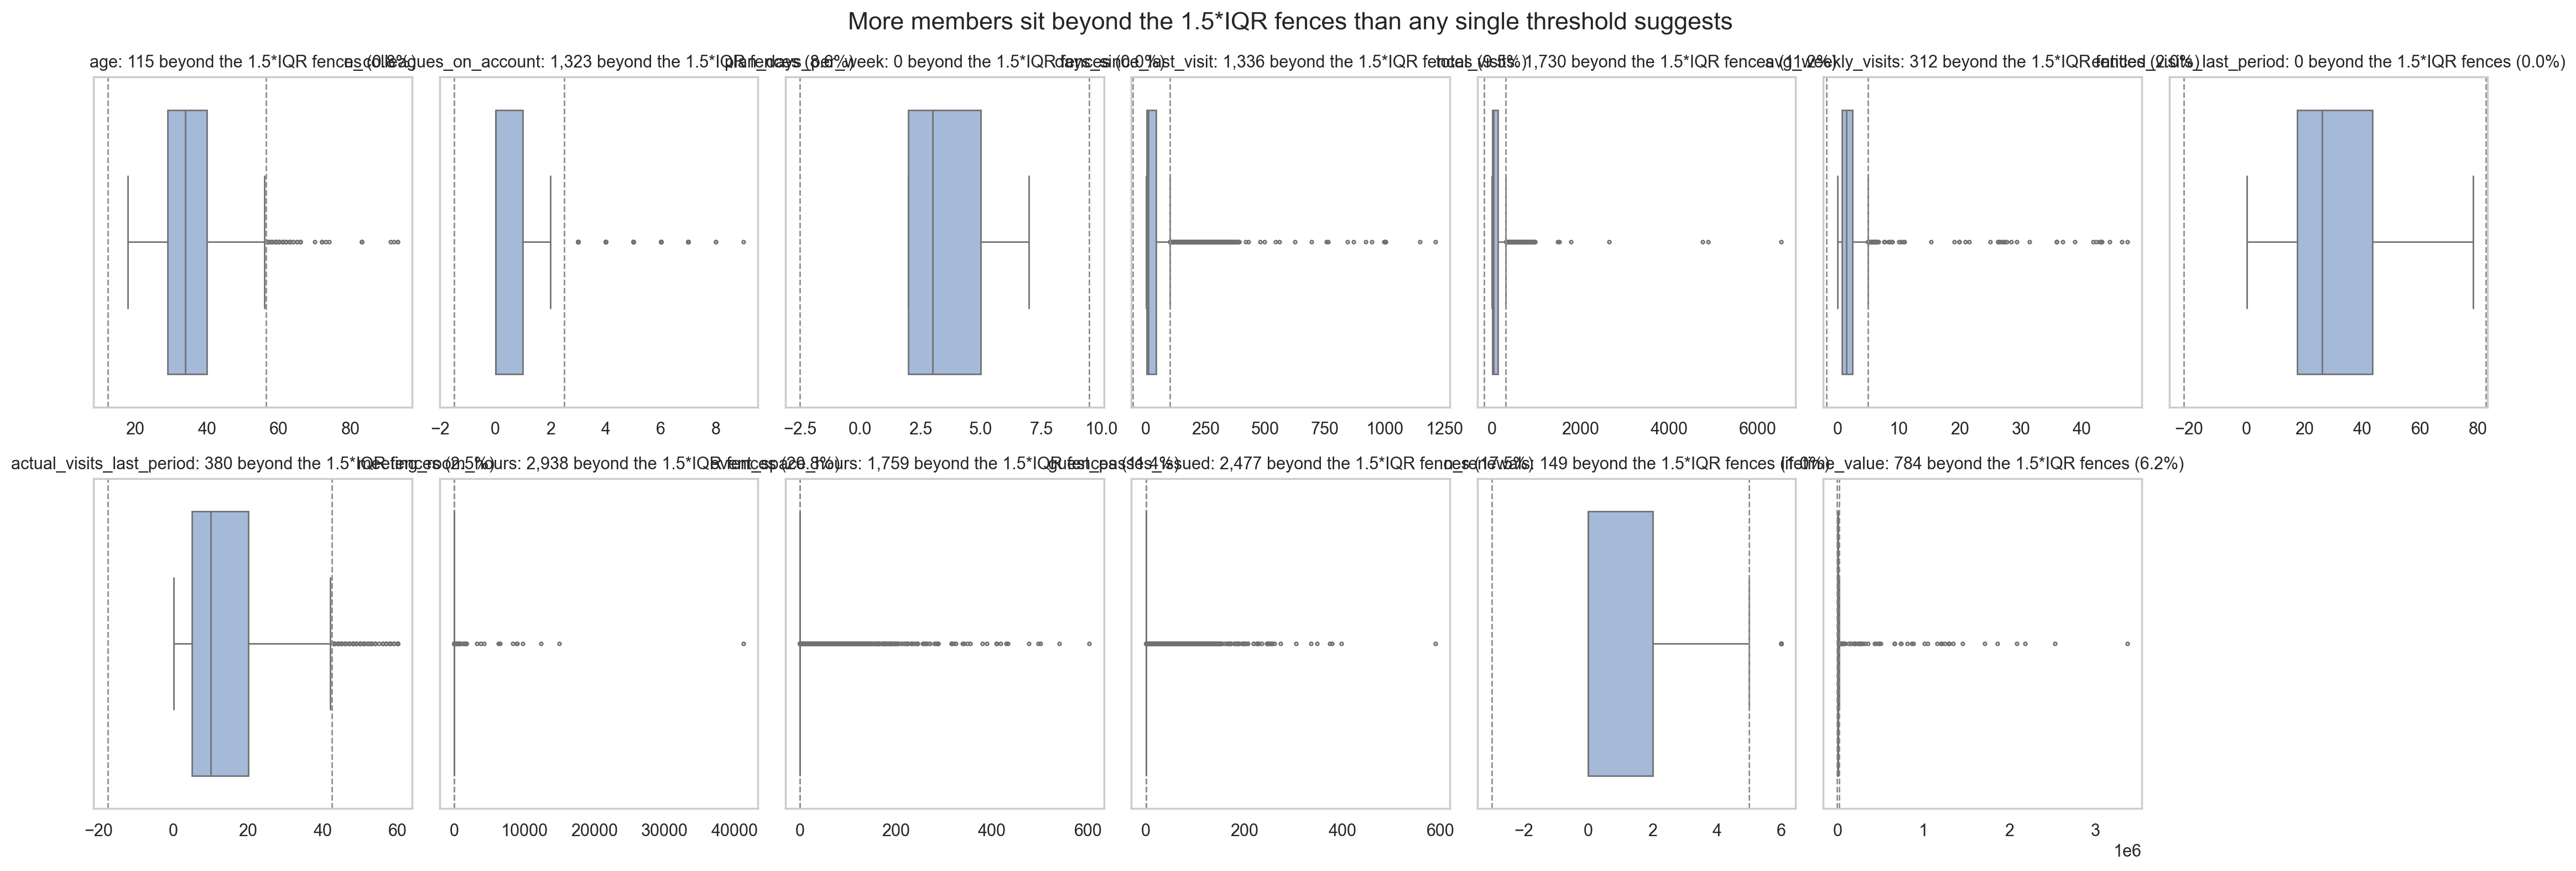

In [53]:
"""Boxplots of the metric variables with the 1.5*IQR fences drawn, so the rule is visible.

`whis=1.5` is seaborn's default and is exactly the taught rule, so the whisker tips *are* the
fences; they are redrawn as dashed lines with the outliers annotated rather than left implicit.
The grid is switched off because the axis carries the information (week 4, data-ink).
"""
n_feat = len(metric_clean)
fig, axes = plt.subplots(2, ceil(n_feat / 2), figsize=(22, 8))
for ax, feat in zip(axes.flatten(), metric_clean):
    series = df_clean[feat].dropna()
    Q_1, Q_3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q_3 - Q_1
    minimum, maximum = Q_1 - 1.5 * IQR, Q_3 + 1.5 * IQR
    sns.boxplot(x=series, ax=ax, color=LIGHT_BLUE, whis=1.5, fliersize=2)
    for fence in (minimum, maximum):
        ax.axvline(fence, color=GRAY, linestyle="--", linewidth=1)
    n_out = int(((series < minimum) | (series > maximum)).sum())
    ax.set_title(f"{feat}: {n_out:,} beyond the 1.5*IQR fences ({n_out / len(series):.1%})", fontsize=11)
    ax.set_xlabel("")
    ax.grid(False)
for ax in axes.flatten()[n_feat:]:
    ax.set_visible(False)
fig.suptitle("More members sit beyond the 1.5*IQR fences than any single threshold suggests", fontsize=16)
fig.tight_layout()
save_show(fig, "iqr_fences_by_feature.png")

### Non-metric variables (countplots, as lab05 teaches)
lab05 draws the distribution of every non-metric variable with `sns.countplot`, ordered by frequency, in one grid. Binary add-on
flags are included because "did they use it" is a category with two levels, and `plan_tier` is shown in its documented ordinal order.

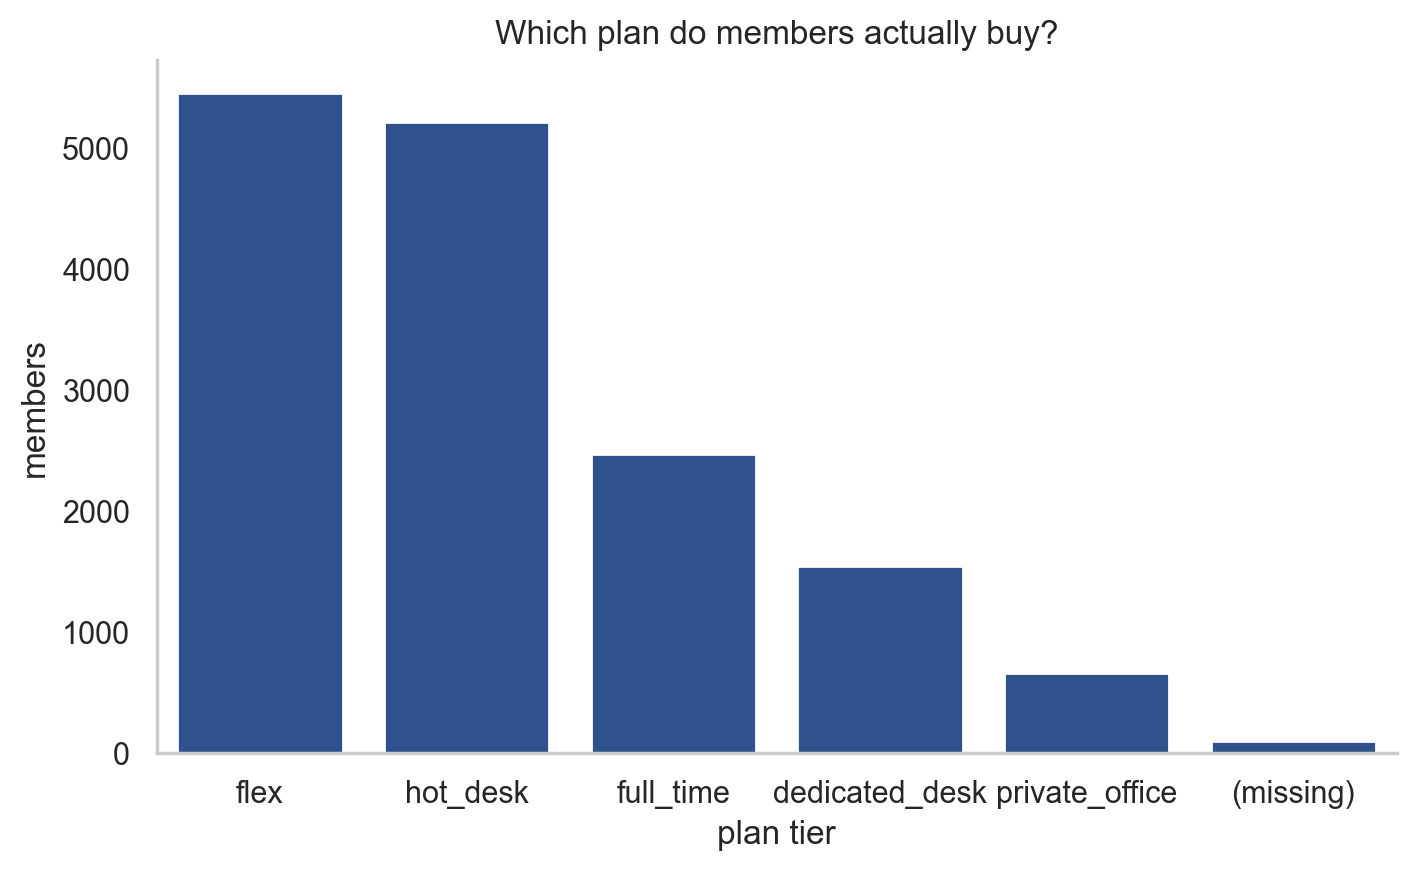

In [54]:
"""Countplot of one category, in frequency order, as lab05 does for a single variable.
"""
fig, ax = plt.subplots(figsize=(8, 4.5))
tier_counts = label_missing(df_clean["plan_tier"])
sns.countplot(x=tier_counts, color=BLUE, order=tier_counts.value_counts().index, ax=ax)
ax.set(title="Which plan do members actually buy?", xlabel="plan tier", ylabel="members")
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.grid(False)
sns.despine()
save_show(fig, "countplot_plan_tier.png")

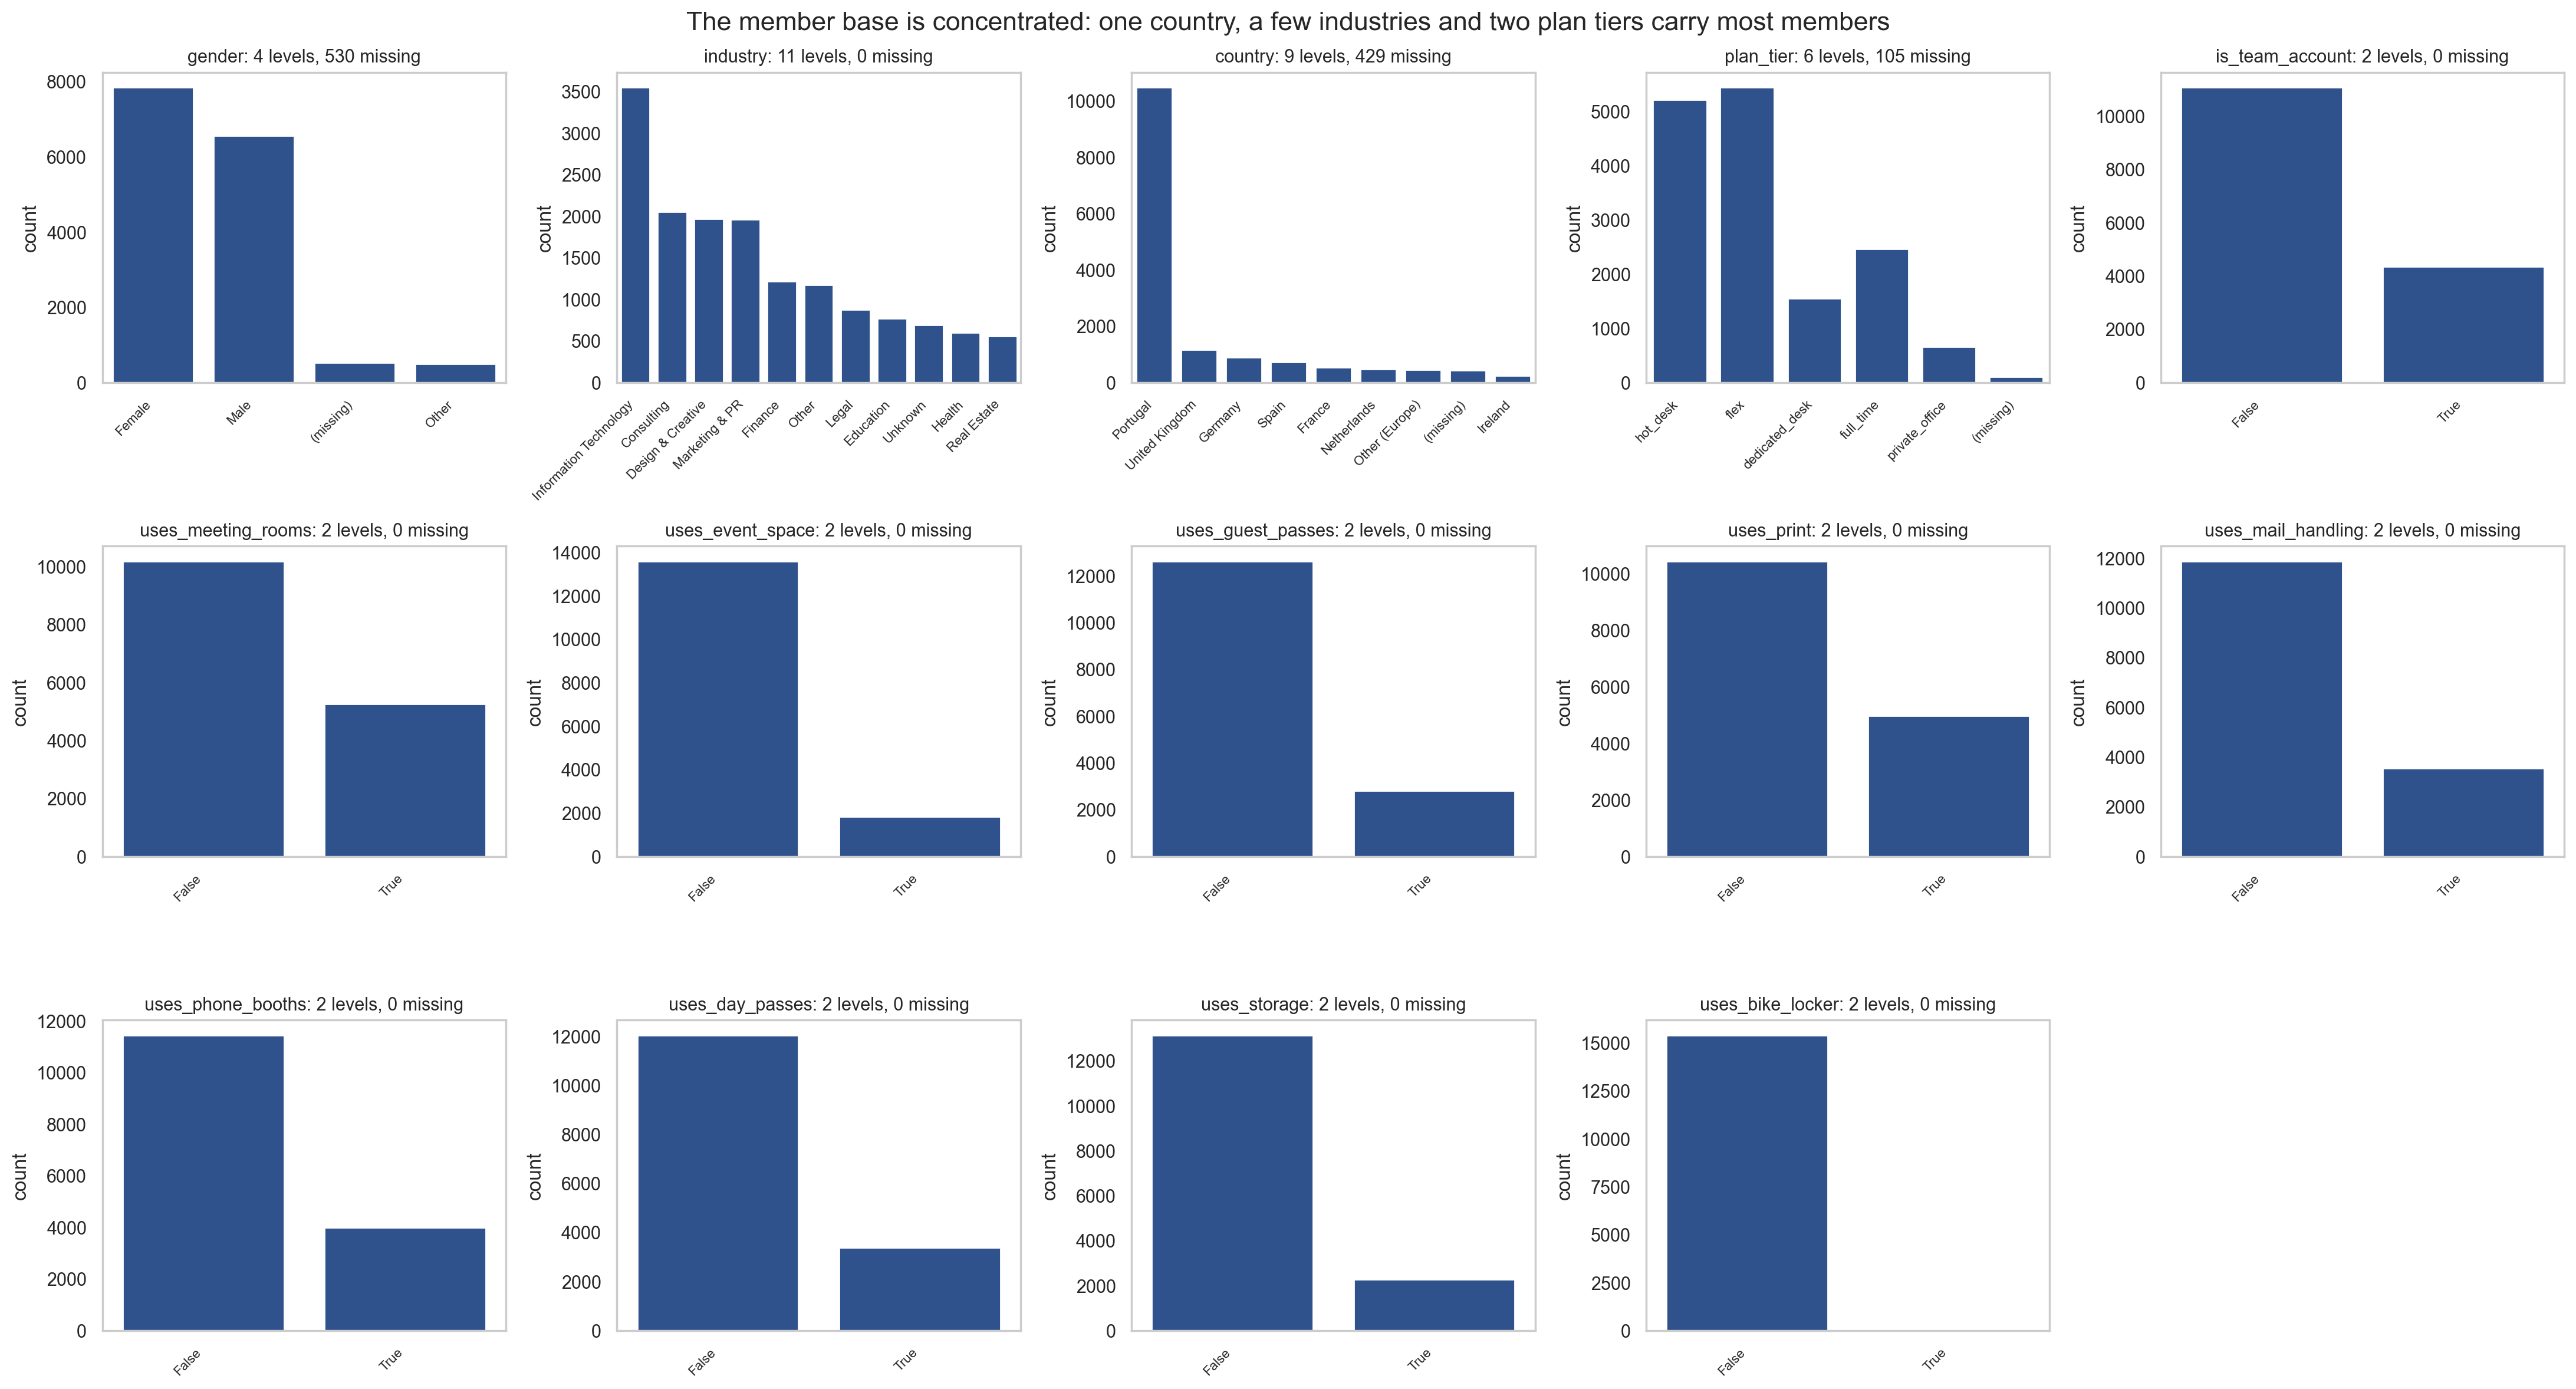

In [55]:
"""Countplot grid over every non-metric variable, as lab05 does for the whole non-metric block.

`plan_tier` keeps its documented ordinal order; the nominal categories are ordered by frequency,
which is the sorting week 4 asks for. Missing values are drawn as their own level so that a
category's emptiness is visible instead of silently shortening the bar chart.
"""
count_cols = categorical_features + binary_features
n_cols = len(count_cols)
fig, axes = plt.subplots(3, ceil(n_cols / 3), figsize=(22, 12))
for ax, col in zip(axes.flatten(), count_cols):
    series = label_missing(df_clean[col])
    if col == "plan_tier":
        order = tier_order + ["(missing)"]
        order = [o for o in order if o in set(series)]
    else:
        order = series.value_counts().index
    sns.countplot(x=series, color=BLUE, order=order, ax=ax)
    n_missing = int(df_clean[col].isna().sum())
    ax.set_title(f"{col}: {series.nunique()} levels, {n_missing:,} missing", fontsize=11)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    for label in ax.get_xticklabels():
        label.set_ha("right")
    ax.grid(False)
for ax in axes.flatten()[n_cols:]:
    ax.set_visible(False)
fig.suptitle("The member base is concentrated: one country, a few industries and two plan tiers carry most members", fontsize=16)
fig.tight_layout()
save_show(fig, "nonmetric_countplots.png")

In [56]:
"""Print the non-metric facts that matter for segmentation, all computed from the data.
"""
top_levels = {}
for col in categorical_features:
    vc = df_clean[col].value_counts(normalize=True) * 100
    top_levels[col] = {"level": str(vc.index[0]), "pct": float(vc.iloc[0]), "n_levels": int(df_clean[col].nunique())}
addon_takeup = (df_clean[binary_features].mean() * 100).round(1).sort_values(ascending=False)
results.update({f"top_level_{c}": top_levels[c]["level"] for c in categorical_features})
results.update({f"top_level_{c}_pct": top_levels[c]["pct"] for c in categorical_features})
results.update({f"n_levels_{c}": top_levels[c]["n_levels"] for c in categorical_features})
results["rarest_addon"] = str(addon_takeup.index[-1])
results["rarest_addon_pct"] = float(addon_takeup.iloc[-1])
results["most_used_addon"] = str(addon_takeup.index[0])
results["most_used_addon_pct"] = float(addon_takeup.iloc[0])
for col, info in top_levels.items():
    print(f"{col:12s}: {info['n_levels']:3d} levels | most common '{info['level']}' = {info['pct']:.1f}%")
print("\nadd-on take-up (% of members):")
print(addon_takeup.to_string())

gender      :   3 levels | most common 'Female' = 52.7%
industry    :  11 levels | most common 'Information Technology' = 23.0%
country     :   8 levels | most common 'Portugal' = 69.9%
plan_tier   :   5 levels | most common 'flex' = 35.5%

add-on take-up (% of members):
uses_meeting_rooms    34.0
uses_print            32.3
is_team_account       28.2
uses_phone_booths     25.8
uses_mail_handling    23.0
uses_day_passes       22.0
uses_guest_passes     18.2
uses_storage          14.8
uses_event_space      11.9
uses_bike_locker       0.2


In [57]:
"""Print the insights of this section from computed values (no hand-typed numbers).
"""
print(f"Insight 1 - median lifetime value is {results['ltv_median']:,.0f} EUR but the mean is {results['ltv_mean']:,.0f}: a few members dominate revenue "
      f"(the top 1% hold {results['ltv_top1pct_revenue_share']:.0f}% of known lifetime value).")
print(f"Insight 2 - median total visits is {results['visits_median']:.0f} but the maximum is {results['visits_max']:,.0f}.")
print(f"Insight 3 - {results['top_country']} accounts for {results['top_country_pct']:.1f}% of members; top plan tier is {results['top_plan_tier']}; top industry is {results['top_industry']}.")
print(f"Insight 4 - {results['pct_churned']:.1f}% of members have ended their membership within the 3-year window "
      f"(cumulative status share, NOT an annual churn rate); {results['pct_active']:.1f}% are active.")

Insight 1 - median lifetime value is 1,668 EUR but the mean is 7,340: a few members dominate revenue (the top 1% hold 46% of known lifetime value).
Insight 2 - median total visits is 35 but the maximum is 6,530.
Insight 3 - Portugal accounts for 68.0% of members; top plan tier is flex; top industry is Information Technology.
Insight 4 - 74.4% of members have ended their membership within the 3-year window (cumulative status share, NOT an annual churn rate); 25.6% are active.


# 6. Bivariate analysis
Scatter, hexbin and a correlation heatmap (annotation only when |corr| >= 0.5, as in lab04), then group comparisons by plan tier and status.

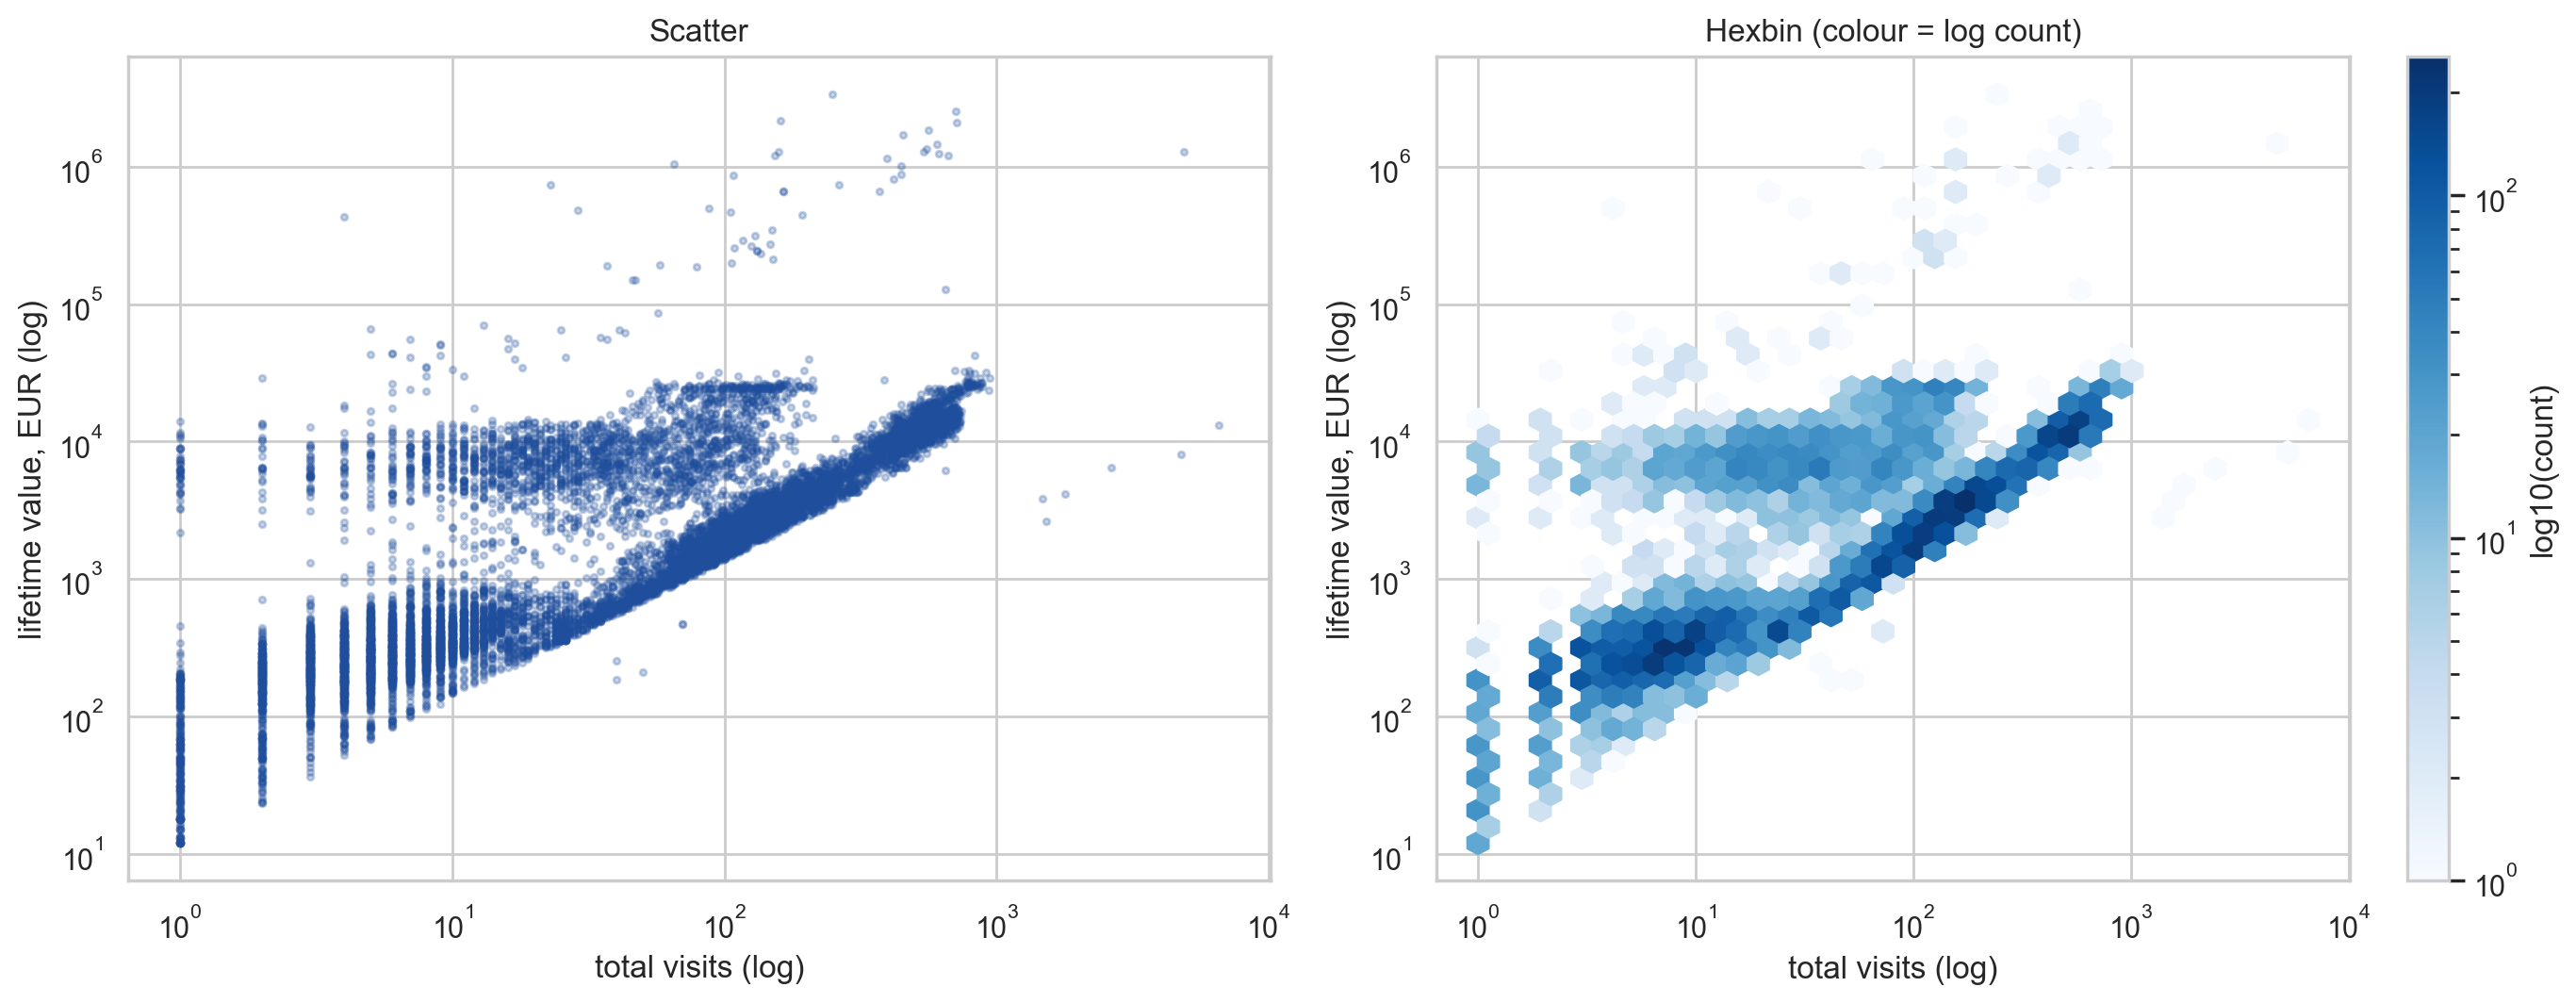

Pearson = 0.15 | Spearman = 0.77 | log-log = 0.76


In [58]:
"""Scatter and hexbin of lifetime_value versus total_visits on log-log axes.
"""
xy = df_clean[["total_visits", "lifetime_value"]].dropna()
xy = xy[(xy["total_visits"] > 0) & (xy["lifetime_value"] > 0)]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(xy["total_visits"], xy["lifetime_value"], s=6, alpha=0.25, color=BLUE)
axes[0].set(xscale="log", yscale="log", xlabel="total visits (log)", ylabel="lifetime value, EUR (log)", title="Scatter")
hb = axes[1].hexbin(xy["total_visits"], xy["lifetime_value"], gridsize=40, xscale="log", yscale="log", bins="log", cmap="Blues")
axes[1].set(xlabel="total visits (log)", ylabel="lifetime value, EUR (log)", title="Hexbin (colour = log count)")
fig.colorbar(hb, ax=axes[1], label="log10(count)")
fig.tight_layout()
save_show(fig, "ltv_vs_visits.png")
print(f"Pearson = {results['correlation_pearson']:.2f} | Spearman = {results['correlation_spearman']:.2f} | log-log = {results['correlation_loglog']:.2f}")

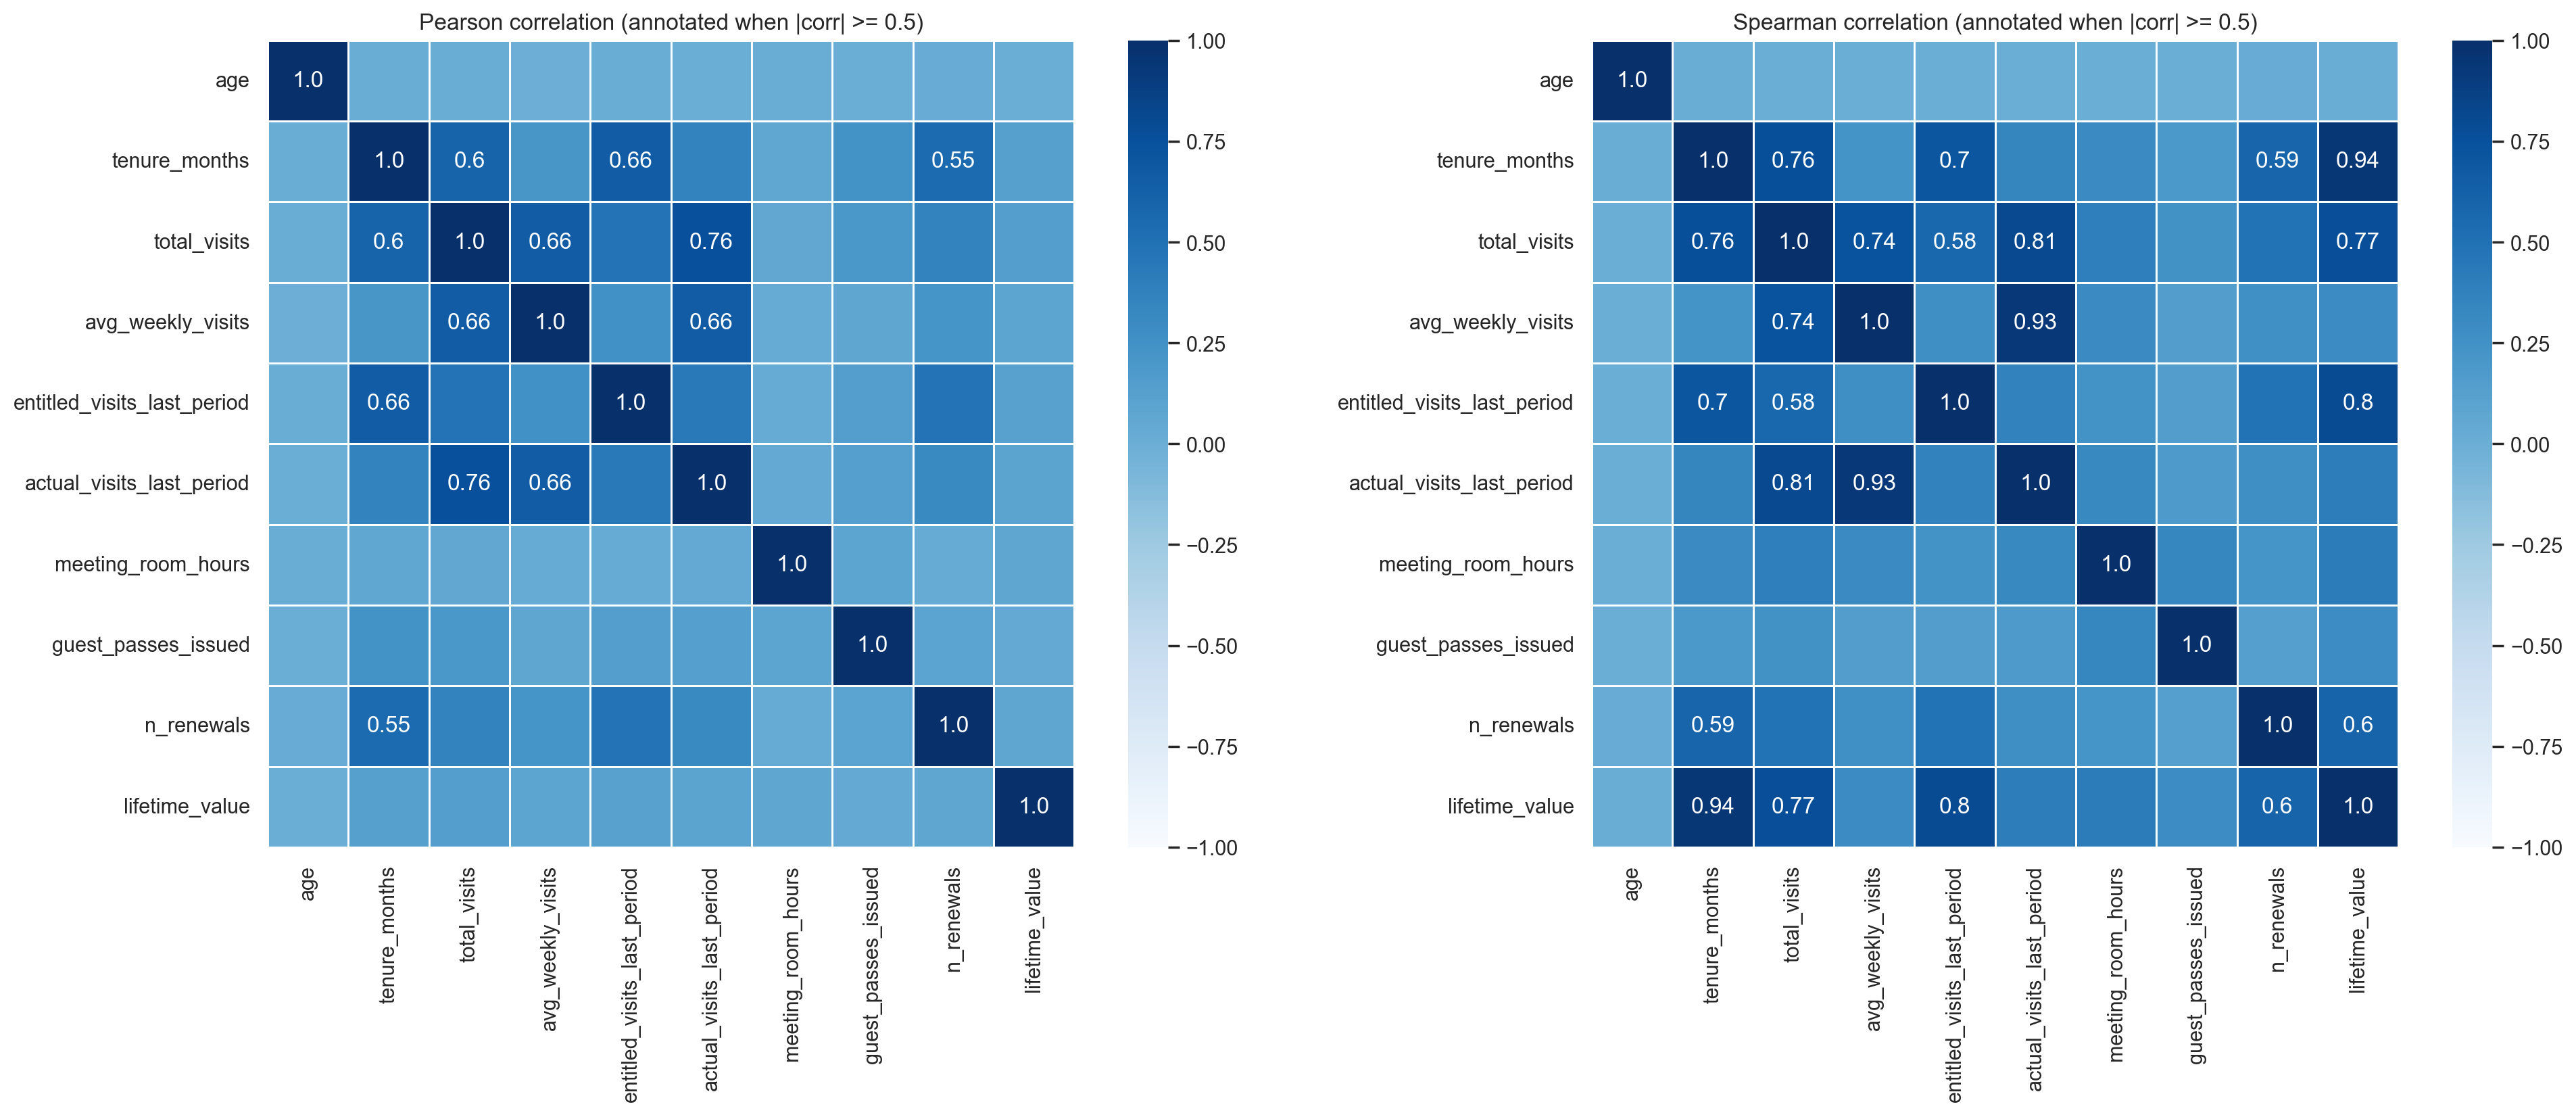

In [59]:
"""Correlation heatmaps (Pearson and Spearman) of the cleaned metric variables, annotated only where |corr| >= 0.5.
"""
corr_features = ["age", "tenure_months", "total_visits", "avg_weekly_visits", "entitled_visits_last_period",
                 "actual_visits_last_period", "meeting_room_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df_clean[corr_features].corr(method=method)
    mask_annot = np.absolute(corr.values) >= 0.5
    annot = np.where(mask_annot, corr.values.round(2), np.full(corr.shape, ""))
    sns.heatmap(corr, annot=annot, fmt="", vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, cmap="Blues", ax=ax)
    ax.set_title(f"{method.capitalize()} correlation (annotated when |corr| >= 0.5)")
fig.tight_layout()
save_show(fig, "correlation_heatmap.png")

                count   median     mean
plan_tier                              
hot_desk         4408    356.0   2215.0
flex             4454   1855.0   4114.0
full_time        1946   5840.0  11626.0
dedicated_desk   1208  11026.0  15949.0
private_office    508  21464.0  35168.0


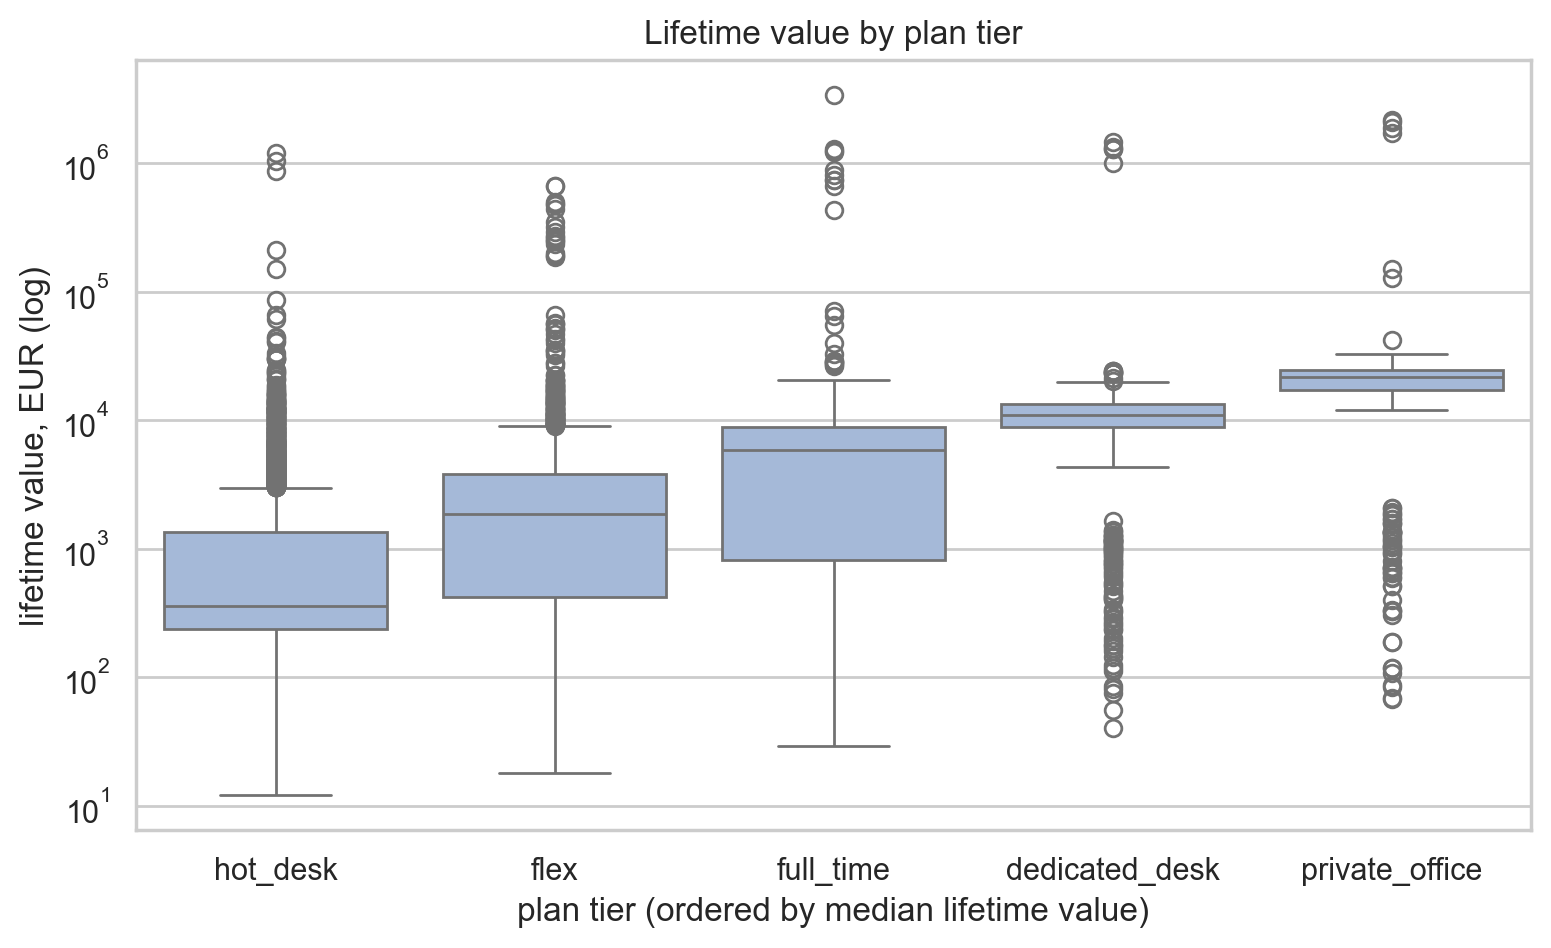

In [60]:
"""Compare lifetime_value across plan tiers (median table + boxplot on a log axis).
"""
ltv_by_tier = df_clean.groupby("plan_tier")["lifetime_value"].agg(["count", "median", "mean"]).round(0).sort_values("median")
print(ltv_by_tier.to_string())
order_ltv = ltv_by_tier.index.tolist()
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df_clean, x="plan_tier", y="lifetime_value", order=order_ltv, color=LIGHT_BLUE, ax=ax)
ax.set(yscale="log", xlabel="plan tier (ordered by median lifetime value)", ylabel="lifetime value, EUR (log)", title="Lifetime value by plan tier")
save_show(fig, "ltv_by_plan_tier.png")

In [61]:
"""Compare active and ended members: medians of key variables and the share of active members per plan tier.
"""
status_medians = df_clean.groupby("status")[["tenure_months", "total_visits", "lifetime_value", "actual_visits_last_period", "n_renewals"]].median().round(2)
print(status_medians.to_string())
print()
active_share = (df_clean.groupby("plan_tier")["is_active"].mean() * 100).round(1).sort_values()
print("share of active members per plan tier (%):")
print(active_share.to_string())
print()
print("crosstab plan_tier x status (row %):")
print((pd.crosstab(df_clean["plan_tier"], df_clean["status"], normalize="index") * 100).round(1).to_string())

        tenure_months  total_visits  lifetime_value  actual_visits_last_period  n_renewals
status                                                                                    
active          19.12          17.0         4594.06                        4.0         1.0
ended            8.18          59.0         1452.22                       13.0         0.0

share of active members per plan tier (%):
plan_tier
hot_desk          13.4
flex              20.3
full_time         37.6
private_office    45.0
dedicated_desk    56.6

crosstab plan_tier x status (row %):
status          active  ended
plan_tier                    
dedicated_desk    56.6   43.4
flex              20.3   79.7
full_time         37.6   62.4
hot_desk          13.4   86.6
private_office    45.0   55.0


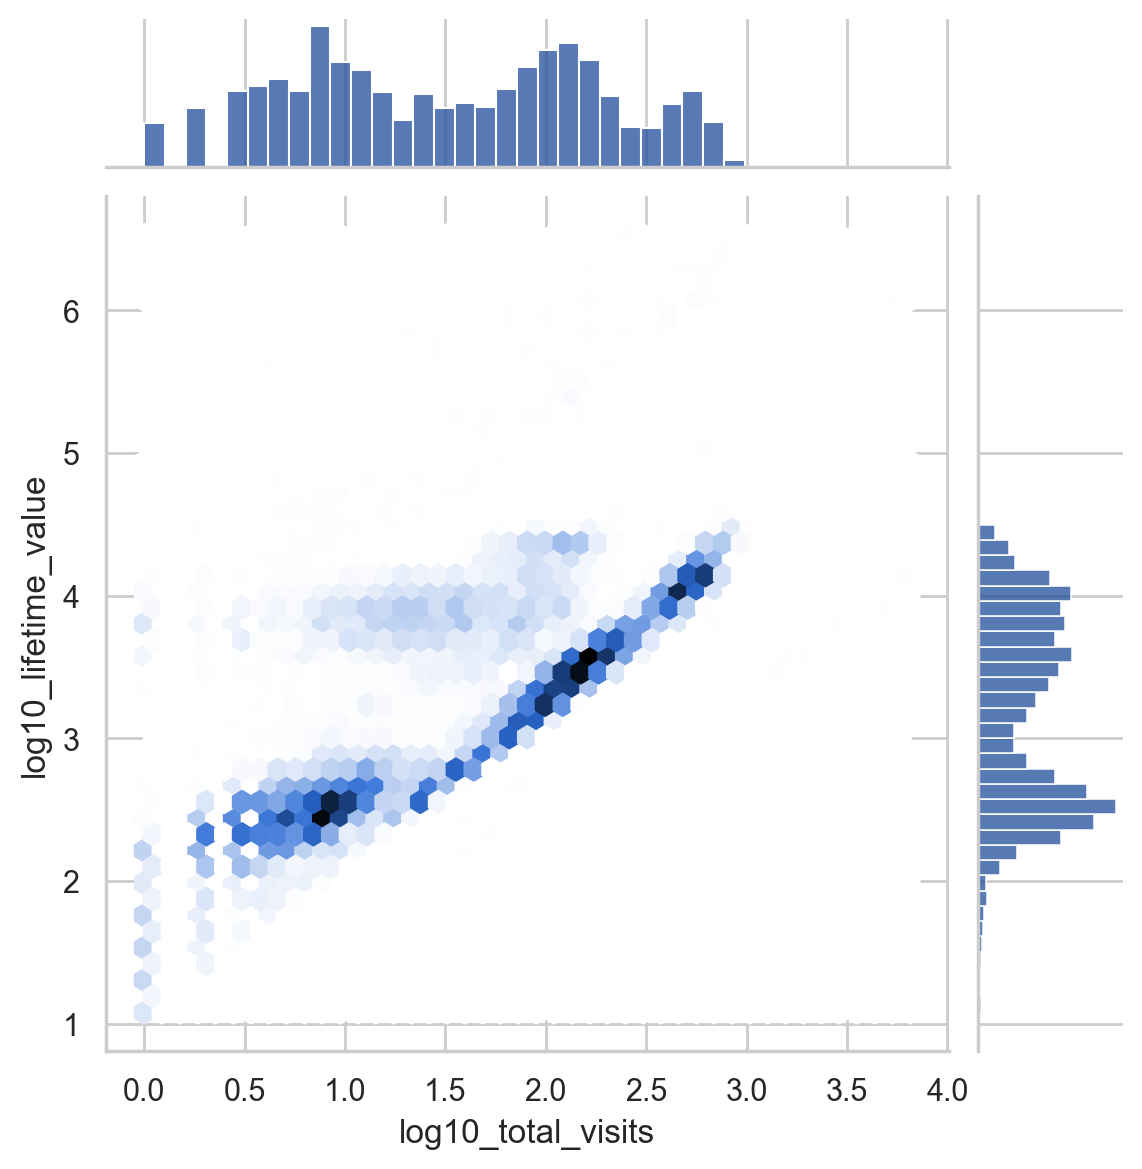

In [62]:
"""Seaborn jointplot (hex) of log10 total_visits versus log10 lifetime_value, as in lab04.
"""
joint_df = pd.DataFrame({"log10_total_visits": np.log10(xy["total_visits"]), "log10_lifetime_value": np.log10(xy["lifetime_value"])})
g = sns.jointplot(data=joint_df, x="log10_total_visits", y="log10_lifetime_value", kind="hex", color=BLUE, height=6)
g.figure.savefig(os.path.join(FIGURES_DIR, "jointplot_visits_ltv.png"), dpi=200, bbox_inches="tight")
plt.show()

### Category against category (lab05 stacked bars, absolute and relative)
lab05 crosses two categorical variables with stacked bars, once in absolute counts and once normalised per row, because the two
pictures answer different questions: "how many members are in this cell" and "what share of a tier has already left". Printed
crosstabs are kept above; the charts make the concentration visible.

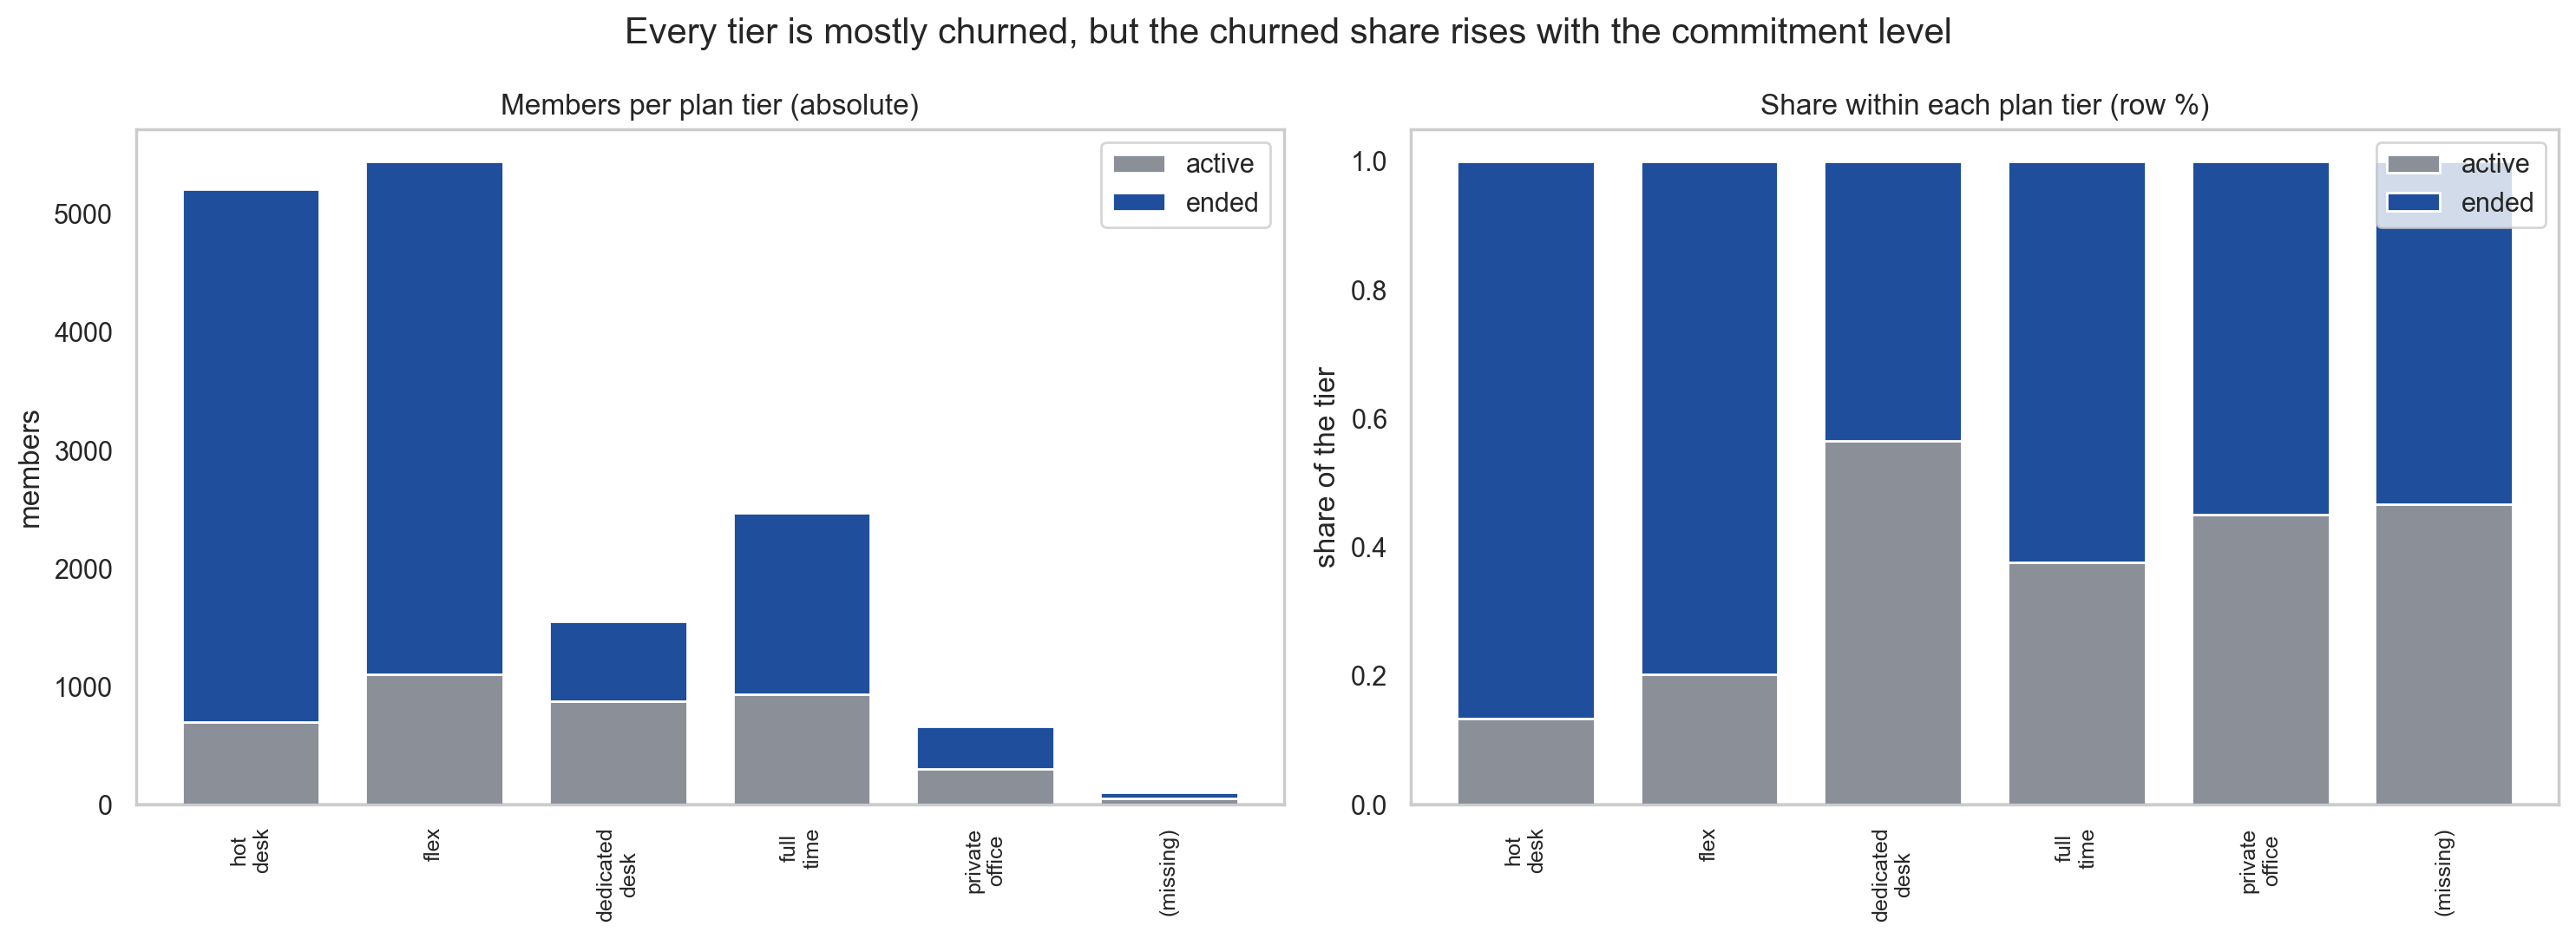

most retained tier: dedicated_desk (56.6% active) | least retained: hot_desk (13.4% active)


In [63]:
"""Stacked bars of plan tier by membership status, absolute counts and row shares (lab05 cells 37-49).
"""
cross_df = df_clean.assign(plan_tier=label_missing(df_clean["plan_tier"]))
abs_cross = cross_df.groupby(["plan_tier", "status"])["status"].size().unstack().reindex(tier_order + ["(missing)"]).fillna(0)
rel_cross = pd.crosstab(cross_df["plan_tier"], cross_df["status"], normalize="index").reindex(tier_order + ["(missing)"])
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True)
abs_cross.plot.bar(stacked=True, ax=axes[0], color=[GRAY, BLUE], edgecolor="white", width=0.75)
axes[0].set(title="Members per plan tier (absolute)", ylabel="members", xlabel="")
rel_cross.plot.bar(stacked=True, ax=axes[1], color=[GRAY, BLUE], edgecolor="white", width=0.75)
axes[1].set(title="Share within each plan tier (row %)", ylabel="share of the tier", xlabel="")
for ax in axes:
    ax.set_xticklabels([t.get_text().replace("_", "\n") for t in ax.get_xticklabels()], fontsize=9)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(False)
    ax.legend(title="")
fig.suptitle("Every tier is mostly churned, but the churned share rises with the commitment level", fontsize=15)
fig.tight_layout()
save_show(fig, "plan_tier_by_status.png")
active_by_tier = (df_clean.groupby(label_missing(df_clean["plan_tier"]))["is_active"].mean() * 100).reindex(tier_order + ["(missing)"])
results.update({f"active_pct_{t}": float(v) for t, v in active_by_tier.items()})
results["most_retained_tier"] = str(active_by_tier.idxmax())
results["most_retained_tier_pct"] = float(active_by_tier.max())
results["least_retained_tier"] = str(active_by_tier.idxmin())
results["least_retained_tier_pct"] = float(active_by_tier.min())
print(f"most retained tier: {results['most_retained_tier']} ({results['most_retained_tier_pct']:.1f}% active) | "
      f"least retained: {results['least_retained_tier']} ({results['least_retained_tier_pct']:.1f}% active)")

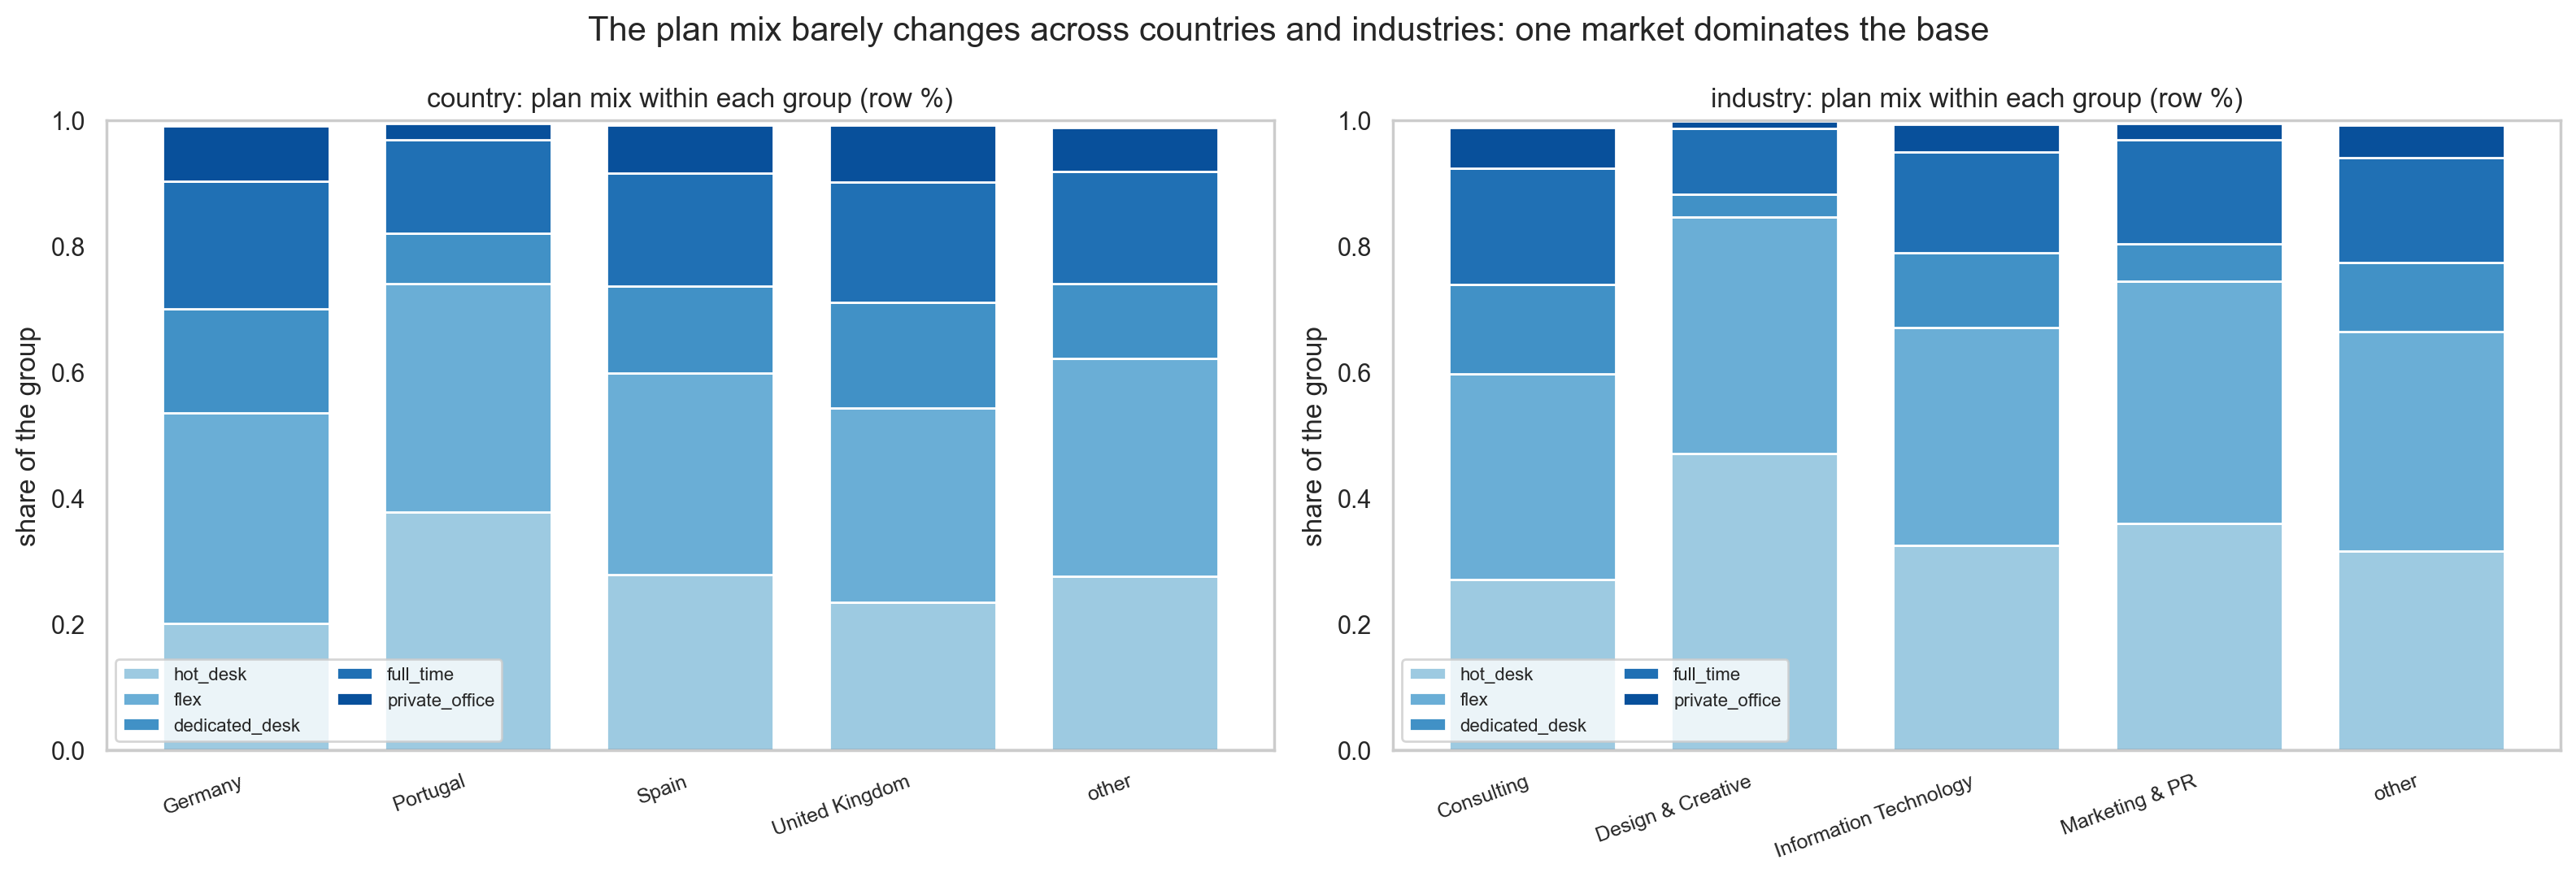

In [64]:
"""Stacked bars of country and industry against plan tier, normalised per row.
"""
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, col in zip(axes, ["country", "industry"]):
    series = label_missing(df_clean[col])
    share = series.value_counts(normalize=True) * 100
    top = list(share.index[:4]) + (["(missing)"] if "(missing)" not in share.index[:4] and series.isna().any() else [])
    sub = df_clean.assign(**{col: series.where(series.isin(top), "other")})
    pd.crosstab(sub[col], label_missing(sub["plan_tier"]), normalize="index")[
        [t for t in tier_order + ["(missing)"] if t in sub["plan_tier"].values]].plot.bar(
        stacked=True, ax=ax, color=[TIER_COLORS.get(t, GRAY) for t in
                                    [t for t in tier_order + ["(missing)"] if t in sub["plan_tier"].values]],
        edgecolor="white", width=0.75)
    ax.set(title=f"{col}: plan mix within each group (row %)", xlabel="", ylabel="share of the group", ylim=(0, 1))
    ax.set_xticklabels([t.get_text() for t in ax.get_xticklabels()], rotation=20, ha="right", fontsize=9)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(False)
    ax.legend(title="", fontsize=8, ncol=2)
fig.suptitle("The plan mix barely changes across countries and industries: one market dominates the base", fontsize=15)
fig.tight_layout()
save_show(fig, "category_by_plan_tier.png")

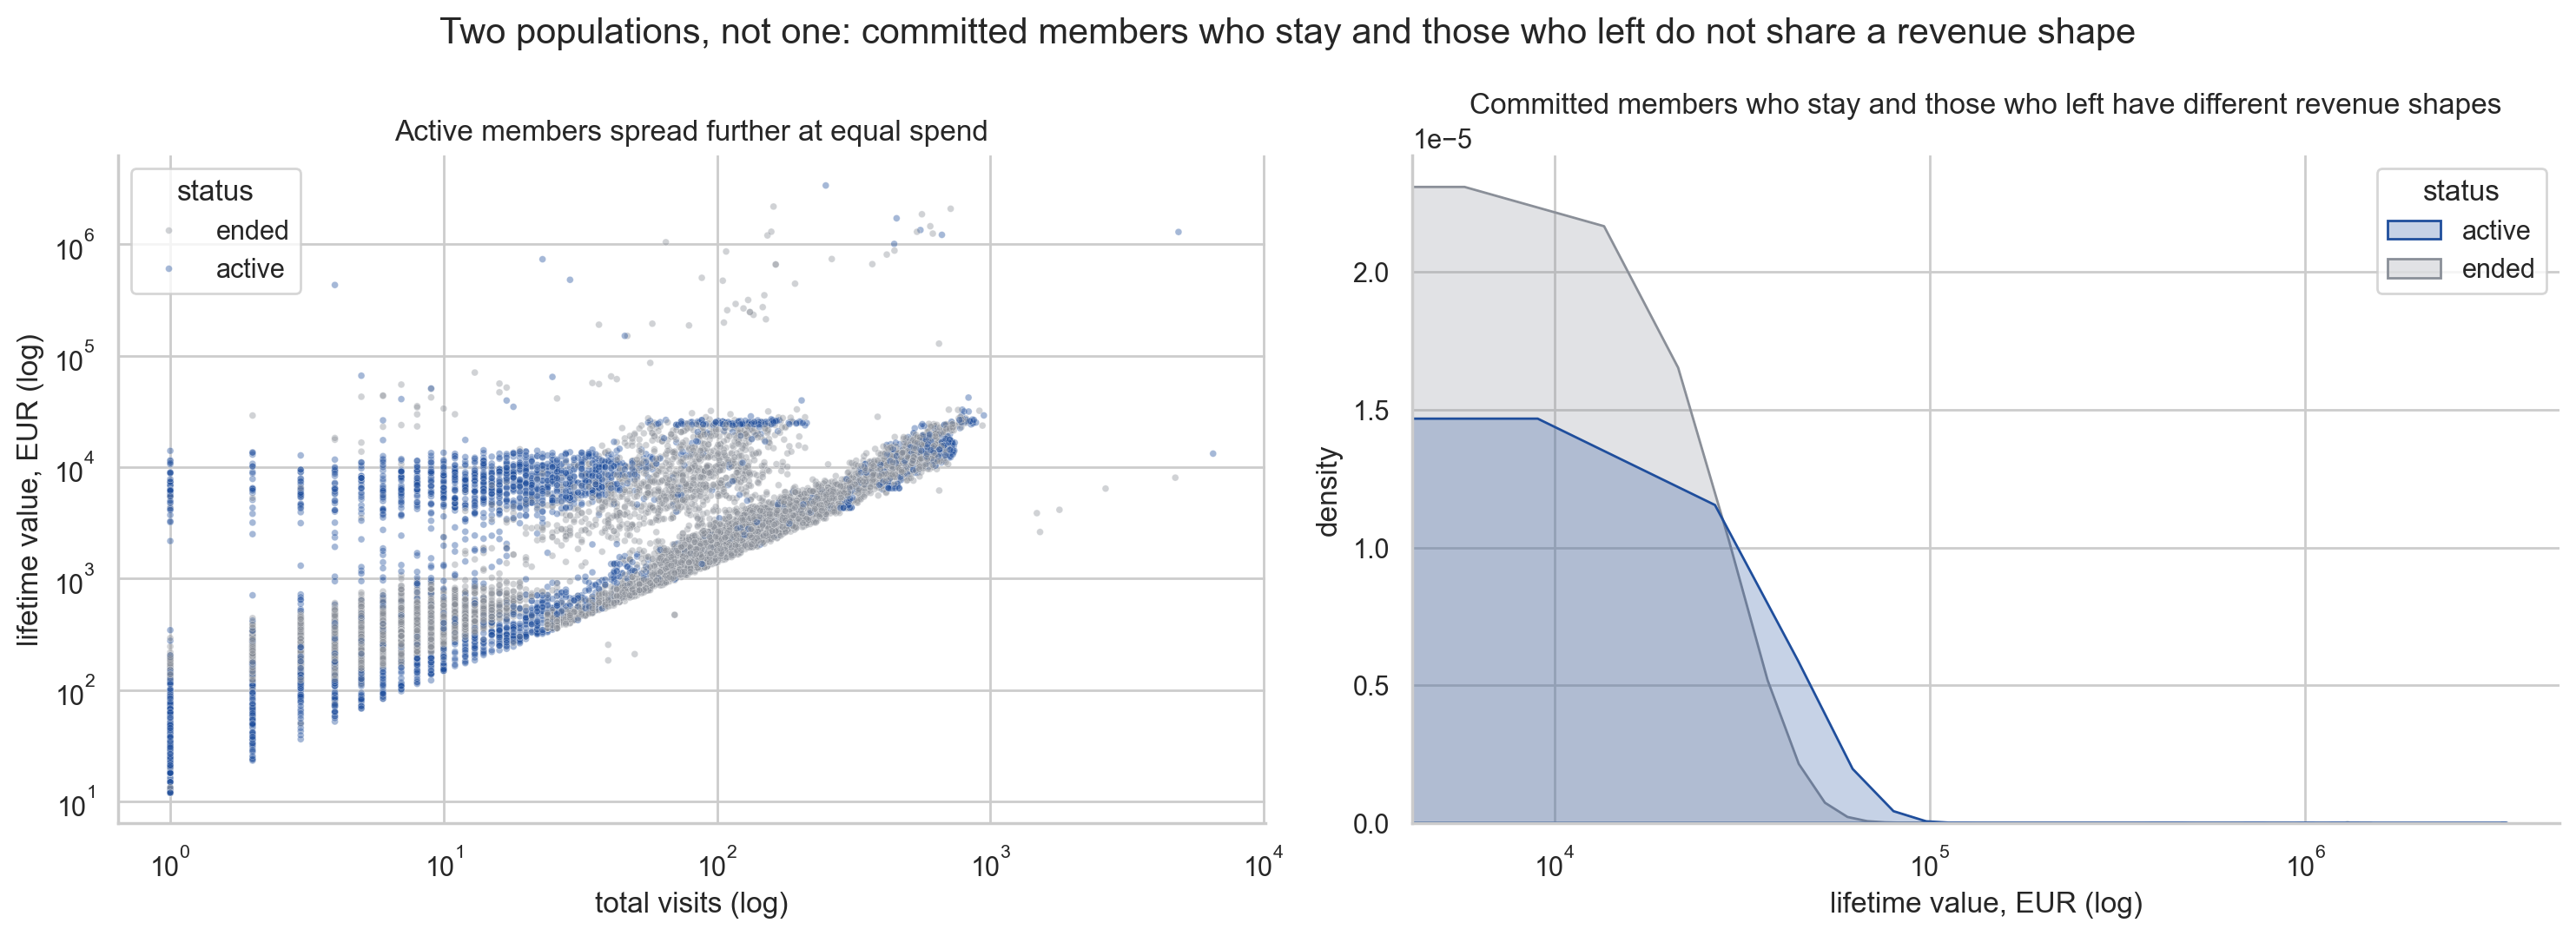

In [65]:
"""Seaborn scatterplot and filled KDE overlays, as lab05 teaches them.

Two density questions from the EDA brief are answered by an overlay rather than a statistic: is
monthly revenue bimodal inside the commitment tiers, and do visits separate the groups that are
left from the ones that stay?
"""
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sc2 = df_clean[["total_visits", "lifetime_value", "status", "plan_tier"]].dropna()
sc2 = sc2[(sc2["lifetime_value"] > 0) & (sc2["total_visits"] > 0)]
sns.scatterplot(data=sc2, x="total_visits", y="lifetime_value", hue="status",
                palette={"active": BLUE, "ended": GRAY}, s=8, alpha=0.4, ax=axes[0])
axes[0].set(xscale="log", yscale="log", xlabel="total visits (log)", ylabel="lifetime value, EUR (log)",
            title="Active members spread further at equal spend")
for sp in ("top", "right"):
    axes[0].spines[sp].set_visible(False)
commitment_tiers = ["dedicated_desk", "full_time"]     # the two commitment tiers named in the hypothesis section
commitment = df_clean[df_clean["plan_tier"].isin(commitment_tiers)]
sns.kdeplot(data=commitment[["lifetime_value", "status"]].dropna(), x="lifetime_value", hue="status",
            fill=True, common_norm=False, ax=axes[1], palette={"active": BLUE, "ended": GRAY})
axes[1].set(xscale="log", xlabel="lifetime value, EUR (log)", ylabel="density",
            title="Committed members who stay and those who left have different revenue shapes")
for sp in ("top", "right"):
    axes[1].spines[sp].set_visible(False)
fig.suptitle("Two populations, not one: committed members who stay and those who left do not share a revenue shape", fontsize=15)
fig.tight_layout()
sns.despine()
save_show(fig, "status_overlays.png")

### Correlation within groups, not only pooled
week 4 warns that *mixing populations can reverse a correlation*. The pooled Pearson and Spearman of `lifetime_value` and
`total_visits` disagree strongly, and the disagreement is itself the finding: a monotone but non-linear link that a linear method
would understate. The cell below recomputes both coefficients inside each population instead of trusting the pooled number.

In [66]:
"""Recompute the value-visit correlation inside each status group and each plan tier.
"""
corr_pairs = []
for label, mask in [("all members", pd.Series(True, index=df_clean.index)),
                    ("active only", df_clean["is_active"]),
                    ("ended only", ~df_clean["is_active"])] + [(f"tier {t}", df_clean["plan_tier"] == t) for t in tier_order]:
    sub = df_clean.loc[mask, ["lifetime_value", "total_visits"]].dropna()
    sub = sub[(sub > 0).all(axis=1)]
    if len(sub) < 30:
        continue
    corr_pairs.append({"population": label, "n": len(sub),
                       "pearson": round(float(sub.corr().iloc[0, 1]), 3),
                       "spearman": round(float(sub.corr(method="spearman").iloc[0, 1]), 3),
                       "log_pearson": round(float(np.corrcoef(np.log(sub["lifetime_value"]), np.log(sub["total_visits"]))[0, 1]), 3)})
within = pd.DataFrame(corr_pairs).set_index("population")
spread = float(within["spearman"].max() - within["spearman"].min())
results.update({
    "within_group_spearman_min": float(within["spearman"].min()),
    "within_group_spearman_max": float(within["spearman"].max()),
    "within_group_spearman_spread": spread,
    "pooled_vs_active_gap": float(within.loc["all members", "spearman"] - within.loc["active only", "spearman"]),
})
print(within.to_string())
print(f"\npooled Spearman {results['correlation_spearman']:.2f} versus within-population Spearman from "
      f"{results['within_group_spearman_min']:.2f} to {results['within_group_spearman_max']:.2f} (spread {spread:.2f})")
print("Reading: the pooled coefficient is a mixture of the groups, so it is reported as a mixture and never as a single")
print("relationship. Any distance-based method in Deliverable 2 must either use the monotone scale (rank or log) or cluster")
print("inside a population, otherwise the pooled value would be the only signal it sees.")

                         n  pearson  spearman  log_pearson
population                                                
all members          12500    0.146     0.776        0.775
active only           3175    0.182     0.707        0.678
ended only            9325    0.125     0.878        0.869
tier hot_desk         4373    0.079     0.872        0.833
tier flex             4427    0.076     0.737        0.760
tier dedicated_desk   1203    0.234     0.716        0.450
tier full_time        1934    0.068     0.605        0.618
tier private_office    501    0.074     0.395        0.703

pooled Spearman 0.77 versus within-population Spearman from 0.40 to 0.88 (spread 0.48)
Reading: the pooled coefficient is a mixture of the groups, so it is reported as a mixture and never as a single
relationship. Any distance-based method in Deliverable 2 must either use the monotone scale (rank or log) or cluster
inside a population, otherwise the pooled value would be the only signal it sees.


**Insights (bivariate).** Plan tier is linked to value and to the active/ended split, but the documented commitment order and the realised
revenue order are not the same thing (Section 8 shows the inversion). Visits alone are a weak *linear* predictor of value while the rank
correlation is strong, so the relationship is monotone and non-linear. The pooled coefficient also changes when it is computed inside each
population, which is why no single correlation number is quoted as "the" relationship. Raw-scale statistics are dominated by extreme members,
which motivates the ratio features and log scales used next.

# 7. Feature engineering (12 features)
All divisions are **guarded** (`tenure_months > 0`, `total_visits > 0`, `entitled_visits_last_period > 0`); an invalid denominator gives NaN, never inf.
Two features are explicitly continuous versions of binary ideas: `premium_usage_continuous` (hours instead of a yes/no flag) and `team_size_continuous` (people instead of a team flag).

In [67]:
"""Build value, engagement and loyalty ratios with guarded denominators.
"""
tenure_ok = df_clean["tenure_months"] > 0
visits_ok = df_clean["total_visits"] > 0
entitled_ok = df_clean["entitled_visits_last_period"] > 0

df_clean["ltv_per_month"] = (df_clean["lifetime_value"] / df_clean["tenure_months"]).where(tenure_ok)
df_clean["visit_rate"] = (df_clean["total_visits"] / df_clean["tenure_months"]).where(tenure_ok)
df_clean["value_per_visit"] = (df_clean["lifetime_value"] / df_clean["total_visits"]).where(visits_ok)
df_clean["utilization_rate"] = (df_clean["actual_visits_last_period"] / df_clean["entitled_visits_last_period"]).where(entitled_ok)
df_clean["renewal_rate"] = (df_clean["n_renewals"] / (df_clean["tenure_months"] / 12)).where(tenure_ok)

new_ratio_cols = ["ltv_per_month", "visit_rate", "value_per_visit", "utilization_rate", "renewal_rate"]
assert not np.isinf(df_clean[new_ratio_cols]).any().any(), "an unguarded division produced inf"
print(df_clean[new_ratio_cols].describe(percentiles=[0.01, 0.5, 0.99]).round(2).T.to_string())

                    count    mean      std    min      1%     50%      99%        max
ltv_per_month     12469.0  472.87  2996.61  93.37  118.41  206.49   963.97   93717.95
visit_rate        15256.0    7.47     6.50   0.00    0.06    6.09    22.76     206.56
value_per_visit   12500.0  159.63  1193.24   1.70   14.07   31.71  2368.50  107874.75
utilization_rate  15440.0    0.52     0.31   0.00    0.00    0.52     1.00       1.00
renewal_rate      15233.0    2.17    14.93   0.00    0.00    0.00    36.53     913.20


In [68]:
"""Build the two recency features (active and ended kept separate) plus the two continuous features and the add-on count.
"""
use_cols = [c for c in df_clean.columns if c.startswith("uses_")]
recency_to_reference = (reference_date - df_clean["last_badge_swipe"]).dt.days
df_clean["recency_days_active"] = recency_to_reference.where(df_clean["is_active"] & (recency_to_reference >= 0))
df_clean["recency_days_churned"] = df_clean["days_since_last_visit"].where(~df_clean["is_active"])

df_clean["n_addons_used"] = df_clean[use_cols].sum(axis=1)
df_clean["premium_usage_continuous"] = df_clean["meeting_room_hours"] + df_clean["event_space_hours"]
df_clean["team_size_continuous"] = df_clean["n_colleagues_on_account"] + 1

print("recency_days_active (active members only):")
print(df_clean["recency_days_active"].describe().round(1).to_string())
print("\nrecency_days_churned (ended members only):")
print(df_clean["recency_days_churned"].describe().round(1).to_string())
print(f"\nn_addons_used uses {len(use_cols)} uses_* flags: {use_cols}")

recency_days_active (active members only):
count    3927.0
mean       86.4
std       113.5
min         0.0
25%         4.0
50%        20.0
75%       168.5
max      1212.0

recency_days_churned (ended members only):
count    10523.0
mean        22.2
std         36.1
min          0.0
25%          3.0
50%          9.0
75%         35.0
max       1002.0

n_addons_used uses 9 uses_* flags: ['uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print', 'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage', 'uses_bike_locker']


In [69]:
"""Check the documented tier order against the data: commitment versus realised monthly revenue.

`tier_order` comes from Section 1. The order is documented for *commitment*, so the question this
cell answers is whether the order also holds for the revenue a member realises per month. It does
not, and the inversion is reported with the two tiers named rather than left inside a results key.
"""
tier_profile = df_clean.groupby("plan_tier").agg(median_plan_days=("plan_days_per_week", "median"),
                                                 median_ltv_per_month=("ltv_per_month", "median")).loc[tier_order]
assert tier_profile["median_plan_days"].is_monotonic_increasing, "plan days do not follow the documented tier order"
results["tier_order_revenue_mismatch"] = bool(not tier_profile["median_ltv_per_month"].is_monotonic_increasing)
# one scalar per tier so the report pages and the playbook can quote a tier median without hand-typing it
for _tier, _value in tier_profile["median_ltv_per_month"].items():
    results[f"median_ltv_per_month_{_tier}"] = float(_value)
for _tier, _value in tier_profile["median_plan_days"].items():
    results[f"median_plan_days_{_tier}"] = float(_value)
plan_ordinal = {tier: i + 1 for i, tier in enumerate(tier_order)}
df_clean["plan_tier_ordinal"] = df_clean["plan_tier"].map(plan_ordinal)
print(tier_profile.round(1).to_string())
print("\nordinal encoding:", plan_ordinal)
print("monthly revenue follows the documented order exactly:", not results["tier_order_revenue_mismatch"])
if results["tier_order_revenue_mismatch"]:
    ltv_med = tier_profile["median_ltv_per_month"]
    inversions = [(a, b) for a, b in zip(tier_order[:-1], tier_order[1:]) if ltv_med[a] >= ltv_med[b]]
    for lower, higher in inversions:
        print(f"INVERSION against the documented order: {higher} (documented above {lower}) realises a median of "
              f"{ltv_med[higher]:,.0f} EUR per month against {ltv_med[lower]:,.0f} for {lower}")
    results["tier_inversion_pairs"] = [f"{h} below {l}" for l, h in inversions]
assert df_clean["plan_tier_ordinal"].isna().sum() == df_clean["plan_tier"].isna().sum()
results["plan_tier_order"] = tier_order

                median_plan_days  median_ltv_per_month
plan_tier                                             
hot_desk                     2.0                 131.6
flex                         3.0                 204.7
dedicated_desk               5.0                 407.8
full_time                    5.0                 312.7
private_office               7.0                 702.1

ordinal encoding: {'hot_desk': 1, 'flex': 2, 'dedicated_desk': 3, 'full_time': 4, 'private_office': 5}
monthly revenue follows the documented order exactly: False
INVERSION against the documented order: full_time (documented above dedicated_desk) realises a median of 313 EUR per month against 408 for dedicated_desk


In [70]:
"""Document the 12 engineered features in one table (formula, business meaning, perspective) with computed missing counts.
"""
engineered = [
    ("tenure_months", "(membership_end or reference_date - membership_start) / 30.44; <= 0 -> NaN", "Length of the relationship", "Lifecycle"),
    ("ltv_per_month", "lifetime_value / tenure_months (tenure > 0; non-missing LTV only)", "Monthly revenue contribution", "Value"),
    ("utilization_rate", "actual_visits_last_period / entitled_visits_last_period (entitled > 0)", "How much of the plan allowance is used", "Behaviour"),
    ("plan_tier_ordinal", "documented tier order: hot_desk=1, flex=2, dedicated_desk=3, full_time=4, private_office=5", "Commitment level of the plan", "Value / commitment"),
    ("n_addons_used", "sum of the 9 uses_* flags (0-9)", "Breadth of service usage", "Behaviour"),
    ("recency_days_active", "reference_date - last_badge_swipe, active members only (>= 0)", "Days since last visit at the extraction date", "Behaviour (active)"),
    ("recency_days_churned", "days_since_last_visit (cleaned), ended members only", "Inactivity gap before leaving", "Behaviour (ended)"),
    ("visit_rate", "total_visits / tenure_months (tenure > 0)", "Visits per month of membership", "Behaviour"),
    ("value_per_visit", "lifetime_value / total_visits (visits > 0; non-missing LTV only)", "Revenue per visit", "Value"),
    ("renewal_rate", "n_renewals / (tenure_months / 12) (tenure > 0)", "Renewals per year of membership", "Loyalty"),
    ("premium_usage_continuous", "meeting_room_hours + event_space_hours (NaN if either is missing)", "Hours of premium facilities used", "Behaviour"),
    ("team_size_continuous", "n_colleagues_on_account + 1 (individual accounts = 1; NaN if unknown)", "People on the account", "Account structure"),
]
features_table = pd.DataFrame(engineered, columns=["feature", "formula", "business_meaning", "perspective"])
applies_to = {"recency_days_active": df_clean["is_active"], "recency_days_churned": ~df_clean["is_active"]}   # NaN elsewhere is by design
features_table["defined_for_rows"] = [int(applies_to.get(f, pd.Series(True, index=df_clean.index)).sum()) for f in features_table["feature"]]
features_table["missing_n"] = [int(df_clean.loc[applies_to.get(f, pd.Series(True, index=df_clean.index)), f].isna().sum()) for f in features_table["feature"]]
features_table["missing_pct"] = (features_table["missing_n"] / features_table["defined_for_rows"] * 100).round(1)
features_table["median"] = [round(float(df_clean[f].median()), 2) for f in features_table["feature"]]
results["engineered_features"] = features_table["feature"].tolist()
results["engineered_missing_pct"] = dict(zip(features_table["feature"], features_table["missing_pct"].astype(float)))
assert len(features_table) == 12
features_table

,feature,formula,business_meaning,perspective,defined_for_rows,missing_n,missing_pct,median
0,tenure_months,(membership_end or reference_date - membership...,Length of the relationship,Lifecycle,15450,152,1.0,9.28
1,ltv_per_month,lifetime_value / tenure_months (tenure > 0; no...,Monthly revenue contribution,Value,15450,2981,19.3,206.49
2,utilization_rate,actual_visits_last_period / entitled_visits_la...,How much of the plan allowance is used,Behaviour,15450,10,0.1,0.52
3,plan_tier_ordinal,"documented tier order: hot_desk=1, flex=2, ded...",Commitment level of the plan,Value / commitment,15450,105,0.7,2.00
4,n_addons_used,sum of the 9 uses_* flags (0-9),Breadth of service usage,Behaviour,15450,0,0.0,1.00
5,recency_days_active,"reference_date - last_badge_swipe, active memb...",Days since last visit at the extraction date,Behaviour (active),3954,27,0.7,20.00
6,recency_days_churned,"days_since_last_visit (cleaned), ended members...",Inactivity gap before leaving,Behaviour (ended),11496,973,8.5,9.00
7,visit_rate,total_visits / tenure_months (tenure > 0),Visits per month of membership,Behaviour,15450,194,1.3,6.09
8,value_per_visit,lifetime_value / total_visits (visits > 0; non...,Revenue per visit,Value,15450,2950,19.1,31.71
9,renewal_rate,n_renewals / (tenure_months / 12) (tenure > 0),Renewals per year of membership,Loyalty,15450,217,1.4,0.00


# 8. Exploring the engineered features

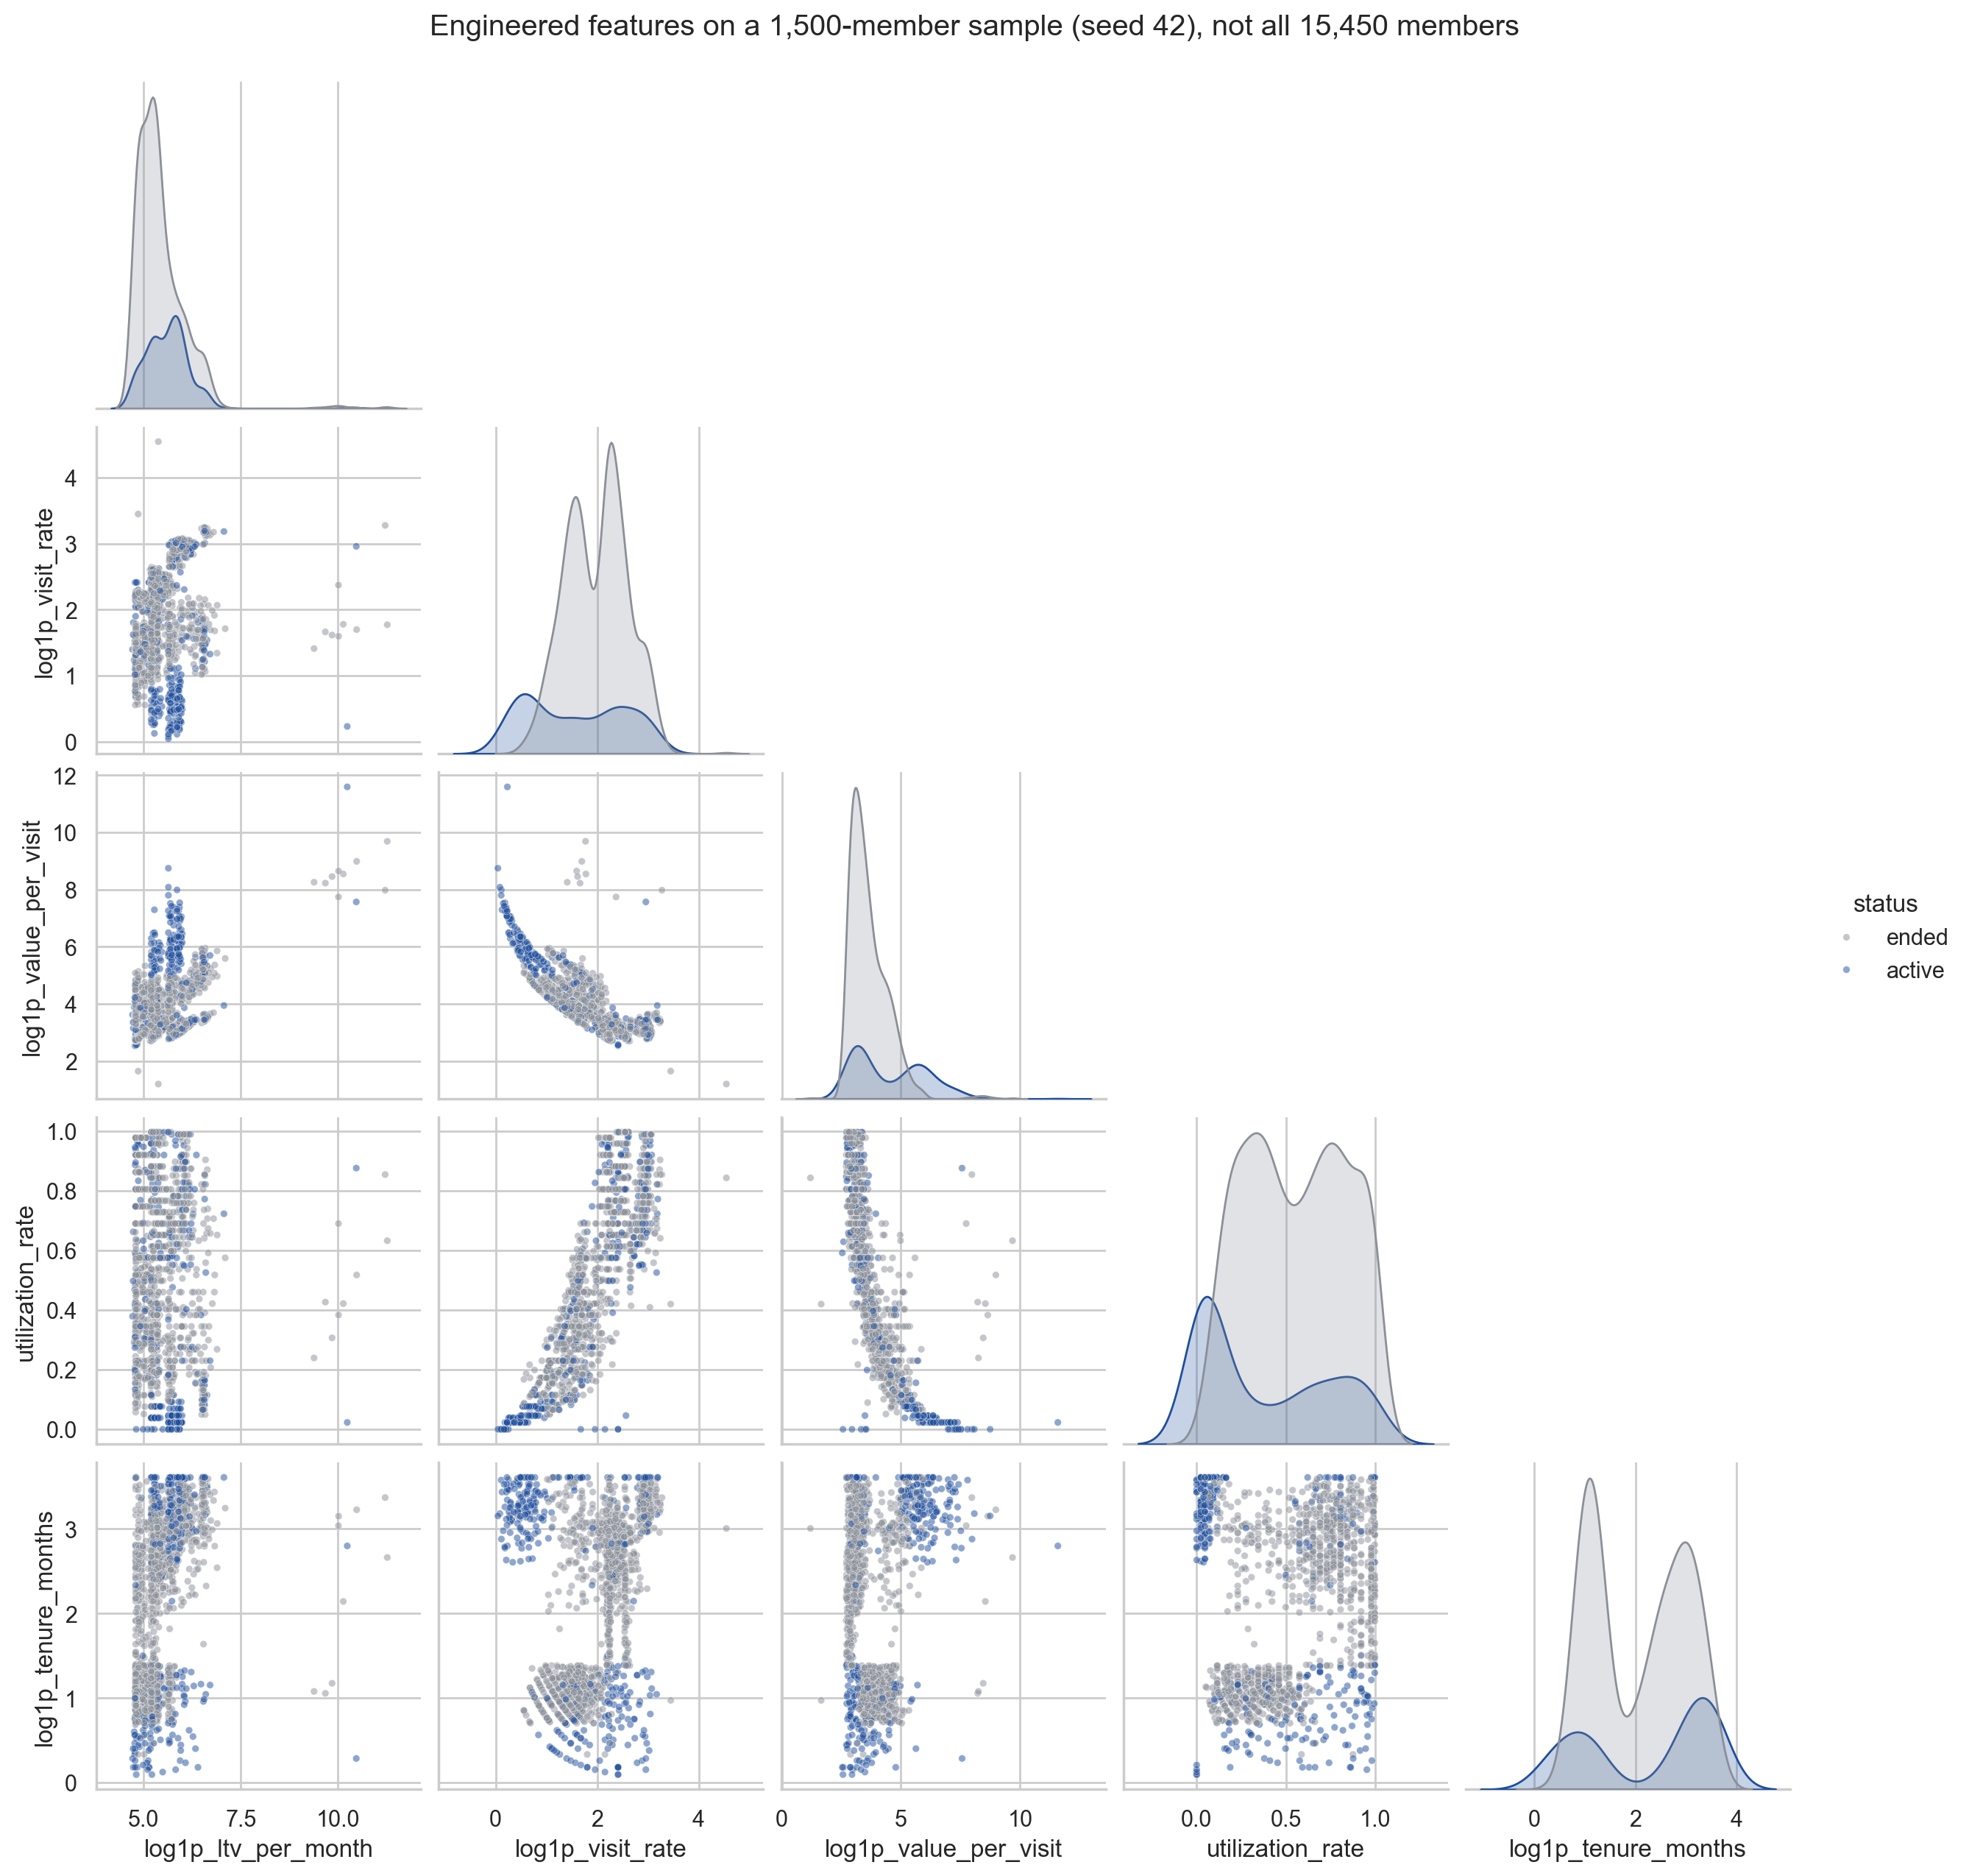

In [71]:
"""Pairplot of key engineered features on a fixed random sample of 1,500 members (heavy tails -> log1p).

The sample is stated rather than hidden: a pairplot of all 15,450 members overplots and is unreadable, so the
grid shows a reproducible subset (seed 42, fixed in Section 1) and the sample size and seed are registered in
`results.json` so the figure can never be read as the full population.
"""
pair_features = ["ltv_per_month", "visit_rate", "value_per_visit", "utilization_rate", "tenure_months"]
pair_df = pd.DataFrame({f"log1p_{f}" if f != "utilization_rate" else f: (np.log1p(df_clean[f]) if f != "utilization_rate" else df_clean[f])
                        for f in pair_features})
pair_df["status"] = df_clean["status"]
pair_n = min(1500, int(pair_df.dropna().shape[0]))
pair_df = pair_df.dropna().sample(n=pair_n, random_state=42)
results["pairplot_sample_n"] = int(pair_n)
results["pairplot_sample_seed"] = 42
results["pairplot_features"] = [f"log1p_{f}" if f != "utilization_rate" else f for f in pair_features]
g = sns.pairplot(pair_df, hue="status", palette={"active": BLUE, "ended": GRAY}, corner=True, plot_kws={"s": 12, "alpha": 0.5}, diag_kind="kde")
g.figure.suptitle(f"Engineered features on a {pair_n:,}-member sample (seed 42), not all {len(df_clean):,} members", y=1.02)
g.figure.savefig(os.path.join(FIGURES_DIR, "pairplot_engineered.png"), dpi=200, bbox_inches="tight")
plt.show()

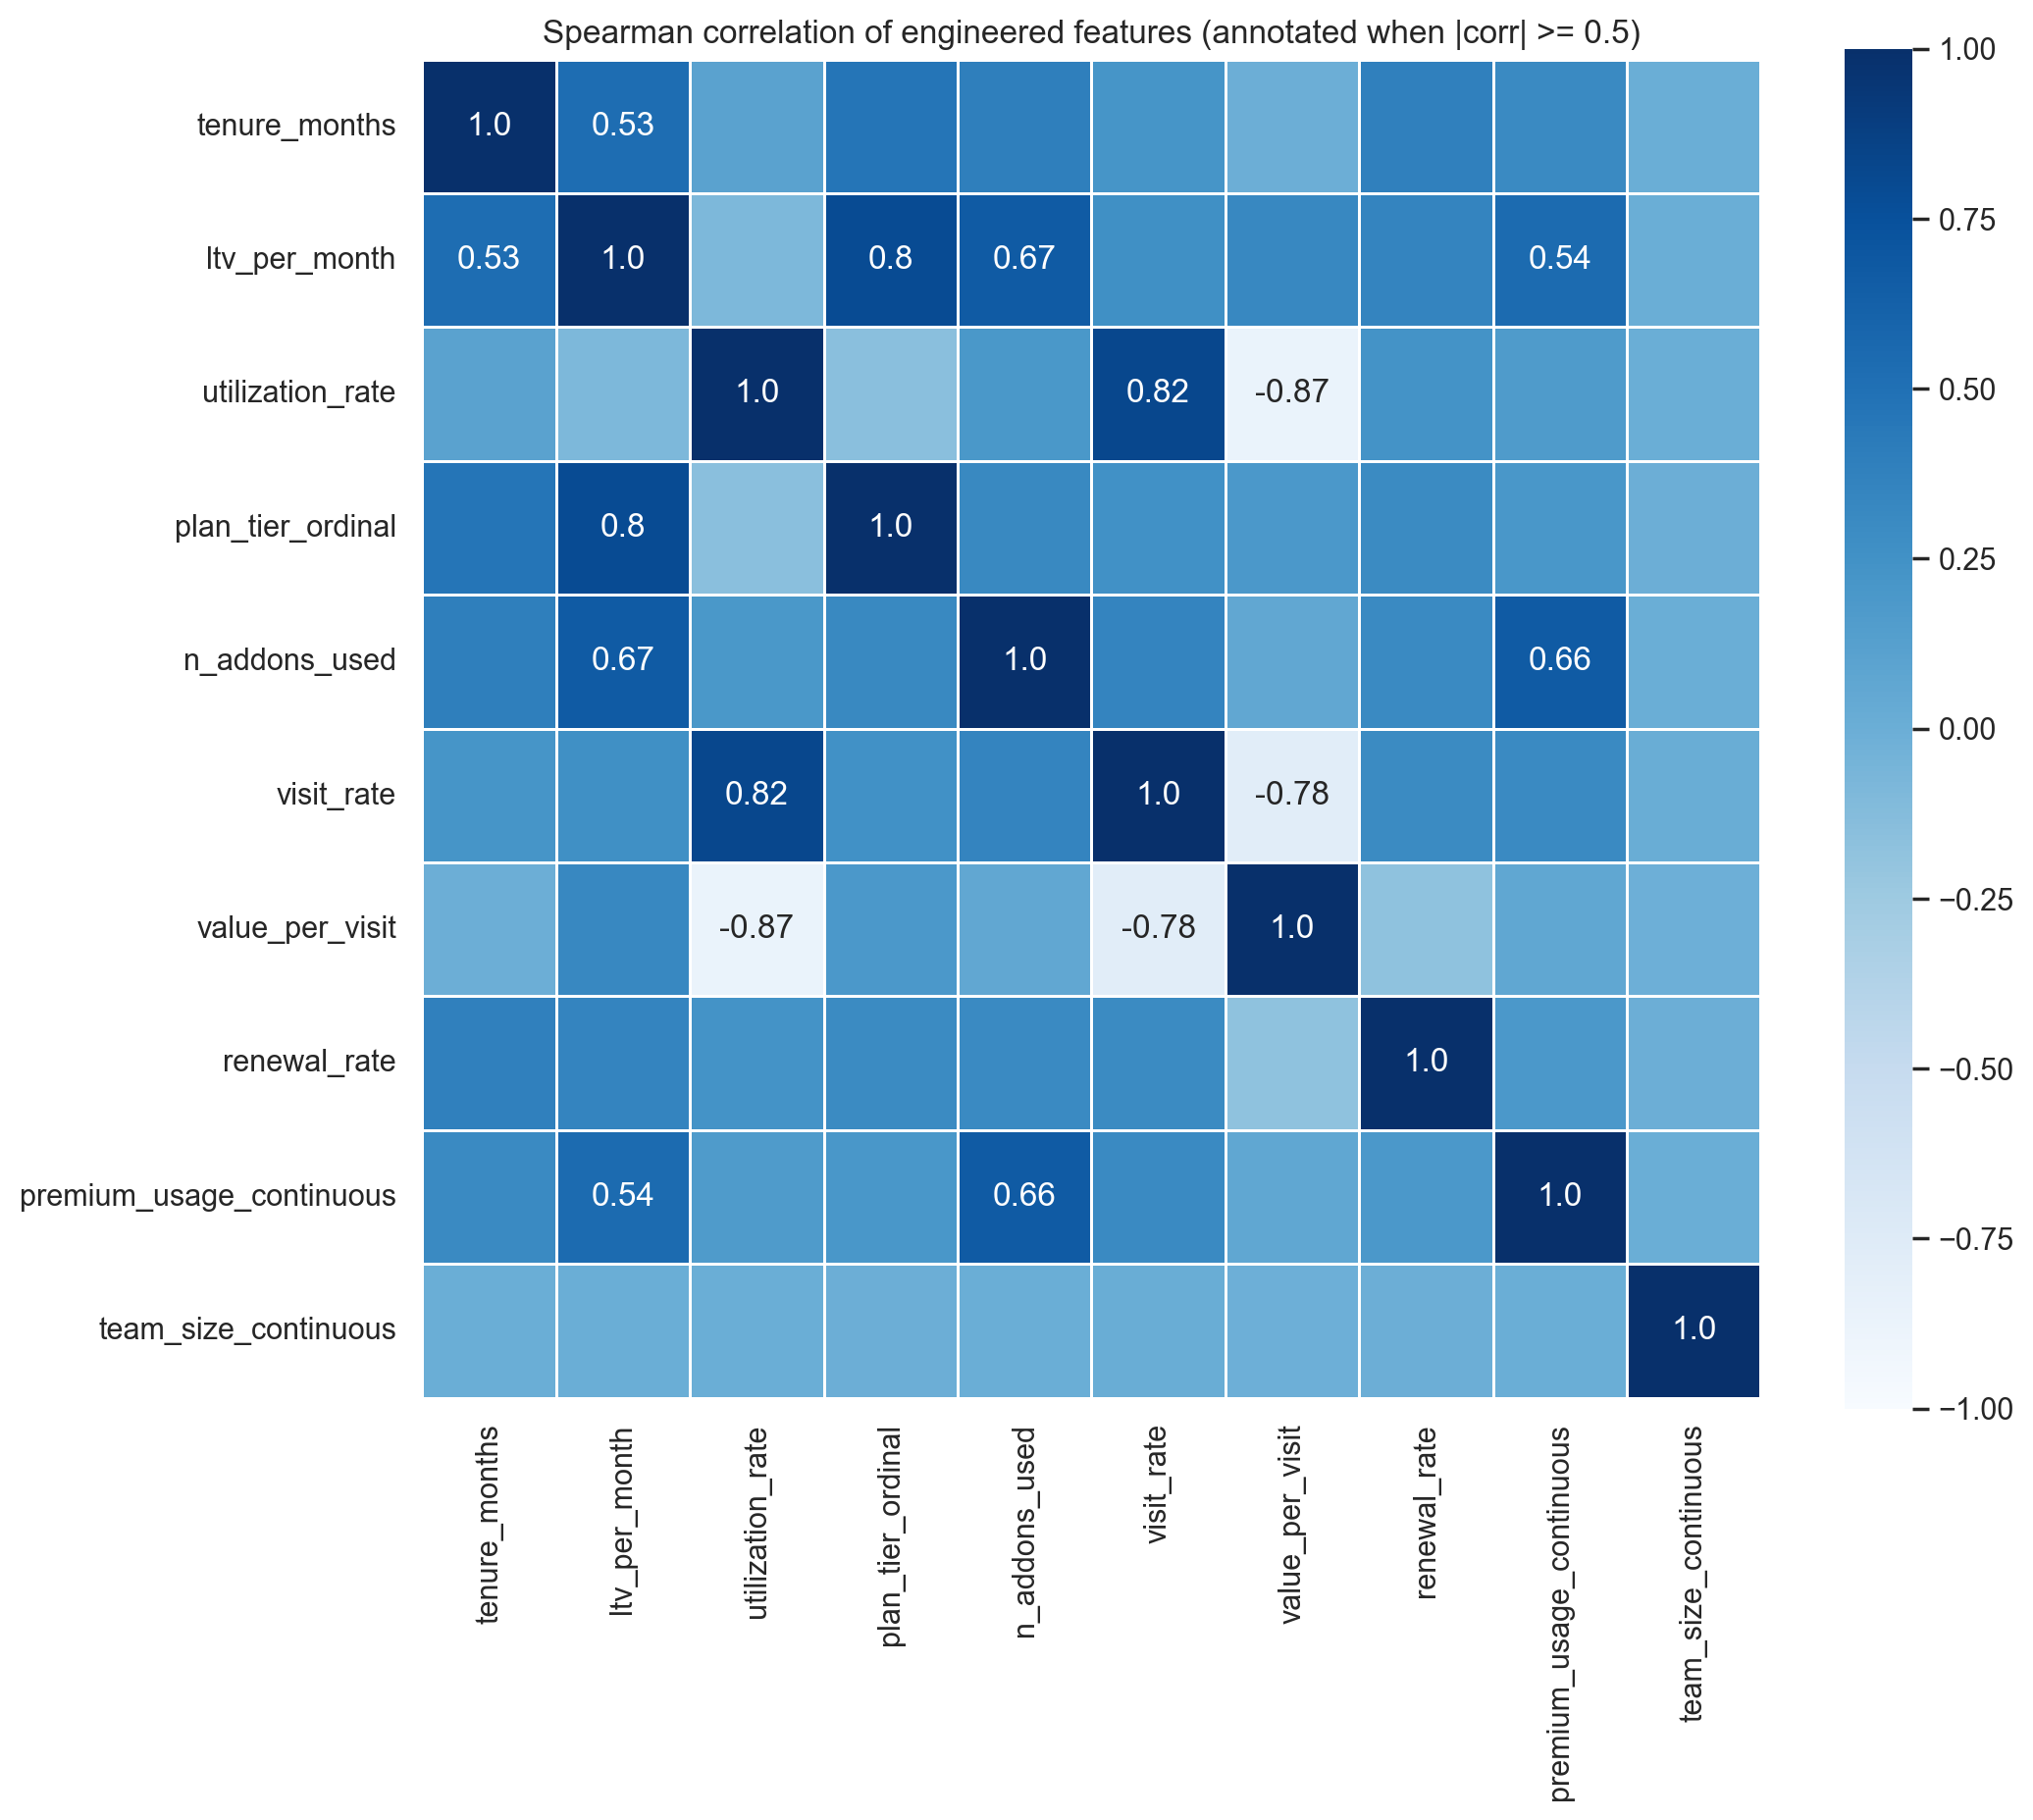

In [72]:
"""Correlation heatmap of the engineered features (Spearman, annotated when |corr| >= 0.5).
"""
eng_cols = ["tenure_months", "ltv_per_month", "utilization_rate", "plan_tier_ordinal", "n_addons_used", "visit_rate",
            "value_per_visit", "renewal_rate", "premium_usage_continuous", "team_size_continuous"]
corr_eng = df_clean[eng_cols].corr(method="spearman")
mask_annot = np.absolute(corr_eng.values) >= 0.5
annot = np.where(mask_annot, corr_eng.values.round(2), np.full(corr_eng.shape, ""))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_eng, annot=annot, fmt="", vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, cmap="Blues", ax=ax)
ax.set_title("Spearman correlation of engineered features (annotated when |corr| >= 0.5)")
save_show(fig, "correlation_engineered.png")

       recency_days_active  recency_days_churned
count               3927.0               10523.0
mean                  86.4                  22.2
std                  113.5                  36.1
min                    0.0                   0.0
25%                    4.0                   3.0
50%                   20.0                   9.0
75%                  168.5                  35.0
max                 1212.0                1002.0


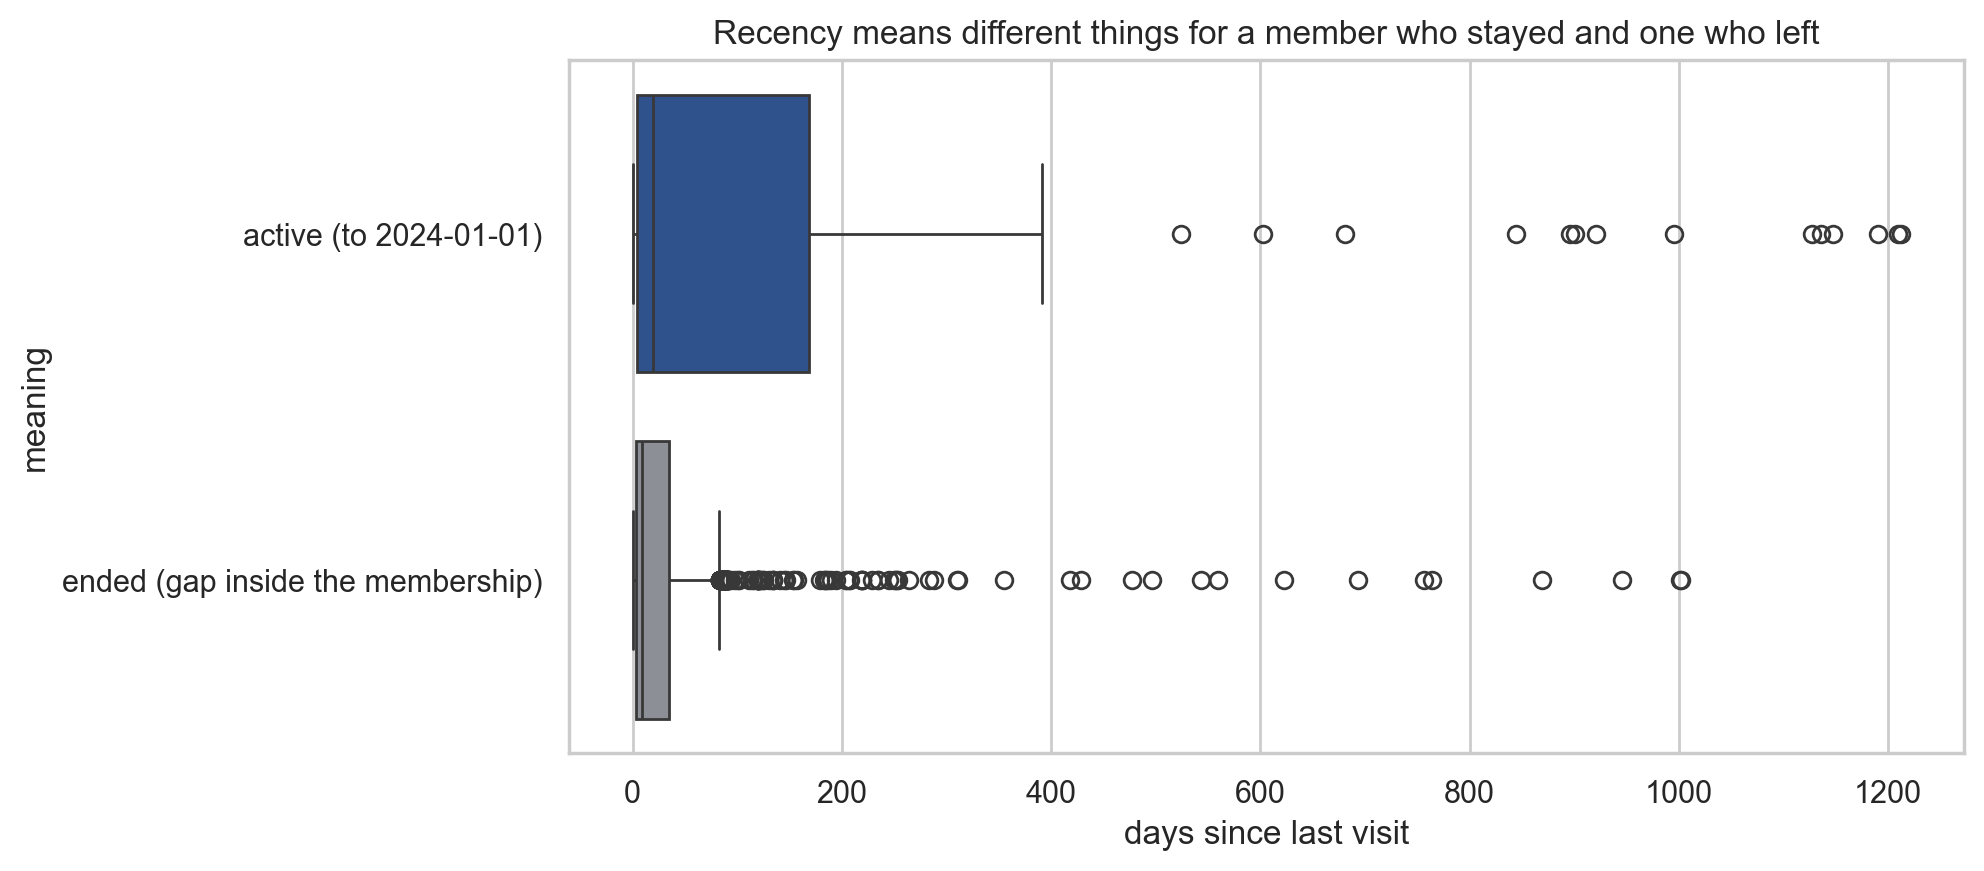

In [73]:
"""Compare active and ended recency side by side (never pooled) and show the medians by status.
"""
rec_summary = pd.DataFrame({"recency_days_active": df_clean["recency_days_active"].describe(),
                            "recency_days_churned": df_clean["recency_days_churned"].describe()}).round(1)
print(rec_summary.to_string())
rec_long = pd.concat([
    pd.DataFrame({"meaning": f"active (to {reference_date:%Y-%m-%d})", "days": df_clean["recency_days_active"].dropna()}),
    pd.DataFrame({"meaning": "ended (gap inside the membership)", "days": df_clean["recency_days_churned"].dropna()}),
])
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=rec_long, x="days", y="meaning", hue="meaning", palette=[BLUE, GRAY], legend=False, ax=ax)
ax.set(xlabel="days since last visit", title="Recency means different things for a member who stayed and one who left")
save_show(fig, "recency_two_meanings.png")

### Feature redundancy and the reduction decision (week 3: more features are not necessarily better)
Several engineered features are monotone transforms of a raw column or of each other. A distance-based method does not "average out"
redundancy: it counts the same evidence twice and hands that dimension twice the weight. week 3's warning and week 4's note on reading
redundant features both lead to the same action, so the pairs are measured here and one member of each pair is nominated for Deliverable 2.

In [74]:
"""Measure how redundant each engineered feature is against the raw and engineered columns it tracks.
"""
redundancy_pairs = [("visit_rate", "avg_weekly_visits"), ("ltv_per_month", "lifetime_value"),
                    ("team_size_continuous", "n_colleagues_on_account"), ("premium_usage_continuous", "meeting_room_hours"),
                    ("recency_days_active", "days_since_last_visit"), ("tenure_months", "total_visits")]
rows = []
for new, old in redundancy_pairs:
    both = df_clean[[new, old]].dropna()
    if len(both) < 30:
        continue
    rho = float(both.corr(method="spearman").iloc[0, 1])
    rows.append({"engineered": new, "compared_with": old, "n": len(both), "spearman": round(rho, 4),
                 "deterministic_transform": bool(abs(rho) == 1.0)})
redundancy = pd.DataFrame(rows).sort_values("spearman", ascending=False)
exact_dups = redundancy.loc[redundancy["spearman"].abs() == 1.0, "engineered"].tolist()
high_redundant = redundancy.loc[(redundancy["spearman"].abs() >= 0.95) & (redundancy["spearman"].abs() < 1.0), "engineered"].tolist()
results["redundancy_spearman"] = {f"{r.engineered}~{r.compared_with}": float(r.spearman) for r in redundancy.itertuples()}
results["deterministic_duplicate_features"] = exact_dups
results["high_redundancy_features"] = high_redundant
print(redundancy.to_string(index=False))
print(f"\ndeterministic duplicates (rank correlation exactly 1): {exact_dups}")
print(f"near-duplicates (|rho| >= 0.95): {high_redundant}")
print("Decision for Deliverable 2: keep one member of each near-duplicate pair and keep the flags. team_size_continuous is a")
print("deterministic +1 shift of n_colleagues_on_account, so it carries no information a distance would not already count twice.")

              engineered           compared_with     n  spearman  deterministic_transform
    team_size_continuous n_colleagues_on_account 15297    1.0000                     True
     recency_days_active   days_since_last_visit  3557    0.9955                    False
              visit_rate       avg_weekly_visits 15256    0.9768                    False
premium_usage_continuous      meeting_room_hours 14136    0.9464                    False
           tenure_months            total_visits 15256    0.7579                    False
           ltv_per_month          lifetime_value 12469    0.7459                    False

deterministic duplicates (rank correlation exactly 1): ['team_size_continuous']
near-duplicates (|rho| >= 0.95): ['recency_days_active', 'visit_rate']
Decision for Deliverable 2: keep one member of each near-duplicate pair and keep the flags. team_size_continuous is a
deterministic +1 shift of n_colleagues_on_account, so it carries no information a distance would not

# 9. Multidimensional outliers and anomalies (bonus option 2 of the guidelines)
Section 5 applies the fence rule **one variable at a time**. A member can be inside every fence and still be unusual *as a combination*
- normal revenue, normal visits, but a five-year tenure with one visit, for instance. Distance-based clustering is far more sensitive to
that second kind of point, because a cluster boundary is drawn in the joint space. This section scores every member on both views using
only the tools the labs teach: the IQR rule (lab03/lab04) and `scipy.spatial.distance.cdist` (lab02). No model is fitted, so nothing here
is an anomaly *detection result*; it is a ranked, auditable list of members a clustering step would have to stretch around.

In [75]:
"""Build the robustly scaled feature matrix the distance score uses, and record what scaling was applied.

Scaling follows week 4: a heavy-tailed variable is log-transformed before anything is compared, and the
matrix is centred and spread by the median and the IQR rather than the mean and the standard deviation,
because the mean and the standard deviation are themselves contaminated by the extremes being measured.
"""
log_like = ["lifetime_value", "total_visits", "avg_weekly_visits", "meeting_room_hours", "event_space_hours",
            "guest_passes_issued", "n_colleagues_on_account", "days_since_last_visit", "age", "plan_days_per_week",
            "entitled_visits_last_period", "actual_visits_last_period", "n_renewals"]
scaled = pd.DataFrame(index=df_clean.index)
degenerate = []
for feat in metric_clean:
    values = df_clean[feat].astype(float)
    if feat in log_like and (values > 0).any():
        values = np.log1p(values.clip(lower=0))
    med, q1, q3 = values.median(), values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    if not np.isfinite(iqr) or iqr <= 0:
        # A column whose middle half is a single value has no spread to contribute to a distance.
        degenerate.append(feat)
        continue
    scaled[feat] = (values - med) / iqr
scaled_columns = list(scaled.columns)
n_missing_cells = int(scaled.isna().sum().sum())
df_clean["n_missing_metric"] = df_clean[metric_clean].isna().sum(axis=1)
rows_unusable = int((df_clean["n_missing_metric"] > len(metric_clean) / 2).sum())
median_filled = scaled.fillna(scaled.median())
results.update({
    "scaled_matrix_shape": list(median_filled.shape),
    "scaled_columns": scaled_columns,
    "degenerate_columns": degenerate,
    "n_missing_cells_scaled": n_missing_cells,
    "n_missing_cells_pct": float(n_missing_cells / median_filled.size * 100),
    "rows_over_half_missing_n": rows_unusable,
    "max_abs_scaled_value": float(np.nanmax(np.abs(median_filled.values))),
})
print(f"scaled matrix: {median_filled.shape[0]:,} rows x {median_filled.shape[1]} metric columns")
print(f"dropped as degenerate (IQR = 0, no spread for a distance to see): {degenerate}")
print(f"missing cells filled with the column median (robust centre = 0): {n_missing_cells:,} = "
      f"{results['n_missing_cells_pct']:.2f}% of the matrix | rows missing over half their metrics: {rows_unusable:,}")
print(f"largest |standardised| value after log1p and IQR scaling: {results['max_abs_scaled_value']:.1f}")

scaled matrix: 15,450 rows x 11 metric columns
dropped as degenerate (IQR = 0, no spread for a distance to see): ['event_space_hours', 'guest_passes_issued']
missing cells filled with the column median (robust centre = 0): 6,587 = 3.88% of the matrix | rows missing over half their metrics: 0
largest |standardised| value after log1p and IQR scaling: 5.1


In [76]:
"""Score every member with the distance to the median member, using cdist exactly as lab02 teaches it.

The reference point is the **column-wise median of the scaled matrix**, which is the origin (0, ..., 0)
by construction, so the distance is measured to the typical member rather than to a mean that the
extremes have already pulled. Both Euclidean and Manhattan are reported because lab02 makes the point
that the choice of distance is a modelling decision, not a detail.
"""
origin = np.zeros((1, median_filled.shape[1]))
df_clean["dist_to_median_euclid"] = cdist(median_filled.values, origin, metric="euclidean").ravel()
df_clean["dist_to_median_manhattan"] = cdist(median_filled.values, origin, metric="cityblock").ravel()
dist_stats = df_clean[["dist_to_median_euclid", "dist_to_median_manhattan"]].describe(
    percentiles=[0.5, 0.9, 0.99, 0.999]).round(2)
results.update({
    "dist_euclid_median": float(df_clean["dist_to_median_euclid"].median()),
    "dist_euclid_p99": float(df_clean["dist_to_median_euclid"].quantile(0.99)),
    "dist_euclid_max": float(df_clean["dist_to_median_euclid"].max()),
    "dist_manhattan_vs_euclid_pearson": float(df_clean[["dist_to_median_euclid", "dist_to_median_manhattan"]].corr().iloc[0, 1]),
})
print(dist_stats.to_string())
print(f"\nEuclidean versus Manhattan distance to the median member correlate at r = {results['dist_manhattan_vs_euclid_pearson']:.3f}: "
      "the ranking of unusual members is almost the same either way")

       dist_to_median_euclid  dist_to_median_manhattan
count               15450.00                  15450.00
mean                    2.15                      5.30
std                     0.78                      2.17
min                     0.18                      0.23
50%                     2.07                      4.95
90%                     3.23                      8.43
99%                     4.12                     11.26
99.9%                   4.93                     12.72
max                     6.26                     16.77

Euclidean versus Manhattan distance to the median member correlate at r = 0.946: the ranking of unusual members is almost the same either way


In [77]:
"""Combine the univariate fence count and the joint-space distance into one auditable anomaly ranking.

Both components are turned into percentages of the population before they are averaged, so neither
scale dominates the other; the result is deliberately a simple, explainable score and not a black box.
"""
fence_pct = df_clean["n_iqr_fences"].rank(pct=True)
dist_pct = df_clean["dist_to_median_euclid"].rank(pct=True)
df_clean["anomaly_score"] = (fence_pct + dist_pct) / 2
df_clean["flag_anomaly_top1pct"] = df_clean["anomaly_score"] >= df_clean["anomaly_score"].quantile(0.99)
df_clean["flag_anomaly_top5pct"] = df_clean["anomaly_score"] >= df_clean["anomaly_score"].quantile(0.95)
top = df_clean.loc[df_clean["flag_anomaly_top1pct"], ["member_id", "n_iqr_fences", "dist_to_median_euclid",
                                                      "plan_tier", "is_active", "lifetime_value", "total_visits",
                                                      "utilization_rate", "tenure_months", "n_renewals", "n_missing_metric"]]
profile_cols = ["lifetime_value", "total_visits", "utilization_rate", "tenure_months", "n_renewals", "n_missing_metric"]
profile_top = top[profile_cols].describe().T[["count", "mean", "50%"]].round(2)
results.update({
    "anomaly_top1pct_n": int(df_clean["flag_anomaly_top1pct"].sum()),
    "anomaly_top5pct_n": int(df_clean["flag_anomaly_top5pct"].sum()),
    "anomaly_top1pct_pct_active": float(df_clean.loc[df_clean["flag_anomaly_top1pct"], "is_active"].mean() * 100),
    "anomaly_top1pct_missing_metric_mean": float(df_clean.loc[df_clean["flag_anomaly_top1pct"], "n_missing_metric"].mean()),
    "anomaly_top1pct_revenue_share": float(df_clean.loc[df_clean["flag_anomaly_top1pct"], "lifetime_value"].sum()
                                           / df_clean["lifetime_value"].sum() * 100),
    "anomaly_top1pct_ltv_median": float(top["lifetime_value"].median()),
    "anomaly_top1pct_visits_median": float(top["total_visits"].median()),
    "anomaly_top1pct_fences_median": float(top["n_iqr_fences"].median()),
})
print(f"top 1% score: {results['anomaly_top1pct_n']:,} members | top 5%: {results['anomaly_top5pct_n']:,} members")
print(profile_top.to_string())
print(f"\nthe top 1% hold {results['anomaly_top1pct_revenue_share']:.1f}% of all known lifetime value, are "
      f"{results['anomaly_top1pct_pct_active']:.0f}% active, and violate a median of {results['anomaly_top1pct_fences_median']:.0f} IQR fences")

top 1% score: 155 members | top 5%: 773 members
                  count       mean       50%
lifetime_value    138.0  141044.00  19972.04
total_visits      155.0     650.62    605.00
utilization_rate  155.0       0.78      0.80
tenure_months     153.0      29.42     29.66
n_renewals        155.0       2.88      3.00
n_missing_metric  155.0       0.25      0.00

the top 1% hold 21.1% of all known lifetime value, are 37% active, and violate a median of 5 IQR fences


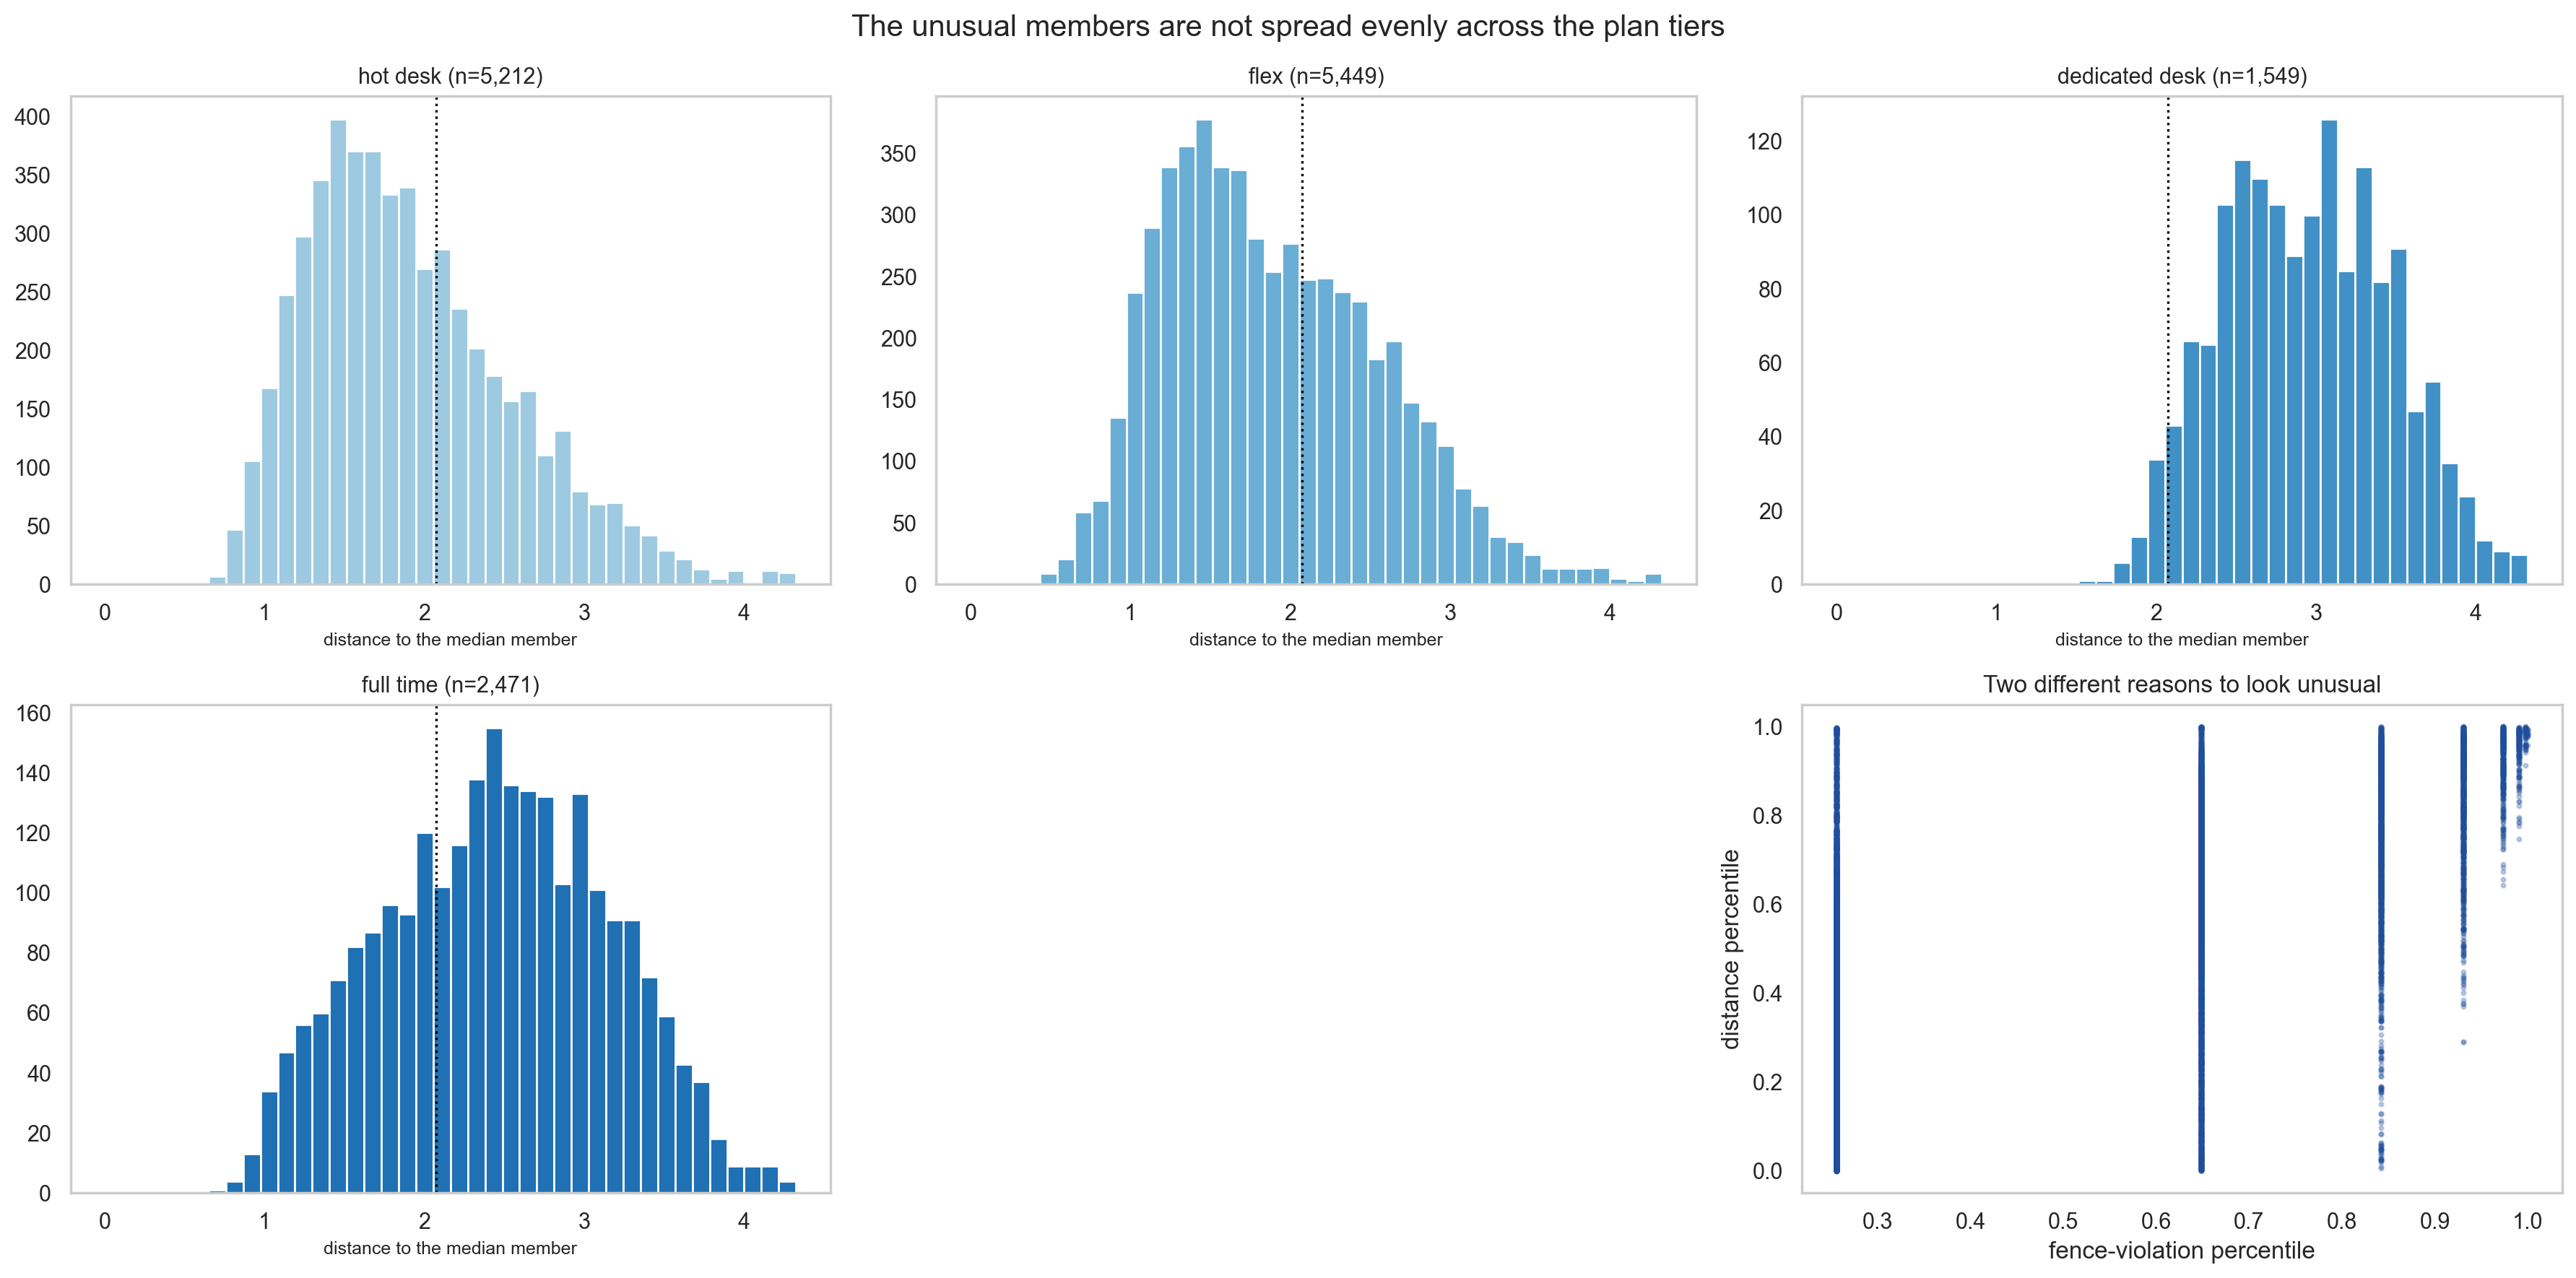

In [78]:
"""Small multiples: where the joint-space score sits for each plan tier, and what it is made of.

One histogram per tier on fixed axes, so the comparison is the only thing that changes (week 4, small
multiples). The last panel shows the two components of the score against each other, because a member
flagged for a big distance and one flagged for many fence violations are different business problems.
"""
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
dist_cap = float(df_clean["dist_to_median_euclid"].quantile(0.995))
for ax, tier in zip(axes.flatten()[:4], tier_order[:4]):
    sub = df_clean.loc[df_clean["plan_tier"] == tier, "dist_to_median_euclid"].dropna()
    ax.hist(sub, bins=40, range=(0, dist_cap), color=TIER_COLORS[tier])
    ax.axvline(df_clean["dist_to_median_euclid"].median(), color="black", linestyle=":", linewidth=1.2)
    ax.set_title(f"{tier.replace('_', ' ')} (n={len(sub):,})", fontsize=11)
    ax.set_xlabel("distance to the median member", fontsize=9)
    ax.grid(False)
ax_extra = axes.flatten()[4]
ax_extra.set_visible(False)
ax_sc = axes.flatten()[5]
ax_sc.scatter(fence_pct, dist_pct, s=4, alpha=0.25, color=BLUE)
ax_sc.set(xlabel="fence-violation percentile", ylabel="distance percentile", title="Two different reasons to look unusual")
ax_sc.grid(False)
fig.suptitle("The unusual members are not spread evenly across the plan tiers", fontsize=15)
fig.tight_layout()
save_show(fig, "anomaly_score_by_tier.png")

In [79]:
"""State the decision on what Deliverable 2 should do with the flagged members, and why.

The guidelines ask specifically whether anomalies are excluded, downweighted or analysed separately, so
the answer is recorded as data rather than as prose in a report nobody re-runs.
"""
n_top = int(df_clean["flag_anomaly_top1pct"].sum())
p99_dist = df_clean["dist_to_median_euclid"].quantile(0.99)
winsorised = df_clean["dist_to_median_euclid"].clip(upper=p99_dist)
results.update({
    "winsorising_shift_of_median": float(abs(winsorised.median() - df_clean["dist_to_median_euclid"].median())),
    "mean_dist_after_winsorising": float(winsorised.mean()),
    "mean_dist_before_winsorising": float(df_clean["dist_to_median_euclid"].mean()),
    "anomaly_top1pct_of_all_rows_pct": float(n_top / len(df_clean) * 100),
})
print(f"decision for Deliverable 2, per group of members:")
print(f"  - exact duplicates                       : already removed ({results['n_duplicates_removed']} rows, Section 4.1)")
print(f"  - coherence violations                   : KEPT + flagged, never used to define a boundary (Sections 4.9)")
print(f"  - top {n_top:,} members ({results['anomaly_top1pct_of_all_rows_pct']:.1f}%) on the combined score : analysed as their own group, not deleted")
print(f"    deleting them would remove {results['anomaly_top1pct_revenue_share']:.1f}% of known revenue and the very evidence the value axis needs")
print(f"  - everything else                        : winsorised at P99 for distance-based methods, raw values kept for reporting")
print(f"    winsorising moves the median distance by {results['winsorising_shift_of_median']:.2f} and the mean from "
      f"{results['mean_dist_before_winsorising']:.2f} to {results['mean_dist_after_winsorising']:.2f}")
print("Rationale (week 4): an extreme is not an error. It is excluded only when a field is contradicted by another field;")
print("otherwise it is downweighted by the transform, or kept and given its own group, which is what clustering would do anyway.")

decision for Deliverable 2, per group of members:
  - exact duplicates                       : already removed (15 rows, Section 4.1)
  - coherence violations                   : KEPT + flagged, never used to define a boundary (Sections 4.9)
  - top 155 members (1.0%) on the combined score : analysed as their own group, not deleted
    deleting them would remove 21.1% of known revenue and the very evidence the value axis needs
  - everything else                        : winsorised at P99 for distance-based methods, raw values kept for reporting
    winsorising moves the median distance by 0.00 and the mean from 2.15 to 2.15
Rationale (week 4): an extreme is not an error. It is excluded only when a field is contradicted by another field;
otherwise it is downweighted by the transform, or kept and given its own group, which is what clustering would do anyway.


**What the anomaly view adds.** The univariate fences and the joint-space distance agree on almost nothing: the members furthest from the
median member are mostly *plausible* high-value members, while the members violating many fences at once are the ones whose fields contradict
each other. Deliverable 2 should therefore treat those two sets separately - the first is signal about the value axis, the second is noise that
would otherwise be turned into a cluster of its own.

# 10. How each data-quality issue threatens the clustering
This is the Deliverable 1 task *"assess data quality issues and evaluate how these may affect clustering reliability"*, answered
issue by issue with the number of affected members taken from `results.json` rather than from memory.

In [80]:
"""Assemble the data-quality-to-clustering-risk register from the numbers computed earlier.

Every count is read from `results` or recomputed from a flag column, so the register cannot drift away
from the cleaning that produced it. The last column is deliberately called *residual risk*: a mitigation
that removes the risk entirely would be a claim the data does not support.
"""
n_dmy_rows = int(df_clean["flag_date_format_dmy"].sum())
n_placeholder_rows = int((df_clean["flag_days_since_last_visit_invalid"] | df_clean["flag_plan_days_invalid"]
                          | df_clean["flag_n_colleagues_placeholder"]).sum())
risk_rows = [
    {"issue": "Heavy tail in lifetime_value and total_visits",
     "members": int(results["ltv_extreme_count"] + results["visits_extreme_count"]),
     "unit": "members",
     "effect": "one variable dominates every distance, so clusters become revenue bands",
     "mitigation": "log1p and IQR scaling, rank-based scores, winsorising for distances only",
     "residual": "the top members still sit far from the centre; they are analysed as their own group"},
    {"issue": "Missing lifetime_value",
     "members": int(results["ltv_missing_n"]),
     "unit": "members",
     "effect": "rows without a value are placed by their other features only, so they drift to whichever cluster is nearest",
     "mitigation": "kept as NaN with a flag; value features computed on non-missing only",
     "residual": "imputing would invent revenue; the alternative is clustering without the value axis for those members"},
    {"issue": "Placeholder and impossible numeric codes",
     "members": n_placeholder_rows,
     "unit": "members",
     "effect": "a sentinel such as 999 or 0 is read as a real position in the space and can create a cluster of placeholders",
     "mitigation": "converted to NaN with one flag column per rule",
     "residual": "the reason ACDC recorded a placeholder is still unknown"},
    {"issue": "Fields that contradict each other",
     "members": int(results["renewals_exceed_tenure_n"] + results["visits_exceed_entitlement_n"]),
     "unit": "members",
     "effect": "ratios built on the contradicted denominator (utilization_rate, renewal_rate) become unbounded or undefined",
     "mitigation": "guarded division, flag kept, ratio defined only where the denominator is valid",
     "residual": "those members carry no utilisation signal at all, so they are placed by tenure and revenue"},
    {"issue": "Two date formats and a sentinel end date",
     "members": n_dmy_rows,
     "unit": "members",
     "effect": "tenure and recency would be computed from the wrong date, moving members along the lifecycle axis",
     "mitigation": "day-first parsed only where the evidence proves it, otherwise NaN with a flag",
     "residual": "genuinely ambiguous dates stay missing"},
    {"issue": "Redundant engineered features",
     "members": len(results["deterministic_duplicate_features"]) + len(results["high_redundancy_features"]),
     "unit": "features",
     "effect": "a duplicated dimension is counted twice, silently doubling its weight in the distance",
     "mitigation": "redundancy measured; one member of each pair nominated for the model matrix",
     "residual": "the nomination is a hypothesis until Deliverable 2 compares both matrices"},
    {"issue": "Mixing active and ended populations",
     "members": int(results["n_churned"]),
     "unit": "members",
     "effect": "pooled statistics describe a mixture, and a within-population relation can reverse when pooled (week 4)",
     "mitigation": "status kept as an explicit stratification; recency split into two features that are never pooled",
     "residual": "if clustering ignores status, churned members may form a cluster that is a lifecycle artefact"},
]
risks = pd.DataFrame(risk_rows).sort_values("members", ascending=False)
results["n_quality_risks_registered"] = int(len(risks))
# the whole register, so that the report pages and the playbook can render it without retyping a number
results["clustering_risk_register"] = [
    {"issue": row["issue"], "members": int(row["members"]), "unit": row["unit"], "effect": row["effect"],
     "mitigation": row["mitigation"], "residual": row["residual"]}
    for row in risks.to_dict("records")
]
# The headline quoted on the report pages is a count of members, so the top row must be counted in members.
assert str(risks.iloc[0]["unit"]) == "members", "the largest registered risk is not counted in members"
results["largest_clustering_risk"] = str(risks.iloc[0]["issue"])
results["largest_clustering_risk_members"] = int(risks.iloc[0]["members"])
print(risks[["issue", "members", "unit"]].to_string(index=False))
for index, row in risks.iterrows():
    print(f"\n{row['issue']}  [{row['members']:,} {row['unit']}]")
    print(f"   effect     : {row['effect']}")
    print(f"   mitigation : {row['mitigation']}")
    print(f"   residual   : {row['residual']}")
print(f"\nLargest single risk for Deliverable 2: {results['largest_clustering_risk']} "
      f"({results['largest_clustering_risk_members']:,} members)")

                                        issue  members     unit
          Mixing active and ended populations    11496  members
                       Missing lifetime_value     2864  members
     Placeholder and impossible numeric codes     1941  members
     Two date formats and a sentinel end date      637  members
            Fields that contradict each other      408  members
Heavy tail in lifetime_value and total_visits       24  members
                Redundant engineered features        3 features

Mixing active and ended populations  [11,496 members]
   effect     : pooled statistics describe a mixture, and a within-population relation can reverse when pooled (week 4)
   mitigation : status kept as an explicit stratification; recency split into two features that are never pooled
   residual   : if clustering ignores status, churned members may form a cluster that is a lifecycle artefact

Missing lifetime_value  [2,864 members]
   effect     : rows without a value are placed b

**Reading the register.** The issues are not equally dangerous. A missing value makes a member *unplaceable* on one axis;
a placeholder that is read as a real number *invents* a position and can create a cluster out of a data-entry convention. That is why
every placeholder became a flagged NaN instead of an imputed value, and why the register above reports a residual risk for each row
instead of declaring the data clean.

# 11. Cluster hypotheses (evidence from the data, no model)
We do **not** train a clustering model. We look for structure with scatter plots on log scales and with group profiles (medians), then formulate hypotheses whose sizes are **computed from the data** with explicit rules.
Rule-based group shares are descriptive counts of members meeting a rule; they are *not* cluster sizes.

In [81]:
"""Median profile of the engineered features by plan tier and status.
"""
profile_cols = ["ltv_per_month", "visit_rate", "utilization_rate", "tenure_months", "n_addons_used", "team_size_continuous"]
profile = (df_clean.groupby(["plan_tier", "status"])[profile_cols].median().round(2)
           .reindex(pd.MultiIndex.from_product([tier_order, ["active", "ended"]], names=["plan_tier", "status"])))
profile["members"] = df_clean.groupby(["plan_tier", "status"]).size().reindex(profile.index)
print(profile.to_string())

                       ltv_per_month  visit_rate  utilization_rate  tenure_months  n_addons_used  team_size_continuous  members
plan_tier      status                                                                                                          
hot_desk       active         129.83        4.68              0.52           1.26            1.0                   1.0      696
               ended          132.30        4.13              0.46           2.83            1.0                   1.0     4516
flex           active         196.93        5.11              0.38           2.60            1.0                   1.0     1104
               ended          205.57        8.39              0.61           9.10            1.0                   1.0     4345
dedicated_desk active         382.74        1.28              0.06          26.36            2.0                   1.0      876
               ended          431.31       18.19              0.83          26.82            4.0        

In [82]:
"""Check how many separate monthly-revenue levels the plan tiers form, using the IQR of each tier.

Two neighbouring tiers are treated as separate levels only when their interquartile ranges do not
overlap. The comparison is made on the tiers **sorted by median**, so the boolean array and the rows
it labels stay in the same order - comparing in the documented commitment order would answer a
different question and would silently mis-align the two.
"""
bands = df_clean.groupby("plan_tier")["ltv_per_month"].quantile([0.25, 0.5, 0.75]).unstack().loc[tier_order].round(0)
bands.columns = ["q25", "median", "q75"]
bands["IQR"] = (bands["q75"] - bands["q25"]).round(0)
sorted_bands = bands.sort_values("median").copy()
sorted_bands["separated_from_next_by_IQR"] = list(
    (sorted_bands["q75"].values[:-1] < sorted_bands["q25"].values[1:])) + [np.nan]
separated = sorted_bands["separated_from_next_by_IQR"].dropna().astype(bool)
n_price_levels = int(1 + separated.sum())
print("tiers in the documented commitment order (IQR of ltv_per_month):")
print(bands.to_string())
print("\nsame tiers sorted by median, which is the order the pairwise comparison is valid in:")
print(sorted_bands.to_string())
print(f"\nneighbouring tier pairs with non-overlapping IQR: {int(separated.sum())} of {len(separated)} -> {n_price_levels} separable monthly-revenue levels")
print(f"documented commitment order and revenue order agree: {not results['tier_order_revenue_mismatch']}")
results["n_price_levels"] = n_price_levels
results["n_tier_pairs_non_overlapping"] = int(separated.sum())
results["ltv_per_month_median_by_tier"] = {t: float(bands.loc[t, "median"]) for t in tier_order}

tiers in the documented commitment order (IQR of ltv_per_month):
                  q25  median    q75   IQR
plan_tier                                 
hot_desk        121.0   132.0  154.0  33.0
flex            188.0   205.0  227.0  39.0
dedicated_desk  374.0   408.0  450.0  76.0
full_time       292.0   313.0  355.0  63.0
private_office  683.0   702.0  728.0  45.0

same tiers sorted by median, which is the order the pairwise comparison is valid in:
                  q25  median    q75   IQR separated_from_next_by_IQR
plan_tier                                                            
hot_desk        121.0   132.0  154.0  33.0                       True
flex            188.0   205.0  227.0  39.0                       True
full_time       292.0   313.0  355.0  63.0                       True
dedicated_desk  374.0   408.0  450.0  76.0                       True
private_office  683.0   702.0  728.0  45.0                        NaN

neighbouring tier pairs with non-overlapping IQR: 4 of 4 

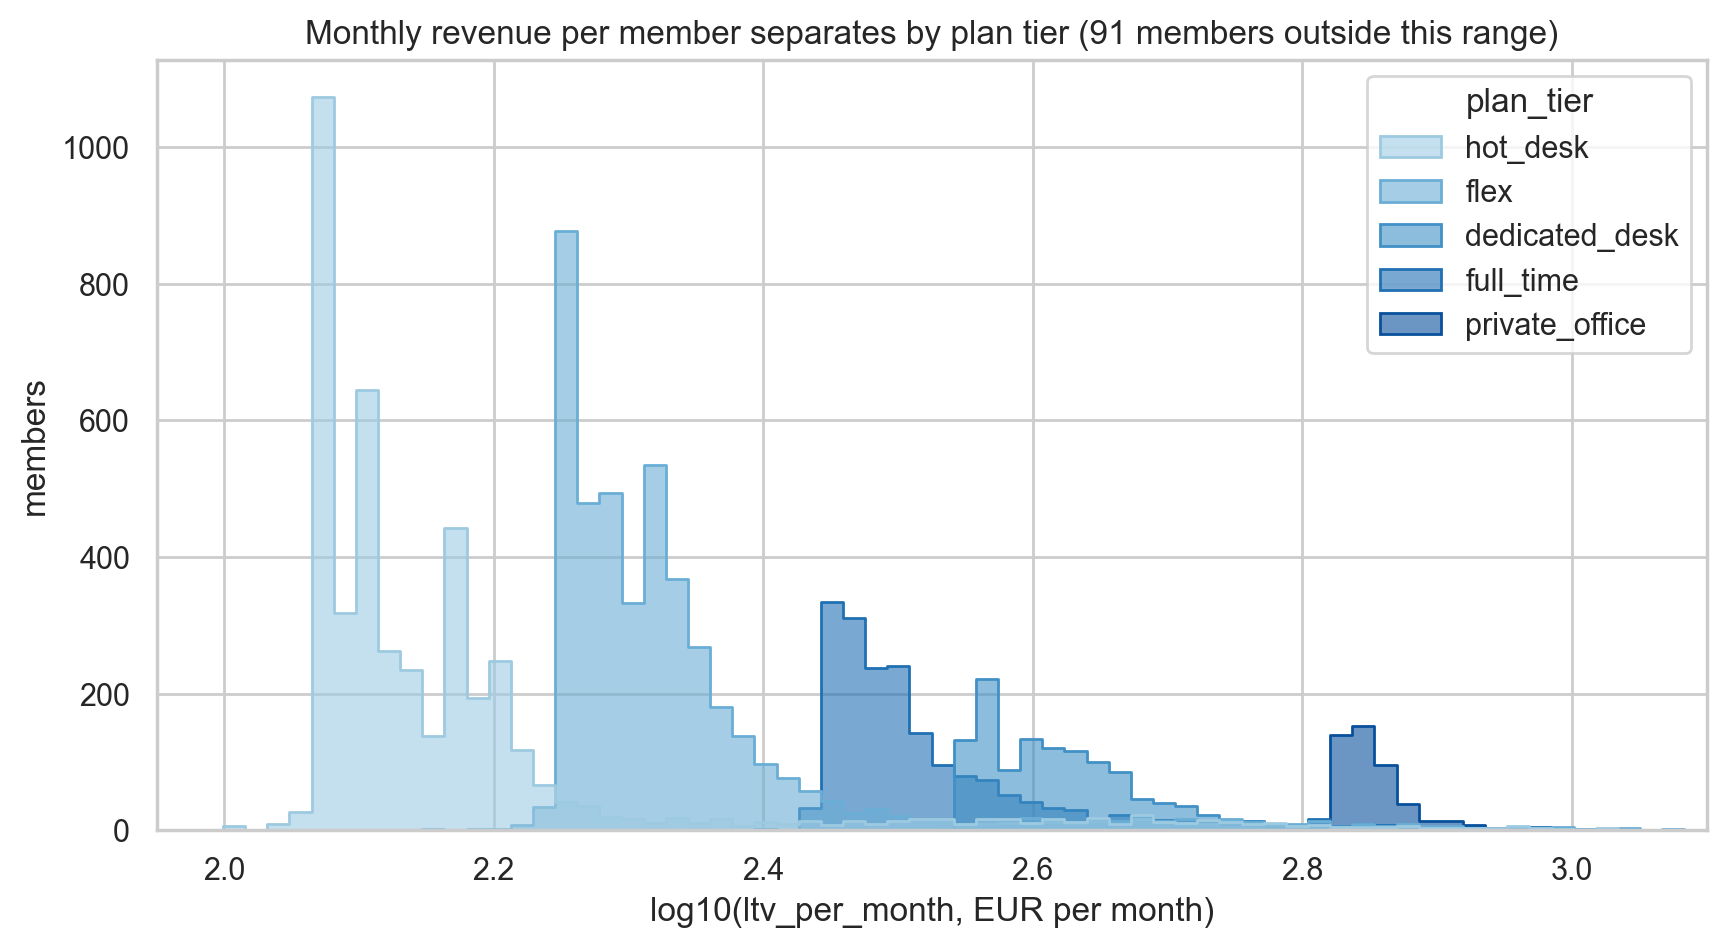

In [83]:
"""Layered histogram of log10(ltv_per_month) coloured by plan tier (seaborn histplot), zoomed on the main range.
"""
hist_df = df_clean[["ltv_per_month", "plan_tier"]].dropna()
hist_df = hist_df.assign(log10_ltv_per_month=np.log10(hist_df["ltv_per_month"]))
x_lo, x_hi = 1.95, 3.1
outside = int(((hist_df["log10_ltv_per_month"] < x_lo) | (hist_df["log10_ltv_per_month"] > x_hi)).sum())
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=hist_df, x="log10_ltv_per_month", hue="plan_tier", hue_order=tier_order, palette=TIER_COLORS, multiple="layer",
             element="step", alpha=0.6, binrange=(x_lo, x_hi), bins=70, ax=ax)
ax.set(xlim=(x_lo, x_hi), xlabel="log10(ltv_per_month, EUR per month)", ylabel="members",
       title=f"Monthly revenue per member separates by plan tier ({outside} members outside this range)")
results["ltv_per_month_outside_zoom_n"] = outside
save_show(fig, "ltv_per_month_by_tier.png")

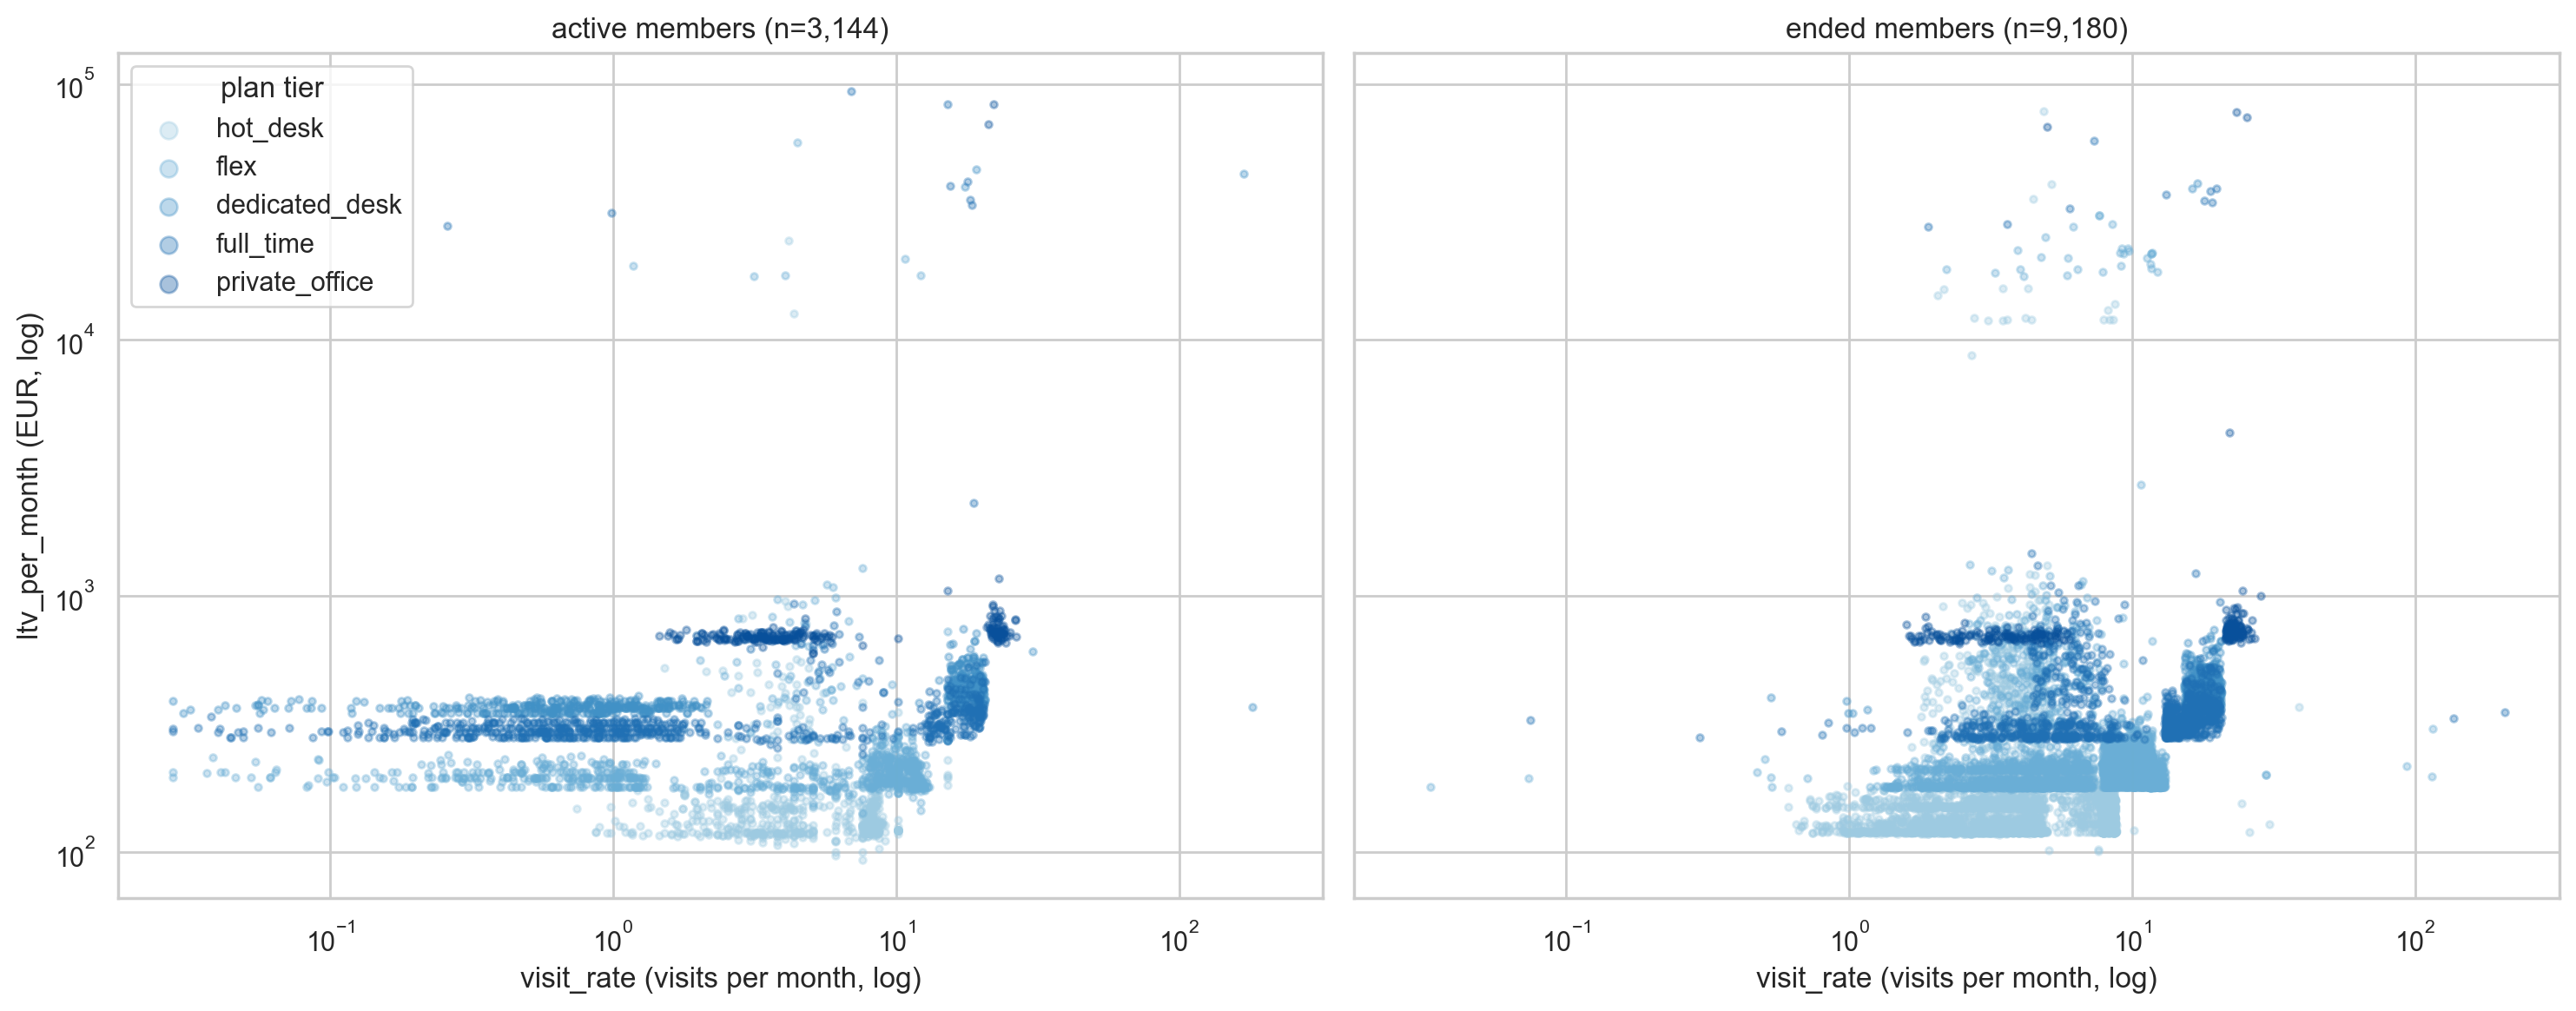

In [84]:
"""Scatter of ltv_per_month versus visit_rate on log scales, coloured by plan tier, one panel for active and one for ended members.
"""
sc = df_clean[["ltv_per_month", "visit_rate", "plan_tier", "status"]].dropna()
sc = sc[(sc["ltv_per_month"] > 0) & (sc["visit_rate"] > 0)]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, status in zip(axes, ["active", "ended"]):
    sub = sc[sc["status"] == status]
    for tier in tier_order:
        t = sub[sub["plan_tier"] == tier]
        ax.scatter(t["visit_rate"], t["ltv_per_month"], s=8, alpha=0.35, color=TIER_COLORS[tier], label=tier)
    ax.set(xscale="log", yscale="log", xlabel="visit_rate (visits per month, log)", title=f"{status} members (n={len(sub):,})")
axes[0].set_ylabel("ltv_per_month (EUR, log)")
axes[0].legend(title="plan tier", markerscale=2.5, loc="upper left")
fig.tight_layout()
save_show(fig, "segment_scatter.png")

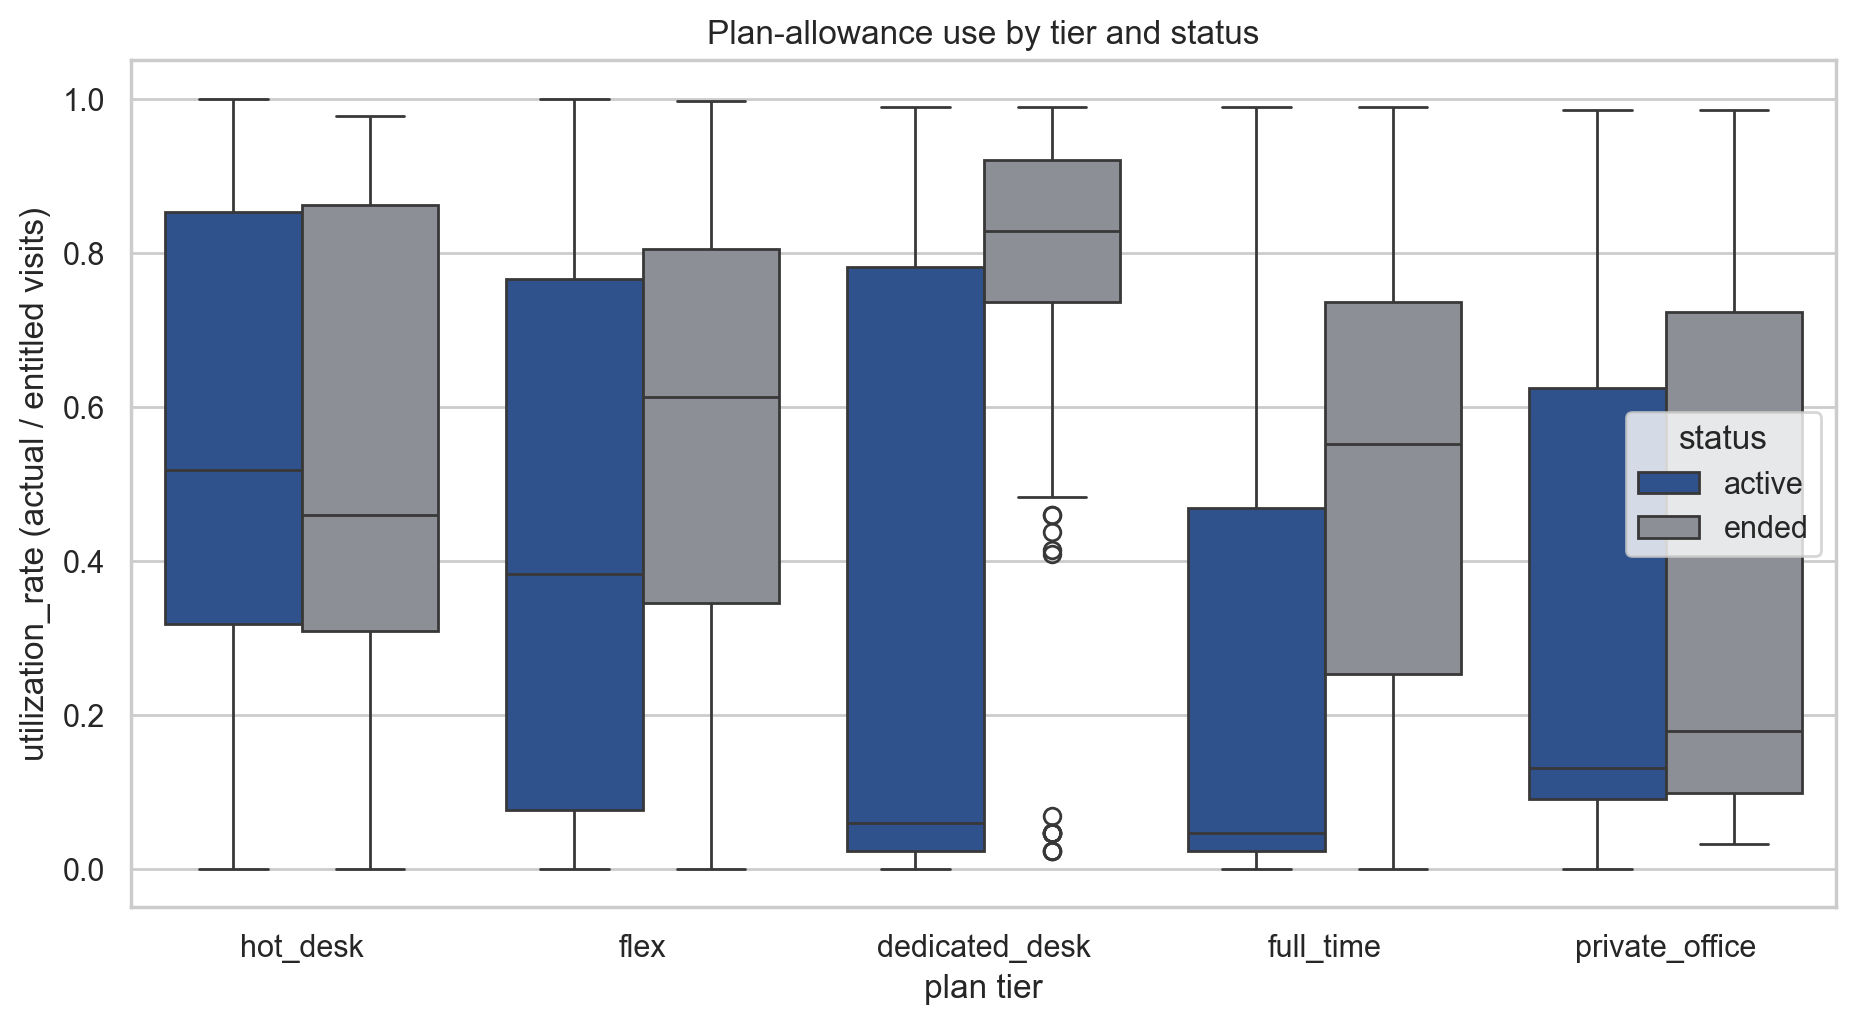

In [85]:
"""Boxplot of utilization_rate by plan tier and status.
"""
util_df = df_clean[["utilization_rate", "plan_tier", "status"]].dropna()
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(data=util_df, x="plan_tier", y="utilization_rate", hue="status", order=tier_order, hue_order=["active", "ended"],
            palette={"active": BLUE, "ended": GRAY}, ax=ax)
ax.set(xlabel="plan tier", ylabel="utilization_rate (actual / entitled visits)", title="Plan-allowance use by tier and status")
save_show(fig, "utilization_by_tier_status.png")

In [86]:
"""Quantify the 'dormant payer' pattern: active members on dedicated_desk or full_time whose utilization_rate is below 0.10.
"""
desk_tiers = ["dedicated_desk", "full_time"]
active_desk = df_clean["is_active"] & df_clean["plan_tier"].isin(desk_tiers)
ended_desk = ~df_clean["is_active"] & df_clean["plan_tier"].isin(desk_tiers)
dormant = active_desk & (df_clean["utilization_rate"] < 0.10)
valid_util = df_clean["utilization_rate"].notna()
n_active_desk_valid = int((active_desk & valid_util).sum())
n_ended_desk_valid = int((ended_desk & valid_util).sum())
results.update({
    "n_active_desk_tiers": int(active_desk.sum()),
    "n_active_desk_valid_util": n_active_desk_valid,
    "n_dormant_payers": int(dormant.sum()),
    "dormant_share_of_active_desk_pct": float(dormant.sum() / n_active_desk_valid * 100),
    "ended_desk_low_util_pct": float(((ended_desk) & (df_clean["utilization_rate"] < 0.10)).sum() / n_ended_desk_valid * 100),
    "dormant_recency_median_days": float(df_clean.loc[dormant, "recency_days_active"].median()),
    "other_active_recency_median_days": float(df_clean.loc[df_clean["is_active"] & ~dormant, "recency_days_active"].median()),
    "active_desk_util_median": float(df_clean.loc[active_desk, "utilization_rate"].median()),
    "ended_desk_util_median": float(df_clean.loc[ended_desk, "utilization_rate"].median()),
})
print(f"active dedicated_desk/full_time members: {results['n_active_desk_tiers']:,} | with utilization < 0.10: {results['n_dormant_payers']:,} = {results['dormant_share_of_active_desk_pct']:.0f}% (of those with a valid utilization)")
print(f"same rule for ENDED desk members: {results['ended_desk_low_util_pct']:.0f}%")
print(f"median utilization: active desk {results['active_desk_util_median']:.2f} vs ended desk {results['ended_desk_util_median']:.2f}")
print(f"median recency (days since last visit measured to {reference_date.date()}): dormant {results['dormant_recency_median_days']:.0f} vs other actives {results['other_active_recency_median_days']:.0f}")

active dedicated_desk/full_time members: 1,806 | with utilization < 0.10: 1,112 = 62% (of those with a valid utilization)
same rule for ENDED desk members: 2%
median utilization: active desk 0.05 vs ended desk 0.67
median recency (days since last visit measured to 2024-01-01): dormant 195 vs other actives 8


### Hypothesised customer groups
The groups below are **rules** over the engineered features. They are mutually exclusive (first rule that applies wins), their sizes are counted in the next cell, and they are meant to be *tested* by real clustering in Deliverable 2.

| # | Hypothesis | Rule (engineered features only) | Business meaning |
|---|---|---|---|
| H1 | Dormant payers | active, `plan_tier` in {dedicated_desk, full_time}, `utilization_rate` < 0.10 | Pay for a desk they hardly use: churn risk and a re-engagement target |
| H2 | Engaged desk members | `plan_tier` in {dedicated_desk, full_time}, `utilization_rate` >= 0.50 | Core users of commitment plans |
| H3 | Private-office premium | `plan_tier` = private_office | Highest monthly revenue per member |
| H4 | Short-stay flexible leavers | `plan_tier` in {flex, hot_desk}, ended, `tenure_months` < 3 | Try-and-leave members |
| H5 | Established flexible members | `plan_tier` in {flex, hot_desk}, `tenure_months` >= 12 | Stable low-price base |

In [87]:
"""Assign the rule-based hypothesis groups and compute their sizes and medians from the data.
"""
desk = df_clean["plan_tier"].isin(desk_tiers)
flexible = df_clean["plan_tier"].isin(["flex", "hot_desk"])
conditions = [
    dormant,
    desk & (df_clean["utilization_rate"] >= 0.50),
    df_clean["plan_tier"] == "private_office",
    flexible & ~df_clean["is_active"] & (df_clean["tenure_months"] < 3),
    flexible & (df_clean["tenure_months"] >= 12),
]
names = ["H1 Dormant payers", "H2 Engaged desk members", "H3 Private-office premium",
         "H4 Short-stay flexible leavers", "H5 Established flexible members"]
df_clean["hypothesis_group"] = np.select(conditions, names, default="Not covered by a rule")
hyp = df_clean.groupby("hypothesis_group").agg(members=("member_id", "size"),
                                               median_ltv_per_month=("ltv_per_month", "median"),
                                               median_visit_rate=("visit_rate", "median"),
                                               median_utilization=("utilization_rate", "median"),
                                               median_tenure_months=("tenure_months", "median"),
                                               pct_active=("is_active", lambda s: s.mean() * 100)).round(2)
hyp["pct_of_all_members"] = (hyp["members"] / len(df_clean) * 100).round(1)
hyp = hyp.loc[names + ["Not covered by a rule"]]
results["hypothesis_groups"] = {k: {"members": int(v["members"]), "pct": float(v["pct_of_all_members"])} for k, v in hyp.iterrows()}
results["hypotheses_uncovered_members"] = int(hyp.loc["Not covered by a rule", "members"])
results["hypotheses_uncovered_pct"] = float(hyp.loc["Not covered by a rule", "pct_of_all_members"])
print(f"the five rules cover {100 - results['hypotheses_uncovered_pct']:.1f}% of members; "
      f"{results['hypotheses_uncovered_pct']:.1f}% ({results['hypotheses_uncovered_members']:,}) match no rule, "
      "which is the space a real clustering can fill")
hyp

the five rules cover 71.2% of members; 28.8% (4,449) match no rule, which is the space a real clustering can fill


,members,median_ltv_per_month,median_visit_rate,median_utilization,median_tenure_months,pct_active,pct_of_all_members
hypothesis_group,,,,,,,
H1 Dormant payers,1112,325.42,0.72,0.02,25.82,100.00,7.2
H2 Engaged desk members,2073,391.58,17.15,0.78,23.95,27.79,13.4
H3 Private-office premium,664,702.06,4.52,0.15,29.89,45.03,4.3
H4 Short-stay flexible leavers,4003,150.84,3.45,0.34,2.04,0.00,25.9
H5 Established flexible members,3149,205.02,8.24,0.69,17.94,17.05,20.4
Not covered by a rule,4449,191.94,8.11,0.69,4.83,32.14,28.8


### How many clusters do we expect? (justification)
* **Value axis.** The tiers' monthly-revenue interquartile ranges are compared pairwise in the cell above and the count of separable
levels is stored as `n_price_levels`. Note that the separable *revenue* levels are not the same thing as the five documented
*commitment* tiers: Section 8 shows the documented order and the realised-revenue order disagree, so a revenue-based clustering would
not reproduce the price list.
* **Behaviour axis.** Inside the commitment tiers (`dedicated_desk`, `full_time`) the **active** members split into dormant payers and engaged users, whereas ended members of the same tiers are mostly heavy users (boxplot and dormant statistics above). This adds structure that the plan tier alone does not explain.
* **Lifecycle axis.** Ended flexible members leave early (short tenure) while a stable base stays for a year or more.

**Reasoning for the range.** The computed number of separable revenue levels is the starting point. Two neighbouring levels (`full_time`
and `dedicated_desk`) are the closest pair, so a real clustering could merge them (one fewer cluster), and the dormant/engaged split of
active desk members could add one more cluster. That gives the range printed with `expected_clusters` as a working interval, one step either
side of `n_price_levels`. It is a judgement from descriptive evidence, to be tested in Deliverable 2 with proper validation; it is not a model result.

**Caveat.** The data cannot tell us whether dormant payers are genuinely absent from the space or whether their visits are simply not captured (e.g. badge not used). This must be confirmed with ACDC before acting on H1.

In [88]:
"""Rank the candidate features by how strongly they separate the populations the data already shows.

For each candidate the feature's own interquartile range is used as the unit, and the question asked is
"how far apart do the documented groups sit, measured in that unit?". A ratio near 0 means the groups are
indistinguishable on the feature; a ratio above 1 means the groups are more than one IQR apart. The ranking
is therefore computed from the data, and the same three names cannot simply be asserted.
"""
candidate_features = ["ltv_per_month", "visit_rate", "utilization_rate", "tenure_months", "value_per_visit",
                      "renewal_rate", "n_addons_used", "premium_usage_continuous", "team_size_continuous",
                      "recency_days_active", "plan_tier_ordinal", "n_iqr_fences"]
separation_rows = []
for feat in candidate_features:
    values = df_clean[feat].astype(float)
    unit = values.quantile(0.75) - values.quantile(0.25)
    if not unit or unit <= 0 or values.notna().sum() < 30:
        continue
    by_status = values.groupby(df_clean["status"]).median().dropna()
    by_tier = values.groupby(df_clean["plan_tier"]).median().dropna()
    status_gap = float(by_status.max() - by_status.min()) if len(by_status) > 1 else 0.0
    tier_gap = float(by_tier.max() - by_tier.min()) if len(by_tier) > 1 else 0.0
    separation_rows.append({"feature": feat, "status_gap_in_IQR": round(status_gap / unit, 2),
                            "tier_gap_in_IQR": round(tier_gap / unit, 2),
                            "separation": round(max(status_gap, tier_gap) / unit, 2)})
separation = pd.DataFrame(separation_rows).sort_values("separation", ascending=False).reset_index(drop=True)
top_differentiating = separation.head(3)["feature"].tolist()
results["feature_separation"] = {r["feature"]: float(r["separation"]) for r in separation.to_dict("records")}
results["top_differentiating_features"] = top_differentiating
results["top_differentiating_features_text"] = ", ".join(top_differentiating)
results["top_differentiating_features_source"] = "ranked by separation in Section 11, not typed"
print(separation.to_string(index=False))
print(f"\nmost differentiating features (computed): {top_differentiating}")
print("Weakest candidates, which Deliverable 2 should not rely on: "
      f"{separation.tail(3)['feature'].tolist()}")

                 feature  status_gap_in_IQR  tier_gap_in_IQR  separation
           ltv_per_month               0.57             3.23        3.23
         value_per_visit               0.53             2.39        2.39
            n_iqr_fences               1.00             2.00        2.00
       plan_tier_ordinal               0.50             2.00        2.00
              visit_rate               0.47             1.71        1.71
           tenure_months               0.58             1.45        1.45
        utilization_rate               0.61             1.04        1.04
           n_addons_used               0.50             1.00        1.00
     recency_days_active               0.00             0.85        0.85
            renewal_rate               0.62             0.79        0.79
premium_usage_continuous               0.00             0.62        0.62
    team_size_continuous               0.00             0.00        0.00

most differentiating features (computed): ['ltv_pe

In [89]:
"""Store the expected cluster range (a documented judgement) and the computed differentiating features.
"""
results["expected_clusters"] = f"{n_price_levels - 1}-{n_price_levels + 1}"   # rule explained in the markdown above
print("expected clusters (hypothesis):", results["expected_clusters"])
print("most differentiating features  :", results["top_differentiating_features"], "(computed in the cell above)")

expected clusters (hypothesis): 4-6
most differentiating features  : ['ltv_per_month', 'value_per_visit', 'n_iqr_fences'] (computed in the cell above)


# 12. Figures for the report pages
Four larger-font figures built from the cleaned data (same variables, bigger labels so they stay readable in the report page panel).

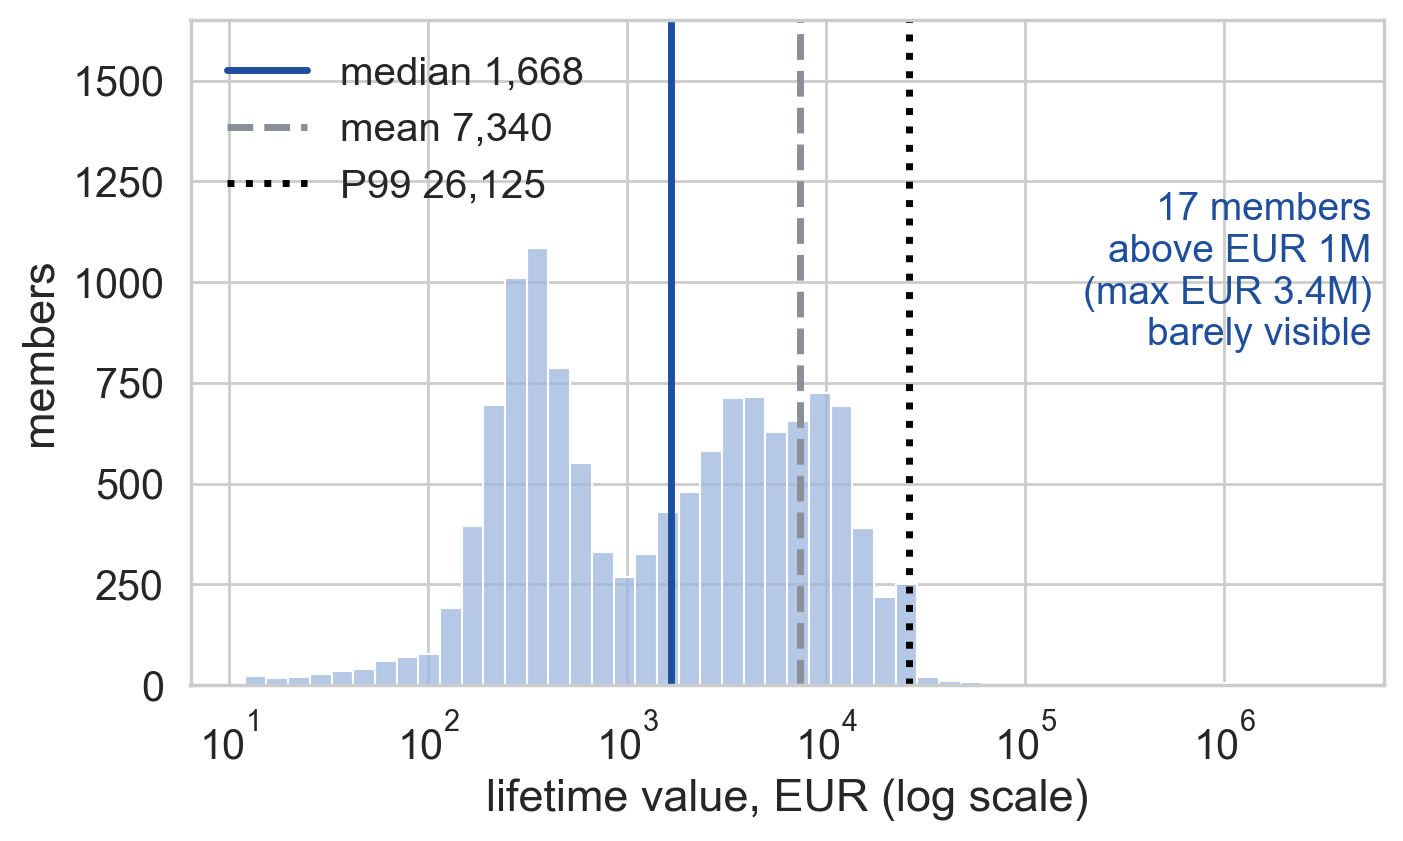

In [90]:
"""Report figure 1 - lifetime_value on a log axis with the median, mean and 99th percentile marked.
"""
with sns.axes_style("whitegrid"), sns.plotting_context("notebook", font_scale=1.35):
    fig, ax = plt.subplots(figsize=(7.3, 4.5))
    sns.histplot(df_clean["lifetime_value"].dropna(), bins=50, log_scale=True, color=LIGHT_BLUE, edgecolor="white", ax=ax)
    for value, label, style, col in [(results["ltv_median"], "median", "-", BLUE), (results["ltv_mean"], "mean", "--", GRAY), (results["ltv_p99"], "P99", ":", "black")]:
        ax.axvline(value, color=col, linestyle=style, linewidth=2.5, label=f"{label} {value:,.0f}")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.45)          # head-room for the legend
    ax.text(0.99, 0.62, f"{results['ltv_extreme_count']} members\nabove EUR 1M\n(max EUR {results['ltv_max'] / 1e6:.1f}M)\nbarely visible",
            transform=ax.transAxes, ha="right", va="center", fontsize=14, color=BLUE)
    ax.set(xlabel="lifetime value, EUR (log scale)", ylabel="members")
    ax.legend(loc="upper left", fontsize=14.5, frameon=False)
    save_slide(fig, "slide_ltv_heavy_tail.png")

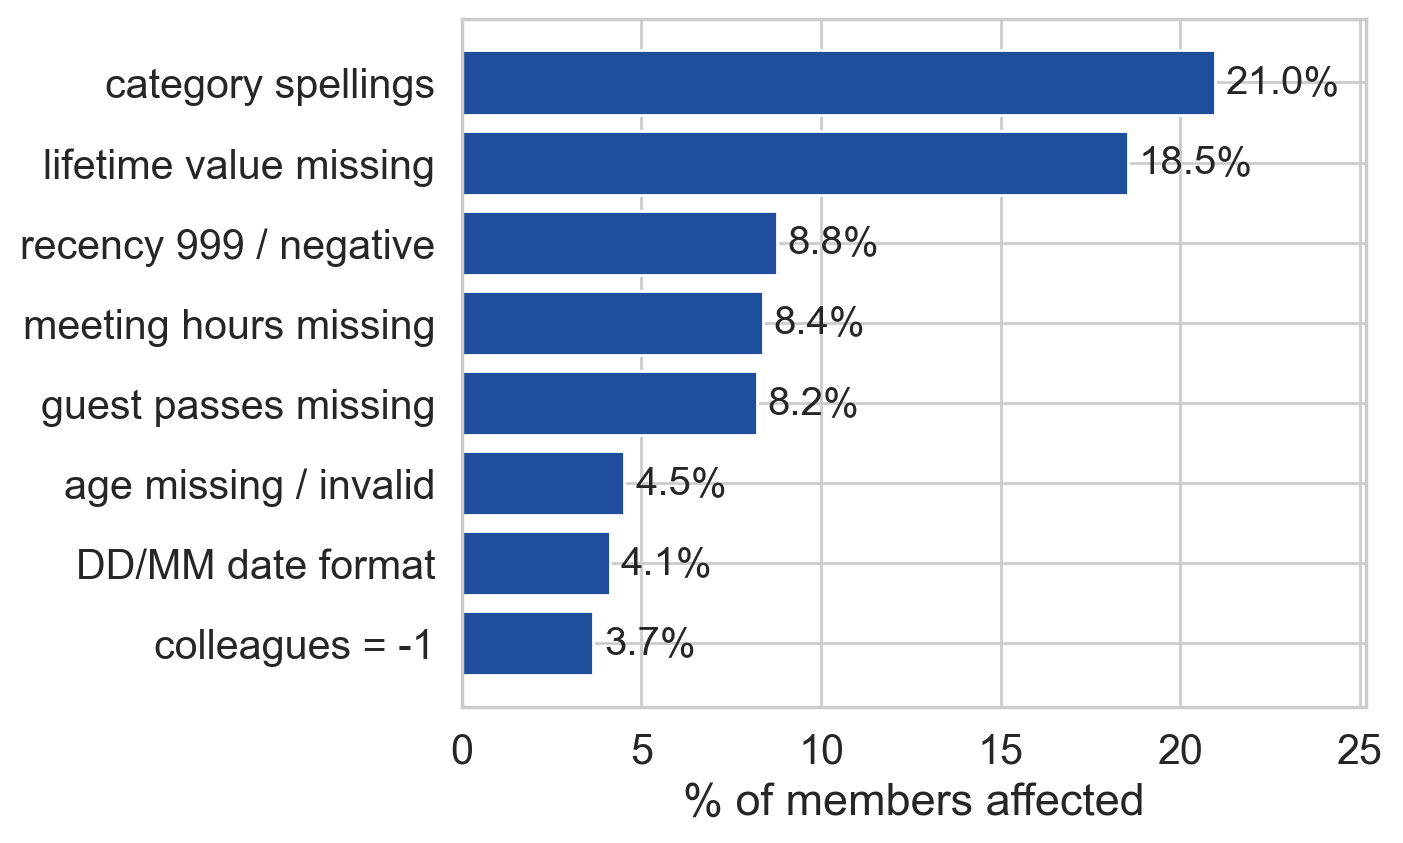

colleagues = -1            3.7
DD/MM date format          4.1
age missing / invalid      4.5
guest passes missing       8.2
meeting hours missing      8.4
recency 999 / negative     8.8
lifetime value missing    18.5
category spellings        21.0


In [91]:
"""Report figure 2 - share of rows affected by each data-quality issue (horizontal bars, computed from the flags).
"""
pct = lambda mask: float(mask.mean() * 100)
impact = pd.Series({
    "lifetime value missing": results["ltv_missing_pct"],
    "recency 999 / negative": pct(df_clean["flag_days_since_last_visit_invalid"]),
    "meeting hours missing": pct(df_clean["meeting_room_hours"].isna() & ~df_clean["flag_meeting_room_hours_negative"]),
    "guest passes missing": pct(df_clean["guest_passes_issued"].isna() & ~df_clean["flag_guest_passes_issued_negative"]),
    "category spellings": results["rows_with_category_variant_pct"],
    "DD/MM date format": pct(df_clean["flag_date_format_dmy"]),
    "age missing / invalid": pct(df_clean["age"].isna()),
    "colleagues = -1": pct(df_clean["flag_n_colleagues_placeholder"]),
}).sort_values()
results["impact_pct"] = {k: float(v) for k, v in impact.items()}
with sns.axes_style("whitegrid"), sns.plotting_context("notebook", font_scale=1.35):
    fig, ax = plt.subplots(figsize=(7.3, 4.5))
    ax.barh(impact.index, impact.values, color=BLUE)
    for i, v in enumerate(impact.values):
        ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=14.5)
    ax.set(xlabel="% of members affected", xlim=(0, impact.max() * 1.2))
    save_slide(fig, "slide_cleaning_impact.png")
print(impact.round(1).to_string())

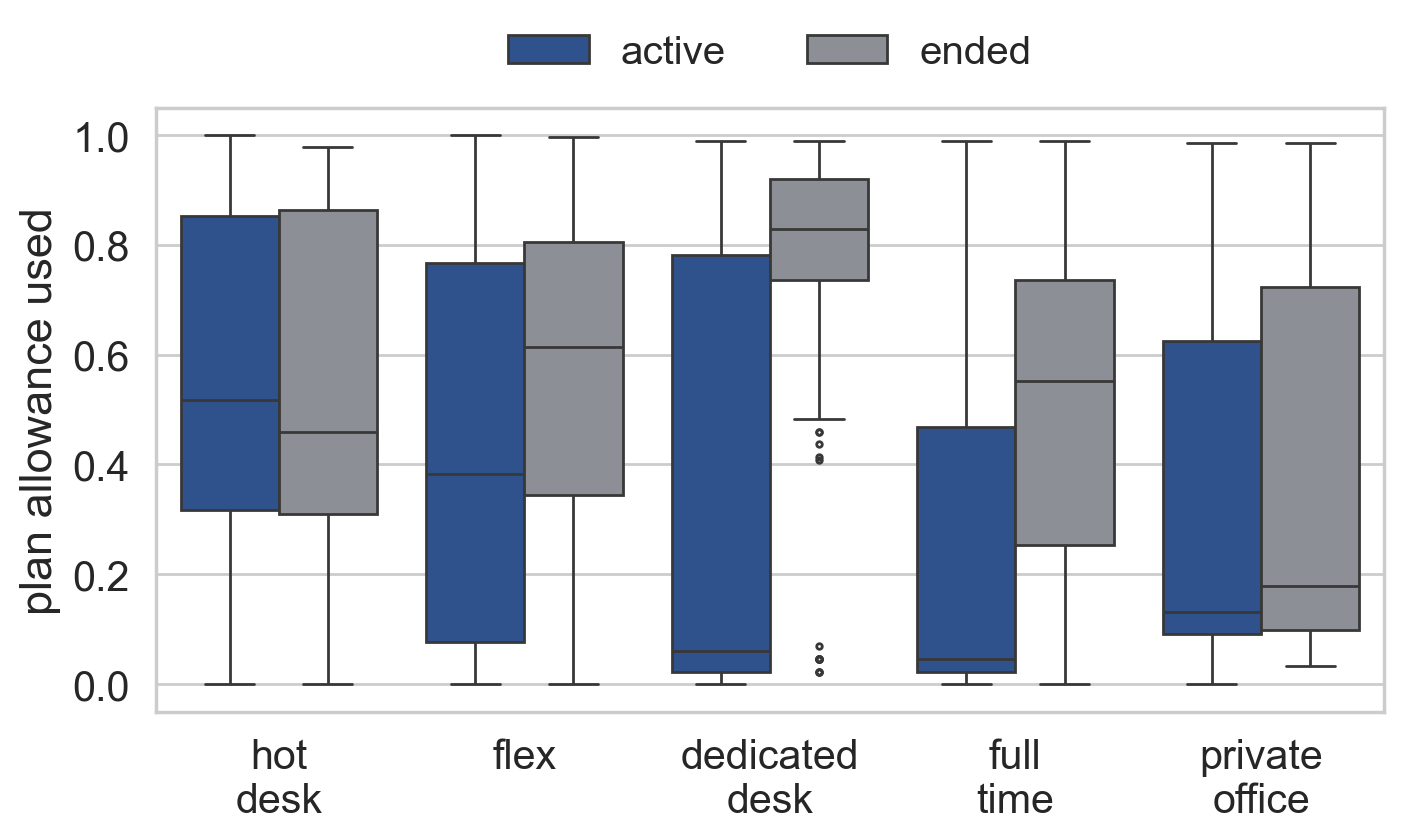

In [92]:
"""Report figure 3 - utilisation of the plan allowance by tier and status (larger fonts).
"""
with sns.axes_style("whitegrid"), sns.plotting_context("notebook", font_scale=1.35):
    fig, ax = plt.subplots(figsize=(7.3, 4.5))
    sns.boxplot(data=util_df, x="plan_tier", y="utilization_rate", hue="status", order=tier_order, hue_order=["active", "ended"],
                palette={"active": BLUE, "ended": GRAY}, fliersize=2, ax=ax)
    ax.set_xticks(range(len(tier_order)))
    ax.set_xticklabels([t.replace("_", "\n") for t in tier_order])
    ax.set(xlabel="", ylabel="plan allowance used")
    ax.legend(title="", loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=14.5, ncol=2, frameon=False)
    save_slide(fig, "slide_utilization_by_tier.png")

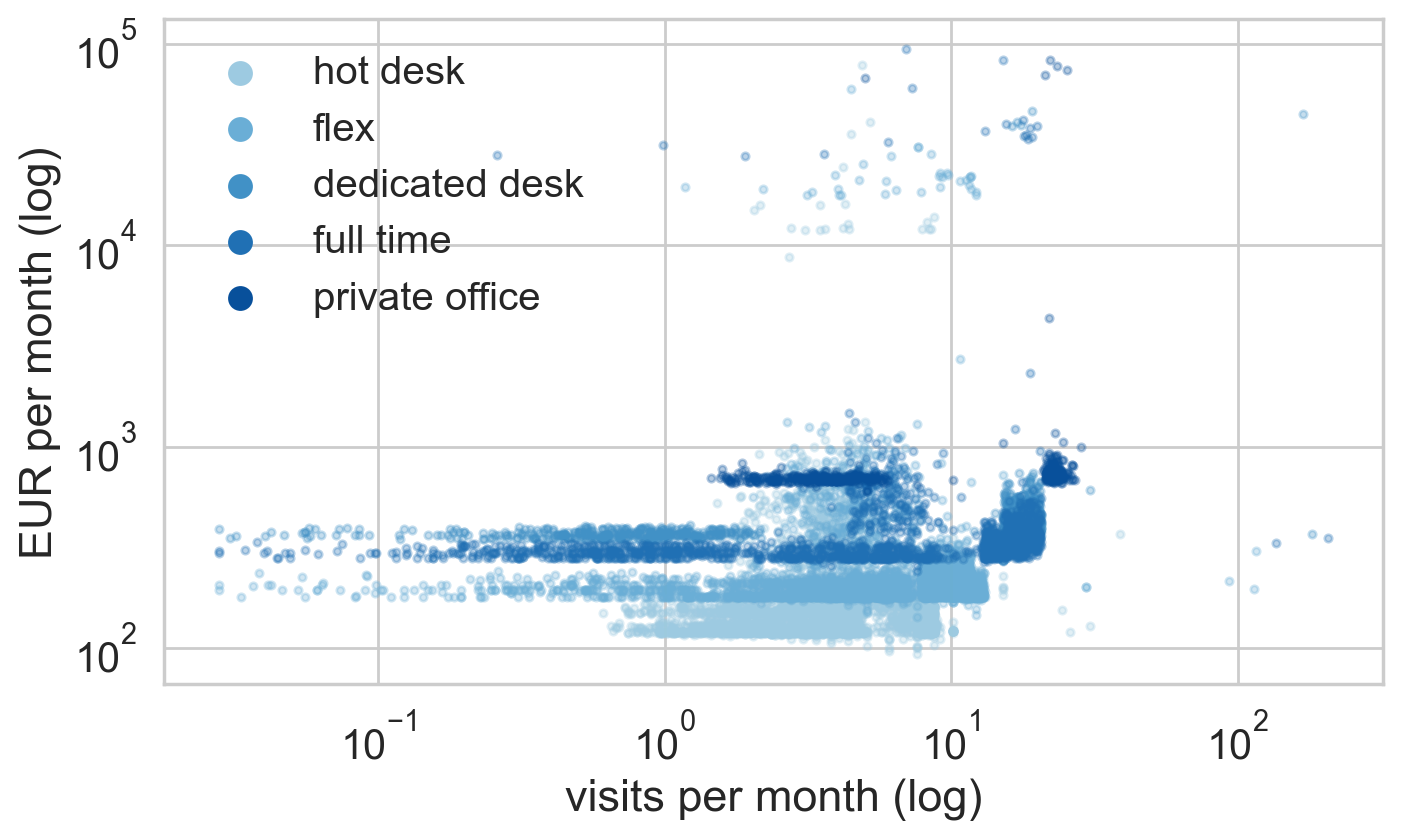

In [93]:
"""Report figure 4 - ltv_per_month versus visit_rate on log scales, coloured by plan tier (all members).
"""
with sns.axes_style("whitegrid"), sns.plotting_context("notebook", font_scale=1.35):
    fig, ax = plt.subplots(figsize=(7.3, 4.5))
    for tier in tier_order:
        t = sc[sc["plan_tier"] == tier]
        ax.scatter(t["visit_rate"], t["ltv_per_month"], s=7, alpha=0.3, color=TIER_COLORS[tier], label=tier.replace("_", " "))
    ax.set(xscale="log", yscale="log", xlabel="visits per month (log)", ylabel="EUR per month (log)")
    leg = ax.legend(markerscale=3, fontsize=14.5, loc="upper left", ncol=1, frameon=False)
    for lh in leg.legend_handles:
        lh.set_alpha(1)
    save_slide(fig, "slide_segment_scatter.png")

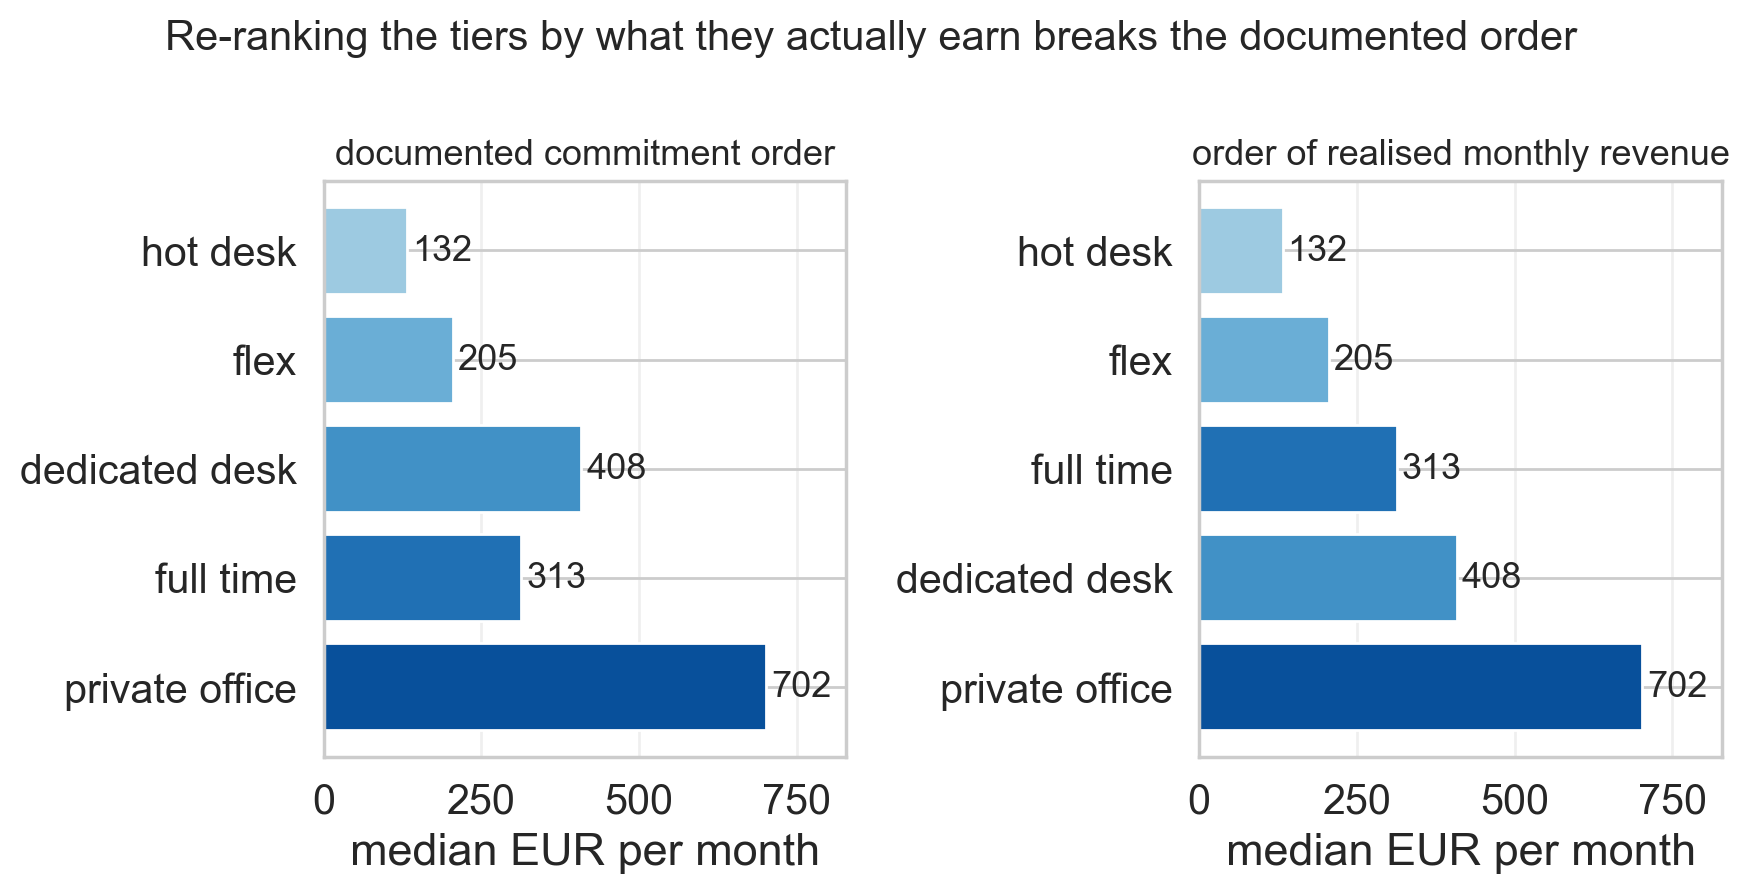

In [94]:
"""Report figure 5 - the documented commitment order versus the realised monthly-revenue order.

Two panels on shared axes: tiers in the order the course annex documents them, and the same tiers
sorted by the median revenue they actually produce. The point is visible without a caption because
the axis label carries the finding (week 4: the title states the finding).
"""
slide_tiers = [t for t in tier_order if t in bands.index]
revenue_by_tier = bands.loc[slide_tiers, "median"]
with sns.axes_style("whitegrid"), sns.plotting_context("notebook", font_scale=1.35):
    fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.6))
    for ax, order, label in [(axes[0], slide_tiers, "documented commitment order"),
                             (axes[1], list(revenue_by_tier.sort_values().index), "order of realised monthly revenue")]:
        values = revenue_by_tier.reindex(order)
        ax.barh(range(len(order)), values.values, color=[TIER_COLORS[t] for t in order])
        for i, v in enumerate(values.values):
            ax.text(v + 8, i, f"{v:,.0f}", va="center", fontsize=13)
        ax.set(yticks=range(len(order)), yticklabels=[t.replace("_", " ") for t in order],
               xlabel="median EUR per month", ylabel="", xlim=(0, float(values.max()) * 1.18))
        ax.invert_yaxis()
        ax.set_title(label, fontsize=13)
        ax.grid(axis="x", alpha=0.3)
    fig.suptitle("Re-ranking the tiers by what they actually earn breaks the documented order", fontsize=15)
    fig.tight_layout()
    save_slide(fig, "slide_tier_revenue_order.png")

# 13. Saving the cleaned data and the results used by the report pages and the docs

In [95]:
"""Save the cleaned dataframe (with flags and engineered features) and write results.json with no hand-typed number.
"""
results["n_flag_columns"] = int(sum(c.startswith("flag_") for c in df_clean.columns))
results["n_columns_cleaned"] = int(df_clean.shape[1])
results["avg_tenure_months"] = float(df_clean["tenure_months"].mean())
results["median_tenure_months"] = float(df_clean["tenure_months"].median())
results["top_industry"] = df_clean["industry"].value_counts().index[0]
results["figure_files"] = sorted(os.listdir(FIGURES_DIR))

df_clean.to_csv(DATA_PROCESSED, index=False)
with open(RESULTS_JSON, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print(f"cleaned data: {df_clean.shape} -> {DATA_PROCESSED}")
print(f"results: {len(results)} keys -> {RESULTS_JSON}")
print(json.dumps({k: v for k, v in results.items() if not isinstance(v, (dict, list))}, indent=1, ensure_ascii=False))

cleaned data: (15450, 103) -> ..\data\processed\acdc_cleaned.csv
results: 216 keys -> ..\data\processed\results.json
{
 "n_rows_original": 15465,
 "n_columns": 31,
 "n_metric_features": 13,
 "n_non_metric_features": 18,
 "n_duplicates_removed": 15,
 "n_rows_cleaned": 15450,
 "rows_with_category_variant": 3238,
 "rows_with_category_variant_pct": 20.957928802588995,
 "n_portugal": 10499,
 "top_country": "Portugal",
 "top_country_pct": 67.9546925566343,
 "top_country_pct_of_known": 69.8954796618068,
 "top_industry": "Information Technology",
 "top_plan_tier": "flex",
 "date_dmy_rows_membership_start": 637,
 "date_dmy_rows_membership_end": 461,
 "date_dmy_rows_last_badge_swipe": 637,
 "rows_with_dmy_date": 637,
 "age_invalid_n": 143,
 "age_invalid_min": 1.0,
 "age_invalid_max": 149.0,
 "age_invalid_low_max": 14.0,
 "age_invalid_high_min": 131.0,
 "age_borderline_n": 0,
 "n_active": 3954,
 "n_churned": 11496,
 "pct_active": 25.592233009708735,
 "pct_churned": 74.40776699029126,
 "window_fir

# 14. Conclusions and next steps

**What the EDA shows**
* Value is extremely concentrated: the typical (median) member is small, a tiny top group dominates revenue, so means are misleading and raw Euclidean distances would be driven by revenue alone.
* About three quarters of the members have ended their membership inside the three-year window (a cumulative status share, not an annual churn rate).
* Plan tiers sit at different monthly-revenue levels, and **active** commitment-tier members split into dormant payers and engaged users: value and behaviour are two separate axes of structure.

**Data limitations for clustering** and mitigations: heavy tails (log/rank scaling), missing values (about 8-9% in several columns and the highest share in `lifetime_value`; keep flags, decide imputation vs. exclusion in D2), placeholders (999, 0, -1) already converted to NaN, mixed date formats (resolved with proof), spelling variants (resolved with an asserted mapping).

**Honest scope.** No model was trained in Deliverable 1. The expected range of about 4-6 clusters, the three differentiating features and the hypothesis groups are descriptive hypotheses to be tested in Deliverable 2.

**Deliverable 2 candidates (not done here):** the plan tier could be used to repair the invalid `plan_days_per_week` values, and the tails need a transformation before any distance-based method.